# ACDC Cardiac MRI Segmentation

This notebook segments the heart in cardiac MRI scans. We compare two classical pixel classifiers (Logistic Regression and Random Forest) with a U-Net that uses an ImageNet-pretrained ResNet-34 encoder. Then we look at where the models fail, try a few fixes, and finish with a single evaluation on 50 test patients that were never used during development.

**Contents**

1. Problem and data
2. Setup
3. Data checks
4. Patient split and pixel features
5. Preprocessing (5.3 holds the other preprocessing options we tried)
6. Classical models
7. U-Net models
8. Validation results and cost
9. Final model: fine-tuning and selection
10. Final test on 50 unseen patients
11. Final figures
12. Files for the GitHub repository
13. Conclusion

**How to run:** open in Google Colab with a T4 GPU (Runtime → Change runtime type) and run the cells in order. Most training and evaluation cells first check whether their results are already saved in Drive. If they are, the cell reloads them instead of training again, so re-running the notebook does not repeat the long runs or the one-time test.

## <span style="color:#247C87">1. Problem and data</span>

The goal is to label every pixel of a cardiac MRI slice as **background (0), right ventricle (1), myocardium (2) or left ventricle (3)**. ACDC gives us 100 development patients and 50 separate test patients, spread evenly over five groups: normal, previous heart attack, dilated cardiomyopathy, hypertrophic cardiomyopathy, and abnormal right ventricle. Each patient has two annotated time points, end-diastole (ED, heart relaxed) and end-systole (ES, heart contracted).

We split the 100 development patients into 80 for training and 20 for validation, by patient, so the same person never appears on both sides. The 50 test patients were used only once, at the very end, after the final model had been chosen.

We measure quality with the Dice score, which compares the predicted region with the expert's region (1 is a perfect match, 0 is no overlap). Precision and recall help us tell extra predicted tissue apart from missed tissue.

## <span style="color:#247C87">2. Setup</span>

Connect Google Drive, where the dataset and all experiment files live.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Point to the dataset folder and count the patient ZIP files. We expect 100 development patients and 50 test patients.

In [2]:
from pathlib import Path

data_path = Path('/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads')

if data_path.exists():
    print("Training ZIPs:", len(list(data_path.glob('patient*.zip'))))
    print("Testing ZIPs:", len(list((data_path / 'testing').glob('patient*.zip'))))
else:
    print("Folder not found.")

Training ZIPs: 100
Testing ZIPs: 50


Install nibabel, the library that reads the MRI files (they are in NIfTI format, `.nii.gz`).

In [3]:
%pip install -q nibabel

Set the main folders used in the rest of the notebook, so every section reads from and writes to the same places.

In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path('/content/drive/MyDrive/ACDC dataset')
data_path = PROJECT_ROOT / 'ACDC_patient_downloads'
PROC_ROOT = PROJECT_ROOT / 'ACDC_preprocessed_288'
CLASSICAL_DIR = PROJECT_ROOT / 'experiments/random_forest_20261106_151100_091562'
ORIGINAL_CNN_DIR = PROJECT_ROOT / 'ACDC_experiments/unet_resnet34_seed42'
WEIGHTED_CNN_DIR = PROJECT_ROOT / 'ACDC_experiments/unet_resnet34_seed42_rv_weighted'

locations = pd.DataFrame([
    ('Original scans and patient split', str(data_path)),
    ('Processed images, masks and metadata', str(PROC_ROOT)),
    ('Classical models and validation scores', str(CLASSICAL_DIR)),
    ('Original U-Net checkpoints and scores', str(ORIGINAL_CNN_DIR)),
    ('RV-weighted U-Net checkpoints and scores', str(WEIGHTED_CNN_DIR)),
], columns=['Contents', 'Directory'])
with pd.option_context('display.max_colwidth', None):
    display(locations)

,Contents,Directory
0,Original scans and patient split,/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads
1,"Processed images, masks and metadata",/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288
2,Classical models and validation scores,/content/drive/MyDrive/ACDC dataset/experiments/random_forest_20261106_151100_091562
3,Original U-Net checkpoints and scores,/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42
4,RV-weighted U-Net checkpoints and scores,/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted


## <span style="color:#247C87">3. Data checks</span>

**Image and mask checks**

Before doing anything else, we open all 200 annotated volumes (100 patients × 2 phases) and check that each file loads, that the image and mask have the same shape and alignment, that the image has no NaN or infinite values, and that the mask only contains the labels 0 to 3.

In [ ]:
import zipfile, gzip
import nibabel as nib
import numpy as np
import pandas as pd

def load_nifti(archive, name):
    """Read a .nii.gz straight out of the ZIP (in memory, nothing extracted)."""
    return nib.Nifti1Image.from_bytes(gzip.decompress(archive.read(name)))

records, problems = [], []
def flag(pid, phase, issue):
    problems.append({'patient_id': pid, 'phase': phase, 'issue': issue})

zips = sorted(data_path.glob('patient*.zip'))   # training ZIPs only
print("Training ZIPs found:", len(zips))

for zp in zips:
    pid = zp.stem
    try:
        with zipfile.ZipFile(zp) as z:
            names = {n.split('/')[-1]: n for n in z.namelist()}   # filename -> path inside ZIP

            # ED and ES frame numbers come from this patient's own Info.cfg
            if 'Info.cfg' not in names:
                flag(pid, '-', 'Info.cfg missing'); continue
            info = {}
            for line in z.read(names['Info.cfg']).decode().splitlines():
                if ':' in line:
                    k, v = line.split(':', 1)
                    info[k.strip()] = v.strip()
            try:
                phases = {'ED': int(info['ED']), 'ES': int(info['ES'])}
            except Exception as e:
                flag(pid, '-', f'cannot read ED/ES: {e}'); continue

            for phase, frame in phases.items():
                img_name = f'{pid}_frame{frame:02d}.nii.gz'
                msk_name = f'{pid}_frame{frame:02d}_gt.nii.gz'

                # 1) Missing files
                if img_name not in names: flag(pid, phase, 'MRI image missing')
                if msk_name not in names: flag(pid, phase, 'expert mask missing')
                if img_name not in names or msk_name not in names:
                    continue

                # 2) Unreadable files
                try:
                    img_f = load_nifti(z, names[img_name])
                    msk_f = load_nifti(z, names[msk_name])
                    img, msk = img_f.get_fdata(), msk_f.get_fdata()
                except Exception as e:
                    flag(pid, phase, f'could not load: {e}'); continue

                # 3) Alignment: shape and affine
                shape_ok = img.shape == msk.shape
                affine_ok = bool(np.allclose(img_f.affine, msk_f.affine))
                if not shape_ok:  flag(pid, phase, f'shape mismatch: image {img.shape} vs mask {msk.shape}')
                if not affine_ok: flag(pid, phase, 'affine (alignment) differs')

                # 4) Labels: only 0,1,2,3 and whole numbers, plus pixel counts
                values = np.unique(msk)
                labels_ok = set(values.tolist()) <= {0, 1, 2, 3}
                integer_ok = bool(np.allclose(msk, np.round(msk)))
                if not labels_ok:  flag(pid, phase, f'unexpected mask values: {values.tolist()}')
                if not integer_ok: flag(pid, phase, 'mask has non-integer values')

                # 5) Invalid image values (zeros are NOT flagged)
                finite_ok = bool(np.isfinite(img).all())
                if not finite_ok: flag(pid, phase, 'image contains NaN or infinity')

                records.append({
                    'patient_id': pid, 'phase': phase, 'frame': frame,
                    'shape_ok': shape_ok, 'affine_ok': affine_ok,
                    'labels_only_0123': labels_ok, 'labels_integer': integer_ok,
                    'finite': finite_ok,
                    **{f'n_label_{l}': int((msk == l).sum()) for l in (0, 1, 2, 3)},
                })
    except Exception as e:
        flag(pid, '-', f'ZIP could not be opened: {e}')

df = pd.DataFrame(records)
prob = pd.DataFrame(problems, columns=['patient_id', 'phase', 'issue'])

# ---------------- SUMMARY ----------------
print("\nImage-mask pairs loaded:", len(df), "of 200 expected")
print("Shape mismatches      :", int((~df['shape_ok']).sum()))
print("Alignment mismatches  :", int((~df['affine_ok']).sum()))
print("Labels not only 0-3   :", int((~df['labels_only_0123']).sum()))
print("Non-integer labels    :", int((~df['labels_integer']).sum()))
print("NaN/inf in images     :", int((~df['finite']).sum()))

print("\nProblems logged:", len(prob))
print(prob.to_string(index=False) if len(prob) else "None found by these checks.")

cols = ['n_label_0', 'n_label_1', 'n_label_2', 'n_label_3']
tot = df[cols].sum()
print("\nPixel counts per label (all pairs):\n", tot.to_string())
print("\nShare of all pixels:\n", (tot / tot.sum()).round(4).to_string())

Training ZIPs found: 100

Image-mask pairs loaded: 200 of 200 expected
Shape mismatches      : 0
Alignment mismatches  : 0
Labels not only 0-3   : 0
Non-integer labels    : 0
NaN/inf in images     : 0

Problems logged: 0
None found by these checks.

Pixel counts per label (all pairs):
 n_label_0    98189937
n_label_1     1236051
n_label_2     1328344
n_label_3     1298596

Share of all pixels:
 n_label_0    0.9621
n_label_1    0.0121
n_label_2    0.0130
n_label_3    0.0127


**Size, spacing and brightness**

Here we look at how different the scans are from each other: image sizes, number of slices, pixel spacing and intensity ranges. These differences are the reason we need a shared preprocessing step later.

In [ ]:
import zipfile, gzip
import nibabel as nib
import numpy as np
import pandas as pd

def load_nifti(archive, name):
    return nib.Nifti1Image.from_bytes(gzip.decompress(archive.read(name)))

meta = []
for zp in sorted(data_path.glob('patient*.zip')):
    pid = zp.stem
    with zipfile.ZipFile(zp) as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        info = {}
        for line in z.read(names['Info.cfg']).decode().splitlines():
            if ':' in line:
                k, v = line.split(':', 1)
                info[k.strip()] = v.strip()
        for phase in ('ED', 'ES'):
            frame = int(info[phase])
            img_f = load_nifti(z, names[f'{pid}_frame{frame:02d}.nii.gz'])
            img = img_f.get_fdata()
            msk = load_nifti(z, names[f'{pid}_frame{frame:02d}_gt.nii.gz']).get_fdata()
            annotated = (msk > 0).any(axis=(0, 1))          # slices containing any heart structure
            sp = tuple(round(float(s), 3) for s in img_f.header.get_zooms()[:3])
            meta.append({
                'patient_id': pid, 'group': info.get('Group'), 'phase': phase,
                'size_xy': img.shape[:2], 'n_slices': img.shape[2],
                'spacing_x': sp[0], 'spacing_y': sp[1], 'spacing_z': sp[2],
                'img_min': float(img.min()), 'img_max': float(img.max()), 'img_mean': float(img.mean()),
                'annotated_slices': int(annotated.sum()),
                'zero_RV': int((msk == 1).sum()) == 0,
                'zero_myo': int((msk == 2).sum()) == 0,
                'zero_LV': int((msk == 3).sum()) == 0,
                'fg_share_in_annotated': float((msk[:, :, annotated] > 0).mean()) if annotated.any() else 0.0,
            })

meta = pd.DataFrame(meta)
print("Pairs:", len(meta))
print("\nIn-plane image sizes:\n", meta['size_xy'].value_counts().head(10).to_string())
print("Distinct in-plane sizes:", meta['size_xy'].nunique())
print("\nSlices per volume: min", meta['n_slices'].min(), "| max", meta['n_slices'].max())
print("Annotated slices per volume: min", meta['annotated_slices'].min(), "| max", meta['annotated_slices'].max())
print("\nIn-plane spacing (mm): x", meta['spacing_x'].min(), "-", meta['spacing_x'].max(),
      "| y", meta['spacing_y'].min(), "-", meta['spacing_y'].max())
print("Slice-direction spacing (mm), values seen:", sorted(meta['spacing_z'].unique()))
print("\nMasks missing a structure entirely -> RV:", int(meta['zero_RV'].sum()),
      "| myocardium:", int(meta['zero_myo'].sum()), "| LV:", int(meta['zero_LV'].sum()))
print("\nIntensity range across volumes: min", meta['img_min'].min(), "| max", meta['img_max'].max())
print("Per-volume max: median", meta['img_max'].median(), "| 5th pct", meta['img_max'].quantile(0.05),
      "| 95th pct", meta['img_max'].quantile(0.95))
print("\nForeground share inside annotated slices only: mean", round(meta['fg_share_in_annotated'].mean(), 4),
      "| min", round(meta['fg_share_in_annotated'].min(), 4),
      "| max", round(meta['fg_share_in_annotated'].max(), 4))
print("\nMean share by phase:\n", meta.groupby('phase')['fg_share_in_annotated'].mean().round(4).to_string())

Pairs: 200

In-plane image sizes:
 size_xy
(216, 256)    58
(208, 256)    26
(256, 216)    20
(256, 256)     8
(232, 256)     8
(154, 224)     8
(192, 256)     8
(224, 256)     6
(240, 256)     6
(180, 224)     6
Distinct in-plane sizes: 29

Slices per volume: min 6 | max 18
Annotated slices per volume: min 6 | max 18

In-plane spacing (mm): x 0.703 - 1.92 | y 0.703 - 1.92
Slice-direction spacing (mm), values seen: [np.float64(5.0), np.float64(6.5), np.float64(7.0), np.float64(10.0)]

Masks missing a structure entirely -> RV: 0 | myocardium: 0 | LV: 0

Intensity range across volumes: min 0.0 | max 4031.0
Per-volume max: median 255.0 | 5th pct 241.95 | 95th pct 2373.449999999998

Foreground share inside annotated slices only: mean 0.0384 | min 0.0135 | max 0.0769

Mean share by phase:
 phase
ED    0.0436
ES    0.0331


Every check passed for all 200 pairs. About **96.21% of all voxels are background**, so a model could score very high pixel accuracy while missing the heart completely. That is why we use Dice instead of accuracy.

## <span style="color:#247C87">4. Patient split and pixel features</span>

**Patient information**

Read each patient's disease group from their `Info.cfg` file, so the split can keep the groups balanced.

In [ ]:
import zipfile
import pandas as pd

patient_rows = []

for zip_path in sorted(data_path.glob('patient*.zip')):
    with zipfile.ZipFile(zip_path) as archive:
        config_files = [
            name for name in archive.namelist()
            if name.endswith('Info.cfg')
        ]

        if len(config_files) != 1:
            raise ValueError(f"Expected one Info.cfg in {zip_path.name}")

        config_text = archive.read(config_files[0]).decode('utf-8-sig')

        info = {}
        for line in config_text.splitlines():
            if ':' in line:
                key, value = line.split(':', 1)
                info[key.strip()] = value.strip()

        if 'Group' not in info:
            raise ValueError(f"Missing condition group in {zip_path.name}")

        patient_rows.append({
            'patient_id': zip_path.stem,
            'condition': info['Group']
        })

patients = pd.DataFrame(patient_rows)

print("Training patients:", len(patients))
display(patients.head())
print("\nPatients per condition:")
print(patients['condition'].value_counts())

Training patients: 100


,patient_id,condition
0,patient001,DCM
1,patient002,DCM
2,patient003,DCM
3,patient004,DCM
4,patient005,DCM



Patients per condition:
condition
DCM     20
HCM     20
MINF    20
NOR     20
RV      20
Name: count, dtype: int64


**Patient split**

Split by patient with seed 42: 16 training and 4 validation patients from each of the five groups. Both phases and every slice of a patient stay on the same side.

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

train_patients, val_patients = train_test_split(
    patients,
    test_size=0.20,
    stratify=patients['condition'],
    random_state=SEED
)

train_patients = train_patients.sort_values('patient_id').reset_index(drop=True)
val_patients = val_patients.sort_values('patient_id').reset_index(drop=True)

assert set(train_patients['patient_id']).isdisjoint(
    set(val_patients['patient_id'])
)
assert len(train_patients) + len(val_patients) == 100

split_summary = pd.DataFrame({
    'Training': train_patients['condition'].value_counts(),
    'Validation': val_patients['condition'].value_counts()
}).sort_index()

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
display(split_summary)

Training patients: 80
Validation patients: 20


,Training,Validation
condition,,
DCM,16,4
HCM,16,4
MINF,16,4
NOR,16,4
RV,16,4


**Saved split**

The split is saved once and reused by every model. If the file already exists, this cell checks that the split above matches it exactly.

In [ ]:
split_table = pd.concat([
    train_patients.assign(split='train'),
    val_patients.assign(split='validation')
]).sort_values('patient_id').reset_index(drop=True)

split_path = data_path / 'patient_split_seed42.csv'

# Preserve an existing split and check that it matches.
if split_path.exists():
    saved_split = pd.read_csv(split_path)
    pd.testing.assert_frame_equal(saved_split, split_table)
    print("Existing split matches.")
else:
    split_table.to_csv(split_path, index=False)
    print("Patient split saved.")

print(split_path)

Existing split matches.
/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads/patient_split_seed42.csv


**An example scan**

One original training slice next to its expert mask, just to see what we are working with.

Patient: patient001
Image shape: (216, 256, 10)
Voxel spacing: (np.float32(1.5625), np.float32(1.5625), np.float32(10.0))
Mask labels: [0. 1. 2. 3.]


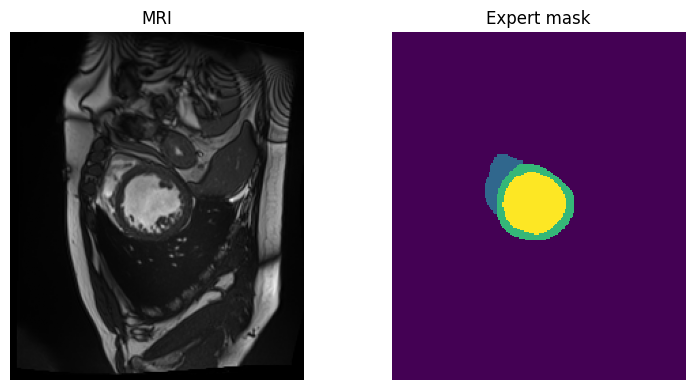

In [ ]:
import zipfile
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

patient_id = train_patients.iloc[0]['patient_id']
zip_path = data_path / f'{patient_id}.zip'

local_folder = Path('/content/acdc_preview') / patient_id
local_folder.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as archive:
    mask_names = sorted(
        name for name in archive.namelist()
        if name.endswith('_gt.nii.gz')
    )
    assert mask_names, "No expert mask found."

    mask_name = mask_names[0]
    image_name = mask_name.replace('_gt.nii.gz', '.nii.gz')

    # Extract only this image–mask pair into temporary Colab storage.
    for name in (image_name, mask_name):
        destination = local_folder / Path(name).name
        destination.write_bytes(archive.read(name))

image_file = nib.load(local_folder / Path(image_name).name)
mask_file = nib.load(local_folder / Path(mask_name).name)

image = image_file.get_fdata()
mask = mask_file.get_fdata()

assert image.shape == mask.shape, "Image and mask dimensions differ."
assert np.allclose(image_file.affine, mask_file.affine), "Spatial alignment differs."

print("Patient:", patient_id)
print("Image shape:", image.shape)
print("Voxel spacing:", image_file.header.get_zooms())
print("Mask labels:", np.unique(mask))

slice_index = image.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image[:, :, slice_index].T, cmap='gray', origin='lower')
axes[0].set_title('MRI')

axes[1].imshow(
    mask[:, :, slice_index].T,
    cmap='viridis', vmin=0, vmax=3,
    interpolation='nearest', origin='lower'
)
axes[1].set_title('Expert mask')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Pixel features for the classical models**

The classical models classify one pixel at a time, so each pixel needs a small set of numbers describing it. We use five: its intensity, the mean and standard deviation of its 5 × 5 neighbourhood, and its relative row and column position in the image.

In [ ]:
import numpy as np
from scipy.ndimage import uniform_filter

FEATURE_NAMES = [
    "intensity",
    "local_mean",
    "local_std",
    "row_position",
    "column_position"
]

def extract_pixel_features(image_slice):
    """Convert one preprocessed 2D MRI slice into pixel features."""
    img = np.asarray(image_slice, dtype=np.float32)

    if img.ndim != 2:
        raise ValueError("Expected one 2D MRI slice.")

    if not np.isfinite(img).all():
        raise ValueError("Image contains NaN or infinity.")

    local_mean = uniform_filter(img, size=5, mode="reflect")
    local_mean_squared = uniform_filter(
        img * img, size=5, mode="reflect"
    )

    local_std = np.sqrt(
        np.maximum(local_mean_squared - local_mean**2, 0)
    )

    height, width = img.shape

    rows = np.broadcast_to(
        np.linspace(0, 1, height, dtype=np.float32)[:, None],
        img.shape
    )
    columns = np.broadcast_to(
        np.linspace(0, 1, width, dtype=np.float32)[None, :],
        img.shape
    )

    features = np.stack(
        [img, local_mean, local_std, rows, columns],
        axis=-1
    )

    return features.reshape(-1, len(FEATURE_NAMES))

print("Feature extraction function ready.")
print("Features:", FEATURE_NAMES)

Feature extraction function ready.
Features: ['intensity', 'local_mean', 'local_std', 'row_position', 'column_position']


**Checking the features**

A quick check on one slice that we get one row of five features per pixel, in the same order as the pixels in the image.

In [ ]:
# Use the MRI volume already loaded by the preview cell.
k = image.shape[2] // 2
example_slice = image[:, :, k]

example_features = extract_pixel_features(example_slice)

expected_pixels = example_slice.size

assert example_features.shape == (expected_pixels, 5)
assert np.isfinite(example_features).all()

# Check that pixel order is preserved.
assert np.allclose(
    example_features[:, 0],
    example_slice.reshape(-1)
)

print("MRI slice shape:", example_slice.shape)
print("Feature table shape:", example_features.shape)
print("Each row = one pixel; each column = one feature.")

display(pd.DataFrame(
    example_features[:5],
    columns=FEATURE_NAMES
))

MRI slice shape: (216, 256)
Feature table shape: (55296, 5)
Each row = one pixel; each column = one feature.


,intensity,local_mean,local_std,row_position,column_position
0,0.0,0.0,0.0,0.0,0.000000
1,0.0,0.0,0.0,0.0,0.003922
2,0.0,0.0,0.0,0.0,0.007843
3,0.0,0.0,0.0,0.0,0.011765
4,0.0,0.0,0.0,0.0,0.015686


**Matching labels to features**

Each feature row gets the expert's label for that pixel. The table shows how few pixels in a slice actually belong to the heart.

In [ ]:
# Same slice index used for the MRI feature check.
example_mask = mask[:, :, k]

assert example_mask.shape == example_slice.shape
assert set(np.unique(example_mask)) <= {0, 1, 2, 3}

# Preserve the same pixel order as the feature table.
example_labels = example_mask.astype(np.int64).reshape(-1)

assert len(example_labels) == len(example_features)

label_names = {
    0: "Background",
    1: "Right ventricle",
    2: "Myocardium",
    3: "Left ventricle"
}

counts = np.bincount(example_labels, minlength=4)

display(pd.DataFrame({
    "Label": range(4),
    "Structure": [label_names[i] for i in range(4)],
    "Pixels in this slice": counts,
    "Percentage": (100 * counts / len(example_labels)).round(2)
}))

print("Features and expert labels are paired correctly by pixel order.")

,Label,Structure,Pixels in this slice,Percentage
0,0,Background,52274,94.53
1,1,Right ventricle,512,0.93
2,2,Myocardium,888,1.61
3,3,Left ventricle,1622,2.93


Features and expert labels are paired correctly by pixel order.


**Dice score**

Dice measures the overlap between the predicted region and the expert's region for each structure (2 × overlap divided by the two sizes added together). If a structure is missing from both masks, the score is left as NaN instead of being counted as perfect.

In [ ]:
import numpy as np

CLASS_NAMES = {
    1: 'Right ventricle',
    2: 'Myocardium',
    3: 'Left ventricle'
}

def dice_per_structure(true_mask, predicted_mask):
    true_mask = np.asarray(true_mask)
    predicted_mask = np.asarray(predicted_mask)

    if true_mask.shape != predicted_mask.shape:
        raise ValueError("The masks must have the same shape.")

    scores = {}

    for label, name in CLASS_NAMES.items():
        true_region = true_mask == label
        predicted_region = predicted_mask == label

        intersection = np.count_nonzero(true_region & predicted_region)
        total = true_region.sum() + predicted_region.sum()

        # If both masks lack this structure, leave its score undefined.
        scores[name] = (
            2.0 * intersection / total if total > 0 else np.nan
        )

    return scores

**Dice sanity check**

Comparing a mask with itself should give exactly 1.0. This only tests the function, not any model.

In [ ]:
print(dice_per_structure(mask, mask))

{'Right ventricle': np.float64(1.0), 'Myocardium': np.float64(1.0), 'Left ventricle': np.float64(1.0)}


## <span style="color:#247C87">5. Preprocessing</span>

The scans come in many sizes and pixel spacings, and their brightness varies a lot from one scanner to another. Every model in this notebook uses the same shared pipeline:

1. resample each slice to 1.5 mm pixels (linear interpolation for the image, nearest neighbour for the mask so labels stay whole numbers),
2. centre-crop or pad to 288 × 288 pixels, keeping the number of slices,
3. normalize each volume using the mean and standard deviation of its nonzero pixels.

Section 5.1 shows the checks that led to these settings, 5.2 runs the final pipeline on all 200 volumes, and 5.3 keeps the other options we tried along the way.

### 5.1 Checks that shaped the settings

**Trying the steps on one scan**

A first look at normalization, resampling to 1.5 mm and padding on one volume, before choosing a common image size for everyone.

Original shape: (216, 256, 10)
After preprocessing: (288, 288, 10)
Mask labels: [0 1 2 3]
Slices preserved: True


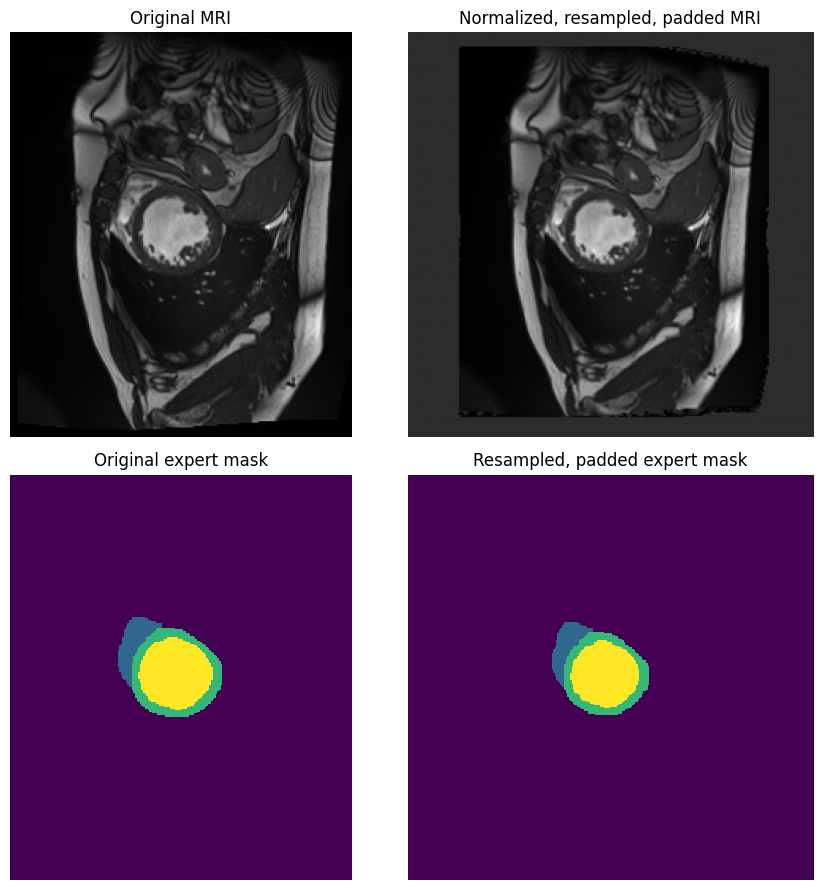

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# Uses image, mask, and image_file from your MRI preview cell.
TARGET_SPACING = 1.5  # Trial in-plane spacing, in millimetres

# 1. Normalize using the MRI intensities, without using the expert mask.
image_normalized = image.astype(np.float32).copy()
nonzero = image_normalized != 0

if not nonzero.any():
    raise ValueError("The MRI contains only zeros.")

mean = image_normalized[nonzero].mean()
std = image_normalized[nonzero].std()

image_normalized[nonzero] = (
    image_normalized[nonzero] - mean
) / max(float(std), 1e-8)

# 2. Standardize physical spacing within each slice.
# Keep the number of slices unchanged.
sx, sy = image_file.header.get_zooms()[:2]
scale = (float(sx) / TARGET_SPACING,
         float(sy) / TARGET_SPACING,
         1.0)

image_resampled = zoom(
    image_normalized, scale, order=1, prefilter=False
)

# Nearest-neighbor interpolation preserves discrete mask labels.
mask_resampled = zoom(
    mask, scale, order=0, prefilter=False
).astype(np.uint8)

# 3. Pad to a square for this preview; do not crop any anatomy.
# A shared input size for ALL patients will be chosen afterward.
height, width, _ = image_resampled.shape
side = int(np.ceil(max(256, height, width) / 32) * 32)

def padding_for(length):
    difference = side - length
    return (difference // 2, difference - difference // 2)

padding = (
    padding_for(height),
    padding_for(width),
    (0, 0)
)

image_preprocessed = np.pad(
    image_resampled, padding, mode="constant", constant_values=0
)
mask_preprocessed = np.pad(
    mask_resampled, padding, mode="constant", constant_values=0
)

assert image_preprocessed.shape == mask_preprocessed.shape
assert set(np.unique(mask_preprocessed)) <= {0, 1, 2, 3}
assert np.isfinite(image_preprocessed).all()

print("Original shape:", image.shape)
print("After preprocessing:", image_preprocessed.shape)
print("Mask labels:", np.unique(mask_preprocessed))
print("Slices preserved:", image.shape[2] == image_preprocessed.shape[2])

# 4. Compare the same middle slice before and after.
k = image.shape[2] // 2
fig, axes = plt.subplots(2, 2, figsize=(9, 9))

axes[0, 0].imshow(image[:, :, k].T, cmap="gray", origin="lower")
axes[0, 0].set_title("Original MRI")

axes[0, 1].imshow(
    image_preprocessed[:, :, k].T, cmap="gray", origin="lower"
)
axes[0, 1].set_title("Normalized, resampled, padded MRI")

axes[1, 0].imshow(
    mask[:, :, k].T, vmin=0, vmax=3,
    interpolation="nearest", origin="lower"
)
axes[1, 0].set_title("Original expert mask")

axes[1, 1].imshow(
    mask_preprocessed[:, :, k].T, vmin=0, vmax=3,
    interpolation="nearest", origin="lower"
)
axes[1, 1].set_title("Resampled, padded expert mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Scans with very different spacing**

The same steps on three training scans with very different pixel spacing (0.70, 1.56 and 1.92 mm). After resampling, the heart should look the same size in millimetres, and the structure areas should barely change.

split
train         80
validation    20
Examples (ED phase): ['patient057', 'patient001', 'patient043']


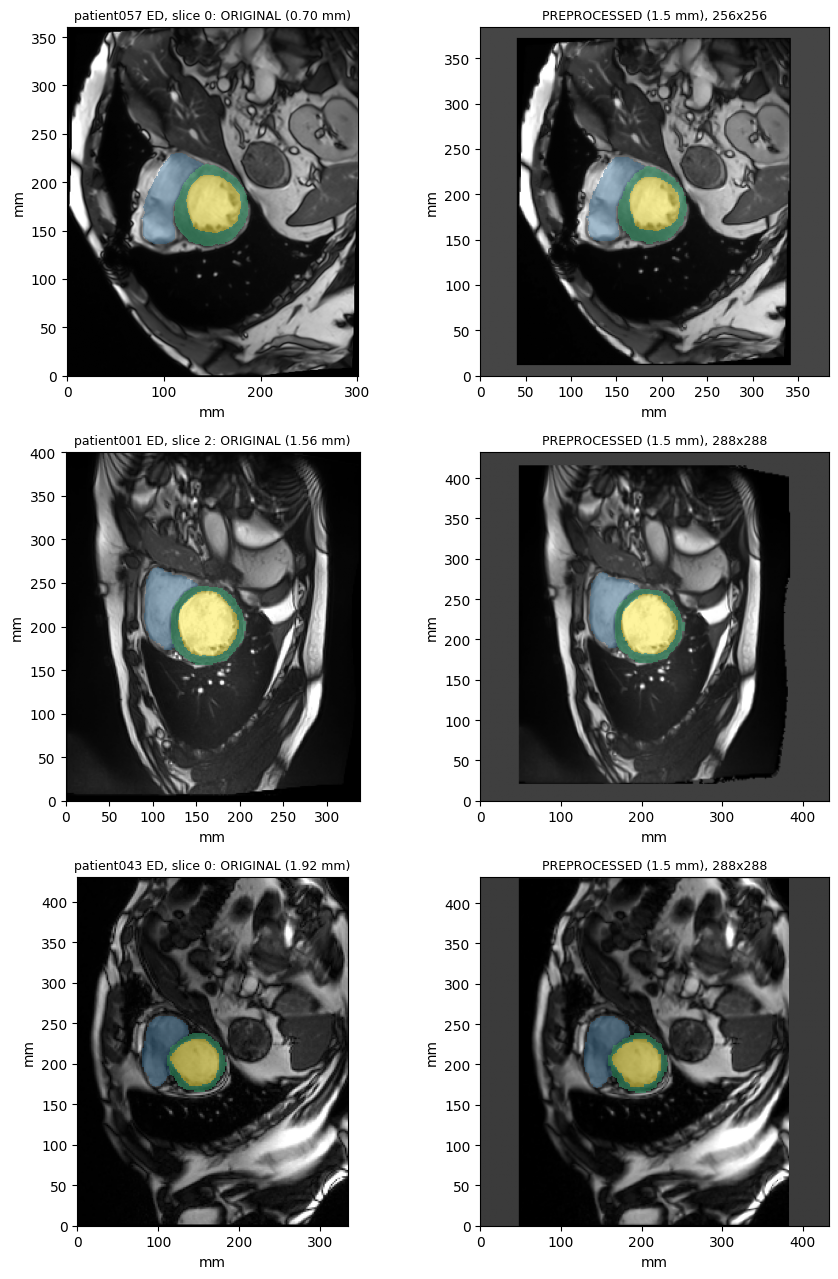

patient                             patient057                  patient001                                patient043
frame                                        1                           1                                         1
orig_shape                       (428, 512, 8)              (216, 256, 10)                            (174, 224, 12)
spacing_xy                (0.703125, 0.703125)            (1.5625, 1.5625)  (1.9196399450302124, 1.9196399450302124)
resampled                        (201, 240, 8)              (225, 267, 10)                            (223, 287, 12)
padded                           (256, 256, 8)              (288, 288, 10)                            (288, 288, 12)
FOV_mm_before                       (301, 360)                  (338, 400)                                (334, 430)
FOV_mm_resampled                    (302, 360)                  (338, 400)                                (334, 430)
zero_voxels_%                              0.0                  

In [ ]:
import zipfile, gzip
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# ---------- PROPOSED preview settings (not final) ----------
TARGET_SPACING = 1.5      # mm, trial in-plane spacing
PAD_MULTIPLE = 32         # preview pads each volume to a multiple of 32 (per-volume, not yet shared)

# ---------- 1. Load the shared split (do not create a new one) ----------
split = pd.read_csv(data_path / 'patient_split_seed42.csv')
counts = split['split'].value_counts().to_dict()
assert counts == {'train': 80, 'validation': 20}, f"Unexpected split sizes: {counts}"
print(split['split'].value_counts().to_string())
train_ids = split.loc[split['split'] == 'train', 'patient_id'].tolist()

# ---------- 2. Helpers ----------
def load_nifti(archive, name):
    return nib.Nifti1Image.from_bytes(gzip.decompress(archive.read(name)))

def load_pair(pid, phase):
    """Read one image-mask pair straight from the patient's ZIP (nothing is extracted or changed)."""
    with zipfile.ZipFile(data_path / f'{pid}.zip') as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        info = {}
        for line in z.read(names['Info.cfg']).decode('utf-8-sig').splitlines():
            if ':' in line:
                k, v = line.split(':', 1)
                info[k.strip()] = v.strip()
        frame = int(info[phase])
        img_f = load_nifti(z, names[f'{pid}_frame{frame:02d}.nii.gz'])
        msk_f = load_nifti(z, names[f'{pid}_frame{frame:02d}_gt.nii.gz'])
        img = img_f.get_fdata().astype(np.float32)
        msk_raw = msk_f.get_fdata()
    assert img.shape == msk_raw.shape, "image/mask shape differs"
    assert np.allclose(img_f.affine, msk_f.affine), "image/mask affine differs"
    assert np.allclose(msk_raw, np.rint(msk_raw)), "mask is not whole numbers"
    msk = np.rint(msk_raw).astype(np.uint8)        # labels as small integers BEFORE any resampling
    return img, msk, tuple(float(s) for s in img_f.header.get_zooms()[:3]), frame

def preview_preprocess(img, msk, spacing):
    """The preview's three steps, unchanged in substance: normalize, resample in-plane, pad."""
    out = img.copy()
    nz = out != 0
    mean, std = out[nz].mean(), out[nz].std()
    out[nz] = (out[nz] - mean) / max(float(std), 1e-8)

    scale = (spacing[0] / TARGET_SPACING, spacing[1] / TARGET_SPACING, 1.0)
    img_r = zoom(out, scale, order=1, prefilter=False)     # linear for the image
    msk_r = zoom(msk, scale, order=0, prefilter=False)     # nearest-neighbour for labels

    h, w, _ = img_r.shape
    side = int(np.ceil(max(256, h, w) / PAD_MULTIPLE) * PAD_MULTIPLE)
    pad = lambda n: ((side - n) // 2, side - n - (side - n) // 2)
    pads = (pad(h), pad(w), (0, 0))
    img_p = np.pad(img_r, pads, mode='constant', constant_values=0)
    msk_p = np.pad(msk_r, pads, mode='constant', constant_values=0)

    assert img_p.shape == msk_p.shape and np.isfinite(img_p).all()
    assert set(np.unique(msk_p).tolist()) <= {0, 1, 2, 3}
    return dict(img_norm=out, img=img_p, msk=msk_p, resampled_shape=img_r.shape,
                padded_shape=img_p.shape, scale=scale, pads=pads, nz=nz)

def area_mm2(msk, sx, sy):
    return {l: int((msk == l).sum()) * sx * sy for l in (1, 2, 3)}

# ---------- 3. Pick examples: first training patient (+ extreme spacings if `meta` exists) ----------
example_ids = [train_ids[0]]
if 'meta' in globals():
    m = meta[meta['patient_id'].isin(train_ids) & (meta['phase'] == 'ED')].sort_values('spacing_x')
    example_ids = [m.iloc[0]['patient_id'], train_ids[0], m.iloc[-1]['patient_id']]
example_ids = list(dict.fromkeys(example_ids))             # remove duplicates, keep order
print("Examples (ED phase):", example_ids)

# ---------- 4. Run the preview, print diagnostics, draw before/after ----------
fig, axes = plt.subplots(len(example_ids), 2, figsize=(9, 4.3 * len(example_ids)), squeeze=False)
summary = []
for row, pid in enumerate(example_ids):
    img, msk, sp, frame = load_pair(pid, 'ED')
    res = preview_preprocess(img, msk, sp)
    nz = res['nz']
    normed = res['img_norm'][nz]
    a0, a1 = area_mm2(msk, sp[0], sp[1]), area_mm2(res['msk'], TARGET_SPACING, TARGET_SPACING)

    summary.append({
        'patient': pid, 'frame': frame, 'orig_shape': img.shape, 'spacing_xy': sp[:2],
        'resampled': res['resampled_shape'], 'padded': res['padded_shape'],
        'FOV_mm_before': (round(img.shape[0] * sp[0]), round(img.shape[1] * sp[1])),
        'FOV_mm_resampled': (round(res['resampled_shape'][0] * TARGET_SPACING),
                             round(res['resampled_shape'][1] * TARGET_SPACING)),
        'zero_voxels_%': round(100 * float((img == 0).mean()), 1),
        'norm_p1/p50/p99/max': tuple(round(float(v), 2) for v in
                                     (*np.percentile(normed, [1, 50, 99]), normed.max())),
        'RV_area_change_%': round(100 * (a1[1] - a0[1]) / a0[1], 1),
        'Myo_area_change_%': round(100 * (a1[2] - a0[2]) / a0[2], 1),
        'LV_area_change_%': round(100 * (a1[3] - a0[3]) / a0[3], 1),
        'labels_after': np.unique(res['msk']).tolist(),
    })

    k = int(np.argmax((msk > 0).sum(axis=(0, 1))))          # slice with most annotation (display only)
    for col, (im, mk, sx, sy, title) in enumerate([
            (img, msk, sp[0], sp[1], f'{pid} ED, slice {k}: ORIGINAL ({sp[0]:.2f} mm)'),
            (res['img'], res['msk'], TARGET_SPACING, TARGET_SPACING,
             f"PREPROCESSED ({TARGET_SPACING} mm), {res['padded_shape'][0]}x{res['padded_shape'][1]}")]):
        ax = axes[row, col]
        extent = (0, im.shape[0] * sx, 0, im.shape[1] * sy)  # axes in millimetres
        lo, hi = np.percentile(im[:, :, k], [1, 99])         # contrast stretch: display only
        ax.imshow(im[:, :, k].T, cmap='gray', origin='lower', extent=extent, vmin=lo, vmax=hi)
        ax.imshow(np.ma.masked_equal(mk[:, :, k], 0).T, cmap='viridis', vmin=0, vmax=3, alpha=0.45,
                  interpolation='nearest', origin='lower', extent=extent)
        ax.set_title(title, fontsize=9); ax.set_xlabel('mm'); ax.set_ylabel('mm')
plt.tight_layout()
plt.show()

print(pd.DataFrame(summary).set_index('patient').T.to_string())

**Choosing the image size**

We test several square sizes and measure, using the training masks, whether a fixed centre crop would ever cut into the heart. The masks are only used to measure; the crop position never depends on them, because at test time there is no mask.

In [ ]:
# Uses from Step 1.1: data_path, train_ids, load_nifti, TARGET_SPACING
import zipfile
import numpy as np
import pandas as pd
from scipy.ndimage import zoom

def read_info(z, names):
    info = {}
    for line in z.read(names['Info.cfg']).decode('utf-8-sig').splitlines():
        if ':' in line:
            k, v = line.split(':', 1)
            info[k.strip()] = v.strip()
    return info

rows = []
for pid in train_ids:                                   # TRAINING patients only
    with zipfile.ZipFile(data_path / f'{pid}.zip') as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        info = read_info(z, names)
        for phase in ('ED', 'ES'):
            frame = int(info[phase])
            m_f = load_nifti(z, names[f'{pid}_frame{frame:02d}_gt.nii.gz'])   # mask only: the audit already showed
            msk = np.rint(m_f.get_fdata()).astype(np.uint8)                  # image/mask shape+affine always match
            sx, sy = (float(s) for s in m_f.header.get_zooms()[:2])
            msk_r = zoom(msk, (sx / TARGET_SPACING, sy / TARGET_SPACING, 1.0), order=0, prefilter=False)
            fg = msk_r > 0
            xs = np.where(fg.any(axis=(1, 2)))[0]
            ys = np.where(fg.any(axis=(0, 2)))[0]
            rows.append(dict(patient_id=pid, phase=phase, orig_h=msk.shape[0], orig_w=msk.shape[1], spacing=sx,
                             rh=msk_r.shape[0], rw=msk_r.shape[1],
                             hx0=xs.min(), hx1=xs.max(), hy0=ys.min(), hy1=ys.max()))
geo = pd.DataFrame(rows)
print("Volumes (training patients x 2 phases):", len(geo))

print("\nORIGINAL in-plane matrix: distinct sizes", geo[['orig_h', 'orig_w']].drop_duplicates().shape[0],
      "| height", geo['orig_h'].min(), "-", geo['orig_h'].max(), "| width", geo['orig_w'].min(), "-", geo['orig_w'].max())
print("Spacing (mm):", round(geo['spacing'].min(), 3), "-", round(geo['spacing'].max(), 3))
print("\nAfter resampling to", TARGET_SPACING, "mm (pixels):")
print(geo[['rh', 'rw']].describe().round(0).to_string())
print("Largest resampled side:", int(max(geo['rh'].max(), geo['rw'].max())),
      "->", geo.loc[geo[['rh', 'rw']].max(axis=1).idxmax(), 'patient_id'])

# Heart size and position in mm (training masks used to MEASURE only, not to place any crop)
geo['heart_h_mm'] = (geo['hx1'] - geo['hx0'] + 1) * TARGET_SPACING
geo['heart_w_mm'] = (geo['hy1'] - geo['hy0'] + 1) * TARGET_SPACING
geo['off_h_mm'] = ((geo['hx0'] + geo['hx1']) / 2 - (geo['rh'] - 1) / 2) * TARGET_SPACING
geo['off_w_mm'] = ((geo['hy0'] + geo['hy1']) / 2 - (geo['rw'] - 1) / 2) * TARGET_SPACING
print("\nHeart extent (mm):\n", geo[['heart_h_mm', 'heart_w_mm']].describe().round(0).to_string())
print("\nHeart centre minus image centre (mm):\n", geo[['off_h_mm', 'off_w_mm']].describe().round(0).to_string())

# Candidate fixed square sizes with a FIXED CENTRED placement: pad if smaller, crop if larger
def place(n, a, b, S):
    """Where does heart span [a,b] fall inside a canvas of size S after centred pad/crop?"""
    if n <= S:
        off = (S - n) // 2
        return a + off, b + off
    start = (n - S) // 2
    return a - start, b - start

print("\nCANDIDATE FIXED SIZES (centred pad/crop, 1.5 mm pixels)")
out = []
for S in (192, 224, 256, 288, 320):
    cut = cropped = 0
    margins, pad_frac = [], []
    for r in geo.itertuples():
        px0, px1 = place(r.rh, r.hx0, r.hx1, S)
        py0, py1 = place(r.rw, r.hy0, r.hy1, S)
        margin = min(px0, S - 1 - px1, py0, S - 1 - py1)         # pixels between heart and canvas edge
        margins.append(margin * TARGET_SPACING)
        cut += margin < 0
        cropped += (r.rh > S) or (r.rw > S)
        pad_frac.append(1 - min(r.rh, S) * min(r.rw, S) / S ** 2)
    out.append(dict(size=S, volumes_cropped=cropped, heart_cut=int(cut),
                    min_heart_margin_mm=round(min(margins), 1), mean_padding_share=round(float(np.mean(pad_frac)), 2)))
print(pd.DataFrame(out).to_string(index=False))

Volumes (training patients x 2 phases): 160

ORIGINAL in-plane matrix: distinct sizes 22 | height 154 - 428 | width 154 - 512
Spacing (mm): 0.703 - 1.92

After resampling to 1.5 mm (pixels):
          rh     rw
count  160.0  160.0
mean   219.0  249.0
std     27.0   29.0
min    149.0  170.0
25%    197.0  233.0
50%    217.0  250.0
75%    233.0  267.0
max    272.0  320.0
Largest resampled side: 320 -> patient037

Heart extent (mm):
        heart_h_mm  heart_w_mm
count       160.0       160.0
mean        106.0        99.0
std          14.0        13.0
min          69.0        63.0
25%          96.0        90.0
50%         106.0        98.0
75%         114.0       106.0
max         152.0       136.0

Heart centre minus image centre (mm):
        off_h_mm  off_w_mm
count     160.0     160.0
mean      -23.0       0.0
std        14.0      21.0
min       -63.0     -80.0
25%       -32.0     -10.0
50%       -21.0       1.0
75%       -15.0      13.0
max        10.0      55.0

CANDIDATE FIXED SIZES

**Scans larger than 288 × 288**

With 288 × 288, only 10 training volumes need cropping, and only along one side. This lists them.

In [ ]:

# Identify volumes that exceed 288 x 288 after 1.5 mm resampling

TARGET_SIZE = 288

oversized = geo[
    (geo["rh"] > TARGET_SIZE) |
    (geo["rw"] > TARGET_SIZE)
].copy()

oversized["crop_h"] = (oversized["rh"] - TARGET_SIZE).clip(lower=0)
oversized["crop_w"] = (oversized["rw"] - TARGET_SIZE).clip(lower=0)

print("Number of oversized volumes:", len(oversized))
print("\nAffected patient/phase combinations:")

print(
    oversized[
        ["patient_id", "phase", "rh", "rw", "crop_h", "crop_w"]
    ].sort_values(["patient_id", "phase"]).to_string(index=False)
)

print("\nLargest dimensions:")
print("Height:", oversized["rh"].max())
print("Width:", oversized["rw"].max())


Number of oversized volumes: 10

Affected patient/phase combinations:
patient_id phase  rh  rw  crop_h  crop_w
patient006    ED 272 300       0      12
patient006    ES 272 300       0      12
patient020    ED 244 300       0      12
patient020    ES 244 300       0      12
patient037    ED 270 320       0      32
patient037    ES 270 320       0      32
patient042    ED 272 300       0      12
patient042    ES 272 300       0      12
patient080    ED 253 300       0      12
patient080    ES 253 300       0      12

Largest dimensions:
Height: 272
Width: 320


**Looking at those crops**

The yellow box shows the 288 × 288 centre crop on each of these scans. In every case the heart stays well inside.

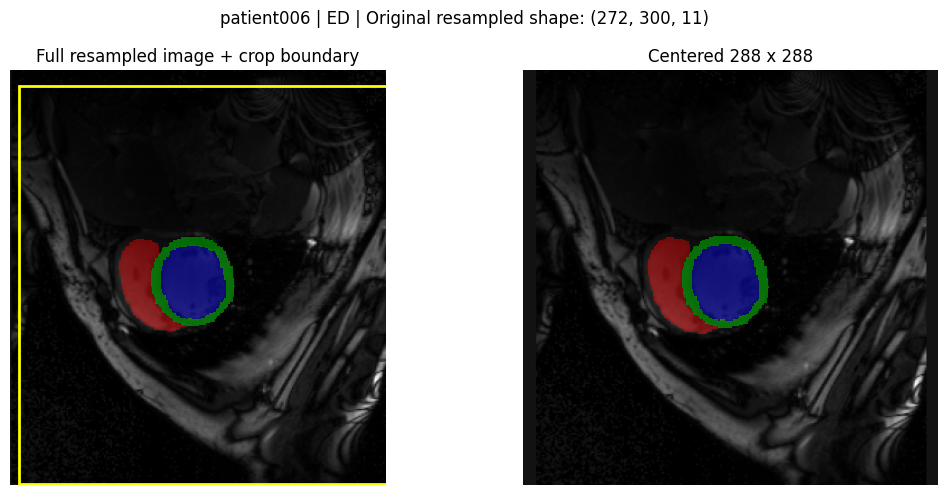

patient006 ED | Crop offsets: (0, 6) | Padding: ((8, 8), (0, 0), (0, 0)) | Labels: [0 1 2 3]


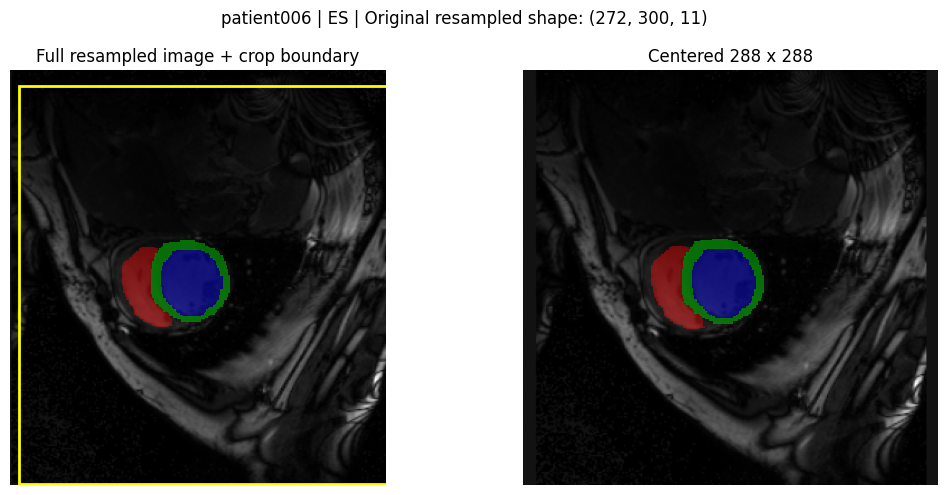

patient006 ES | Crop offsets: (0, 6) | Padding: ((8, 8), (0, 0), (0, 0)) | Labels: [0 1 2 3]


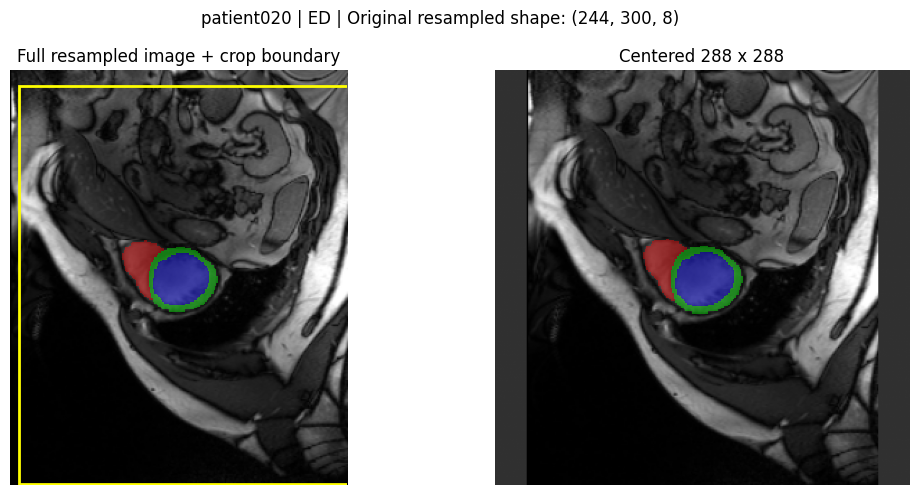

patient020 ED | Crop offsets: (0, 6) | Padding: ((22, 22), (0, 0), (0, 0)) | Labels: [0 1 2 3]


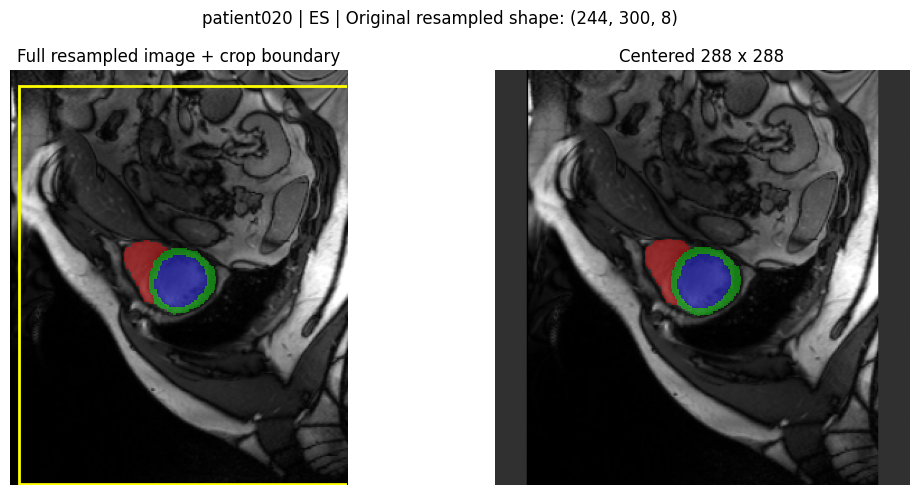

patient020 ES | Crop offsets: (0, 6) | Padding: ((22, 22), (0, 0), (0, 0)) | Labels: [0 1 2 3]


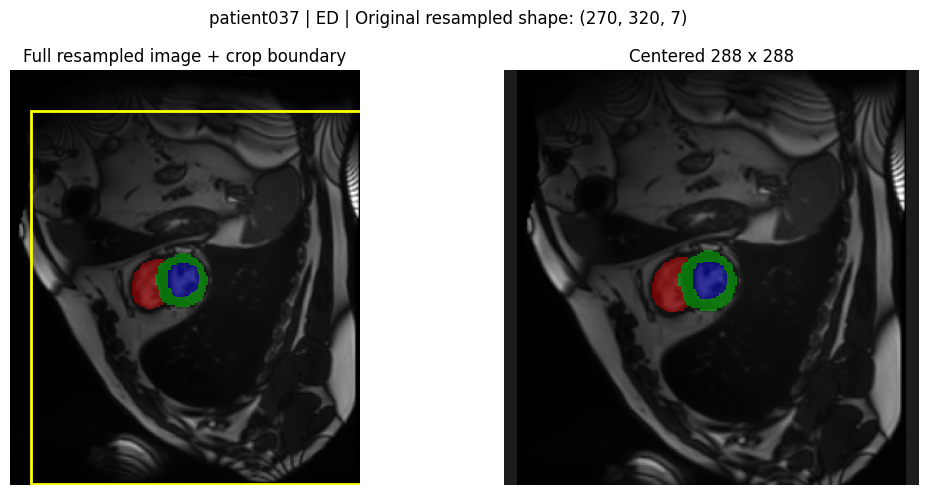

patient037 ED | Crop offsets: (0, 16) | Padding: ((9, 9), (0, 0), (0, 0)) | Labels: [0 1 2 3]


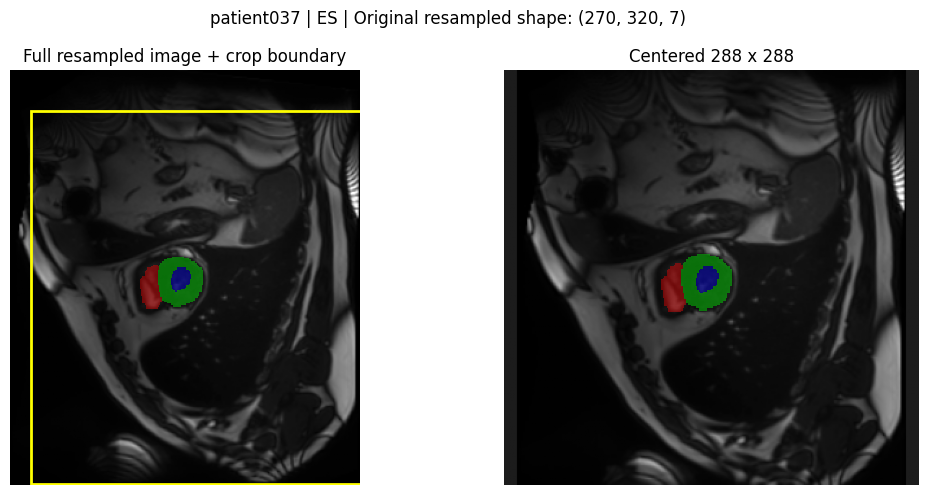

patient037 ES | Crop offsets: (0, 16) | Padding: ((9, 9), (0, 0), (0, 0)) | Labels: [0 1 2 3]


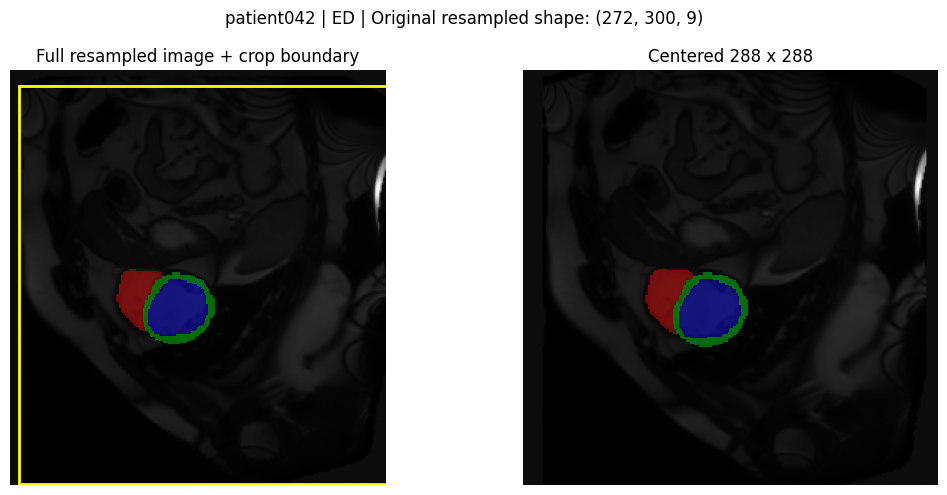

patient042 ED | Crop offsets: (0, 6) | Padding: ((8, 8), (0, 0), (0, 0)) | Labels: [0 1 2 3]


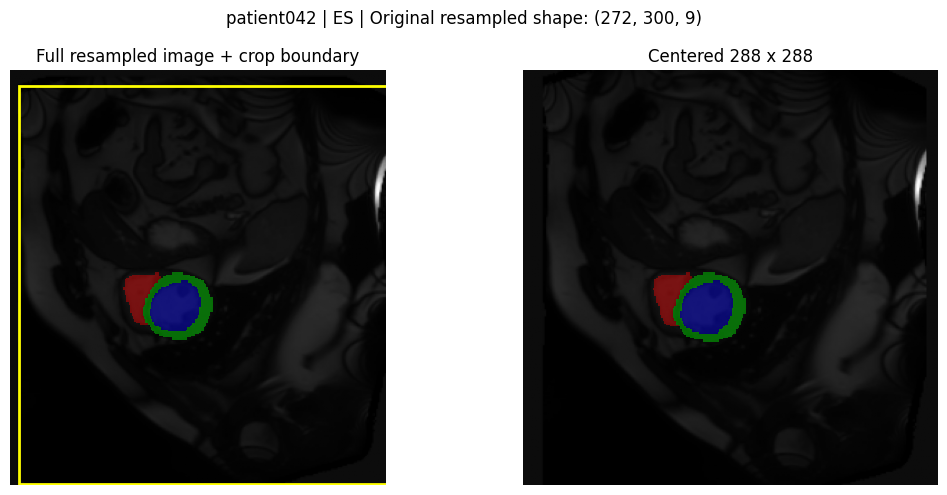

patient042 ES | Crop offsets: (0, 6) | Padding: ((8, 8), (0, 0), (0, 0)) | Labels: [0 1 2 3]


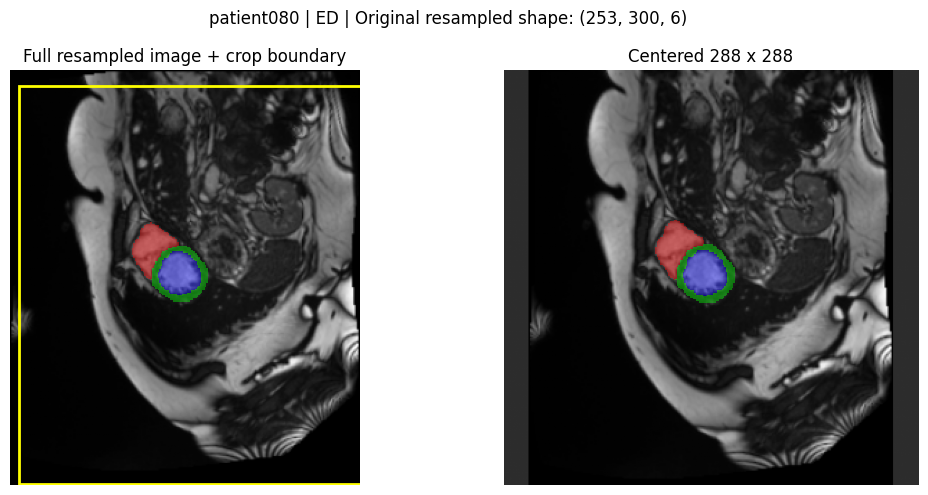

patient080 ED | Crop offsets: (0, 6) | Padding: ((17, 18), (0, 0), (0, 0)) | Labels: [0 1 2 3]


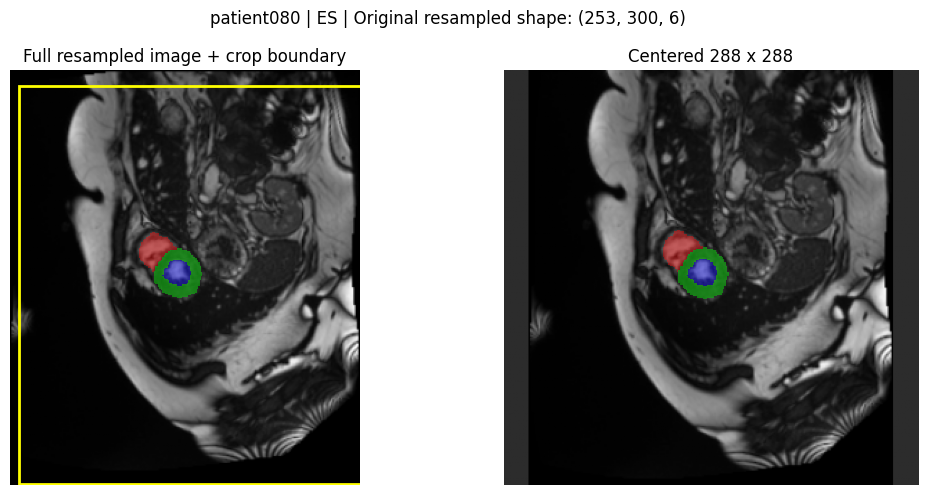

patient080 ES | Crop offsets: (0, 6) | Padding: ((17, 18), (0, 0), (0, 0)) | Labels: [0 1 2 3]


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import zoom
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

def center_pad_crop(array, target=288):
    """Center crop or pad the first two dimensions."""
    h, w, slices = array.shape

    # Calculate the crop using image dimensions only
    h_start = max(0, (h - target) // 2)
    w_start = max(0, (w - target) // 2)

    cropped = array[
        h_start:min(h, h_start + target),
        w_start:min(w, w_start + target),
        :
    ]

    # Pad if dimensions are smaller than target
    pad_h = target - cropped.shape[0]
    pad_w = target - cropped.shape[1]

    pads = (
        (pad_h // 2, pad_h - pad_h // 2),
        (pad_w // 2, pad_w - pad_w // 2),
        (0, 0)
    )

    result = np.pad(cropped, pads, mode="constant")

    return result, (h_start, w_start), pads


mask_cmap = ListedColormap([
    "black", "red", "lime", "blue"
])

for row in oversized.itertuples():

    pid = row.patient_id
    phase = row.phase

    # Load the original image and mask
    img, msk, spacing, frame = load_pair(pid, phase)

    # Normalize using nonzero MRI intensities
    img = img.copy()
    nz = img != 0

    mean = img[nz].mean()
    std = img[nz].std()

    img[nz] = (img[nz] - mean) / max(float(std), 1e-8)

    # Resample image and mask together
    scale = (
        spacing[0] / TARGET_SPACING,
        spacing[1] / TARGET_SPACING,
        1.0
    )

    img_r = zoom(img, scale, order=1, prefilter=False)
    msk_r = zoom(msk, scale, order=0, prefilter=False)

    # Apply identical centered geometry
    img_288, offsets, pads = center_pad_crop(img_r, TARGET_SIZE)
    msk_288, _, _ = center_pad_crop(msk_r, TARGET_SIZE)

    # Select middle slice for consistent visual comparison
    k = img_r.shape[2] // 2

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    # Full resampled MRI and mask
    axes[0].imshow(img_r[:, :, k].T, cmap="gray", origin="lower")
    axes[0].imshow(
        np.ma.masked_where(msk_r[:, :, k].T == 0,
                           msk_r[:, :, k].T),
        cmap=mask_cmap, vmin=0, vmax=3,
        alpha=0.4, interpolation="nearest", origin="lower"
    )

    # Rectangle shows the exact centered 288 crop
    h_start, w_start = offsets
    axes[0].add_patch(
        Rectangle(
            (w_start, h_start),
            TARGET_SIZE, TARGET_SIZE,
            fill=False, edgecolor="yellow", linewidth=2
        )
    )

    axes[0].set_title("Full resampled image + crop boundary")

    # Centered 288 x 288 result
    axes[1].imshow(
        img_288[:, :, k].T, cmap="gray", origin="lower"
    )
    axes[1].imshow(
        np.ma.masked_where(msk_288[:, :, k].T == 0,
                           msk_288[:, :, k].T),
        cmap=mask_cmap, vmin=0, vmax=3,
        alpha=0.4, interpolation="nearest", origin="lower"
    )

    axes[1].set_title("Centered 288 x 288")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{pid} | {phase} | Original resampled shape: {img_r.shape}"
    )
    plt.tight_layout()
    plt.show()

    print(
        pid, phase,
        "| Crop offsets:", offsets,
        "| Padding:", pads,
        "| Labels:", np.unique(msk_288)
    )


**Brightness across scans**

Compare the intensity range of each training volume, before and after normalizing with its own nonzero pixels.

In [ ]:
# Uses from Step 1.1/1.2: data_path, train_ids, load_nifti, read_info
import zipfile
import numpy as np
import pandas as pd

rows = []
for pid in train_ids:                                   # TRAINING patients only
    with zipfile.ZipFile(data_path / f'{pid}.zip') as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        info = read_info(z, names)
        for phase in ('ED', 'ES'):
            frame = int(info[phase])
            img = load_nifti(z, names[f'{pid}_frame{frame:02d}.nii.gz']).get_fdata().astype(np.float32)
            nz = img != 0
            vals = img[nz]
            z_ = (vals - vals.mean()) / max(float(vals.std()), 1e-8)        # the preview's rule
            rows.append(dict(patient_id=pid, phase=phase,
                             zero_pct=100 * float(1 - nz.mean()),
                             raw_max=float(img.max()), raw_p99=float(np.percentile(vals, 99)),
                             z_p1=float(np.percentile(z_, 1)), z_p50=float(np.percentile(z_, 50)),
                             z_p99=float(np.percentile(z_, 99)), z_max=float(z_.max())))
nstats = pd.DataFrame(rows)
nstats['tail_ratio'] = nstats['raw_max'] / nstats['raw_p99']        # how far the brightest voxel is above the 99th percentile
print("Volumes:", len(nstats))
print(nstats.drop(columns=['patient_id', 'phase']).describe().round(2).to_string())
print("\nVolumes with any exactly-zero voxels:", int((nstats['zero_pct'] > 0).sum()))
print("\nFive volumes with the heaviest bright tail:")
print(nstats.sort_values('tail_ratio', ascending=False).head(5)[['patient_id', 'phase', 'raw_max', 'raw_p99', 'z_max', 'tail_ratio']].round(2).to_string(index=False))

Volumes: 160
       zero_pct  raw_max  raw_p99    z_p1   z_p50   z_p99   z_max  tail_ratio
count    160.00   160.00   160.00  160.00  160.00  160.00  160.00      160.00
mean       2.15   502.96   253.67   -0.99   -0.32    3.20    6.52        1.78
std        3.07   583.52   168.20    0.12    0.06    0.46    3.38        0.90
min        0.00   207.00   137.00   -1.32   -0.54    2.24    3.70        1.00
25%        0.00   255.00   163.00   -1.07   -0.36    2.92    4.44        1.26
50%        0.00   255.00   211.00   -0.99   -0.33    3.11    5.58        1.61
75%        4.61   545.75   287.50   -0.92   -0.28    3.46    6.92        1.83
max       10.58  3316.00  1120.00   -0.68   -0.18    4.39   25.72        8.16

Volumes with any exactly-zero voxels: 60

Five volumes with the heaviest bright tail:
patient_id phase  raw_max  raw_p99  z_max  tail_ratio
patient042    ES   3158.0    387.0  25.72        8.16
patient042    ED   3183.0    392.0  25.54        8.12
patient071    ES   1406.0    297.0  

**Very bright pixels**

A few scans have a small number of extremely bright pixels. Here we look at where they are and how far they stretch the normalized values, to judge whether they would cause problems.

patient042 ES: brightest voxel at (228, 180, 6) in shape (232, 256, 9), z=25.7; voxels with z>8: 910 (0.1702% of all voxels)
patient042 ED: brightest voxel at (228, 180, 6) in shape (232, 256, 9), z=25.5; voxels with z>8: 883 (0.1652% of all voxels)
patient071 ES: brightest voxel at (83, 158, 1) in shape (192, 256, 10), z=22.3; voxels with z>8: 278 (0.0566% of all voxels)
patient067 ES: brightest voxel at (74, 163, 3) in shape (256, 216, 10), z=16.8; voxels with z>8: 754 (0.1364% of all voxels)


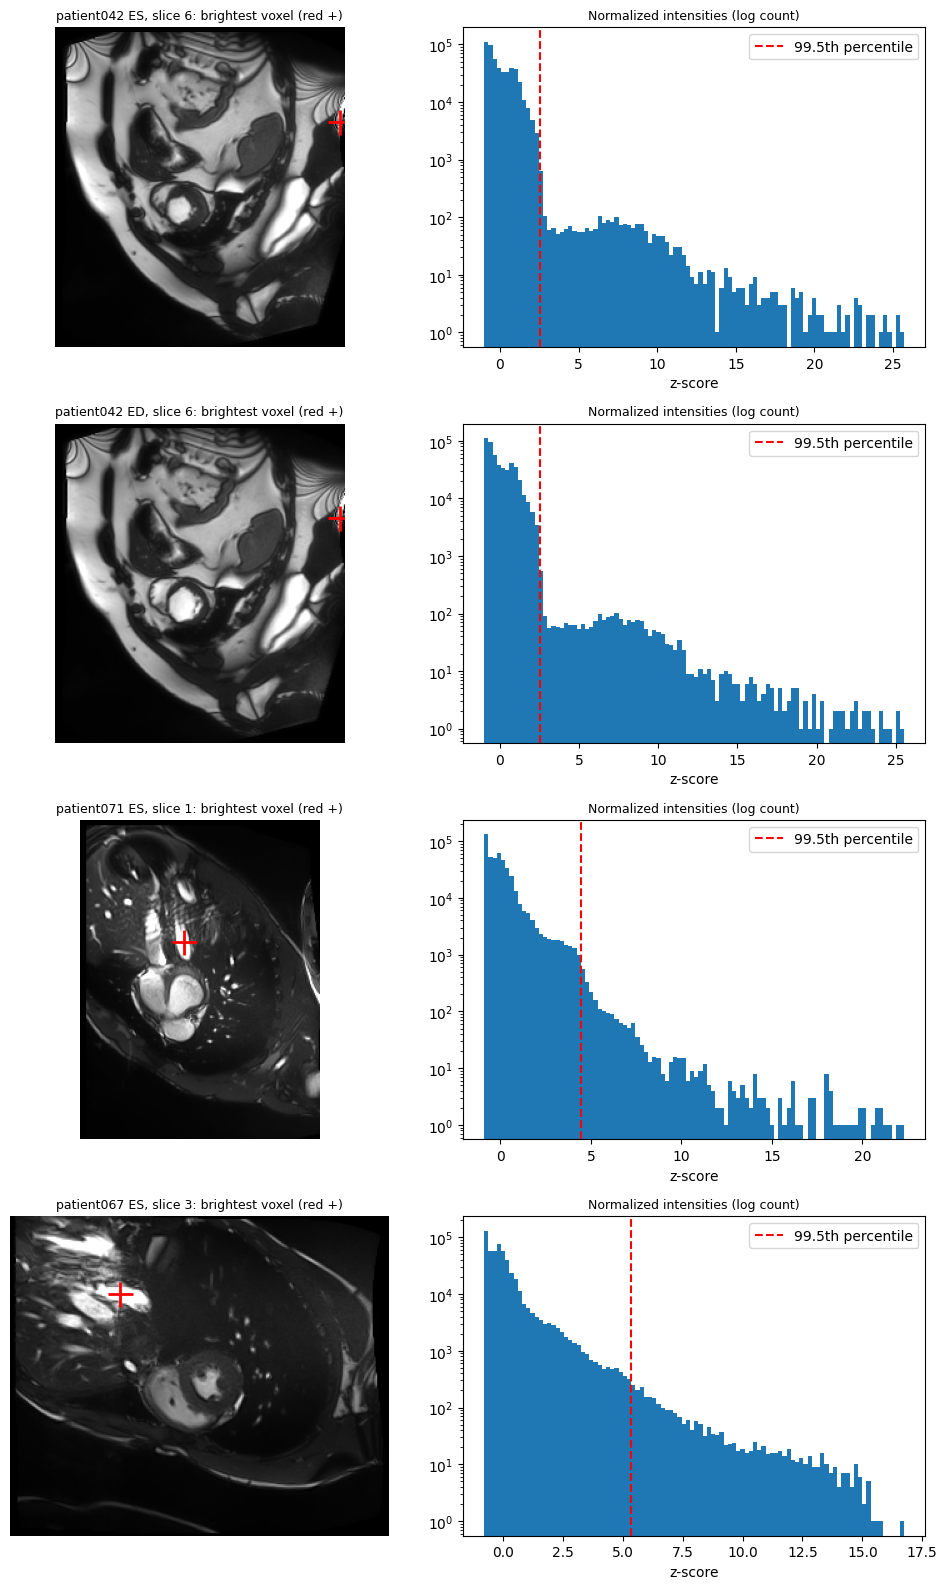

In [ ]:
# Uses from Steps 1.2/1.3: data_path, nstats, load_nifti, read_info
import zipfile
import numpy as np
import matplotlib.pyplot as plt

worst = nstats.sort_values('tail_ratio', ascending=False).head(4)[['patient_id', 'phase']].values.tolist()

fig, axes = plt.subplots(len(worst), 2, figsize=(10, 4 * len(worst)), squeeze=False)
for row, (pid, phase) in enumerate(worst):
    with zipfile.ZipFile(data_path / f'{pid}.zip') as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        frame = int(read_info(z, names)[phase])
        img = load_nifti(z, names[f'{pid}_frame{frame:02d}.nii.gz']).get_fdata().astype(np.float32)
    nz = img != 0
    mean, std = img[nz].mean(), img[nz].std()      # statistics from nonzero voxels (as in the preview)
    zimg = (img - mean) / max(float(std), 1e-8)    # the same linear map applied to EVERY voxel
    ix = np.unravel_index(np.argmax(img), img.shape)
    k = int(ix[2])
    n_hi = int((zimg > 8).sum())
    print(f"{pid} {phase}: brightest voxel at {tuple(int(i) for i in ix)} in shape {img.shape}, "
          f"z={zimg.max():.1f}; voxels with z>8: {n_hi} ({100 * n_hi / img.size:.4f}% of all voxels)")

    lo, hi = np.percentile(zimg[:, :, k], [1, 99])  # display window only
    ax = axes[row, 0]
    ax.imshow(zimg[:, :, k].T, cmap='gray', origin='lower', vmin=lo, vmax=hi)
    ax.plot(ix[0], ix[1], 'r+', markersize=18, markeredgewidth=2)
    ax.set_title(f'{pid} {phase}, slice {k}: brightest voxel (red +)', fontsize=9)
    ax.axis('off')

    ax = axes[row, 1]
    ax.hist(zimg[nz].ravel(), bins=100, log=True)
    ax.axvline(np.percentile(zimg[nz], 99.5), color='r', ls='--', label='99.5th percentile')
    ax.set_title('Normalized intensities (log count)', fontsize=9)
    ax.set_xlabel('z-score'); ax.legend()
plt.tight_layout()
plt.show()

### 5.2 Final preprocessing and export

**Shared preprocessing for all 200 volumes**

Resample, crop or pad, normalize, and save one file per patient and phase with the image, the mask, the updated affine and all the information needed to map a prediction back to the original scan. If the files are already in Drive, the cell just reloads the summary.

In [ ]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import nibabel as nib

from scipy.ndimage import zoom
from pathlib import Path

# ==========================================
# 1. CONFIGURATION
# ==========================================

TARGET_SPACING = 1.5
TARGET_SIZE = (288, 288)

output_dir = data_path.parent / "ACDC_preprocessed_288"
output_dir.mkdir(parents=True, exist_ok=True)

# Confirm patient lists
val_ids = val_patients["patient_id"].tolist()
all_train_ids = sorted(set(train_ids) | set(val_ids))

assert len(all_train_ids) == 100

# ==========================================
# 2. CORRECTED AFFINE
# ==========================================

def get_corrected_affine(nifti_img):

    sform, sform_code = nifti_img.get_sform(coded=True)

    if sform is None or sform_code == 0:
        raise ValueError("A valid Sform is required.")

    spacing = np.asarray(
        nifti_img.header.get_zooms()[:3],
        dtype=float
    )

    directions = sform[:3, :3].astype(float)

    directions /= np.linalg.norm(
        directions,
        axis=0,
        keepdims=True
    )

    corrected_affine = np.eye(4)

    corrected_affine[:3, :3] = (
        directions @ np.diag(spacing)
    )

    corrected_affine[:3, 3] = sform[:3, 3]

    return corrected_affine


# ==========================================
# 3. CENTER CROP OR PAD
# ==========================================

def center_crop_or_pad(array, target_size=(288, 288)):

    target_h, target_w = target_size
    original_h, original_w = array.shape[:2]

    crop_h_start = max((original_h - target_h) // 2, 0)
    crop_w_start = max((original_w - target_w) // 2, 0)

    crop_h_end = crop_h_start + min(original_h, target_h)
    crop_w_end = crop_w_start + min(original_w, target_w)

    cropped = array[
        crop_h_start:crop_h_end,
        crop_w_start:crop_w_end,
        :
    ]

    pad_h = target_h - cropped.shape[0]
    pad_w = target_w - cropped.shape[1]

    pad_top = pad_h // 2
    pad_bottom = pad_h - pad_top

    pad_left = pad_w // 2
    pad_right = pad_w - pad_left

    processed = np.pad(
        cropped,
        (
            (pad_top, pad_bottom),
            (pad_left, pad_right),
            (0, 0)
        ),
        mode="constant",
        constant_values=0
    )

    info = {
        "crop_start": (crop_h_start, crop_w_start),
        "padding": (pad_top, pad_bottom, pad_left, pad_right),
        "final_shape": processed.shape
    }

    return processed, info


# ==========================================
# 4. INTENSITY NORMALIZATION
# ==========================================

def normalize_image(image):

    image = image.astype(np.float32)

    nonzero = image != 0

    if not np.any(nonzero):
        raise ValueError("Image contains no nonzero pixels.")

    mean = image[nonzero].mean()
    std = image[nonzero].std()

    if std == 0:
        raise ValueError("Image has zero intensity variation.")

    normalized = np.zeros_like(image, dtype=np.float32)

    normalized[nonzero] = (
        image[nonzero] - mean
    ) / std

    return normalized, float(mean), float(std)


# ==========================================
# 5. COMPLETE PREPROCESSING
# ==========================================

def preprocess_pair_with_affine(
    image,
    mask,
    spacing,
    original_affine
):

    assert image.shape == mask.shape

    original_shape = image.shape

    # Resample in-plane
    zoom_factors = (
        spacing[0] / TARGET_SPACING,
        spacing[1] / TARGET_SPACING,
        1.0
    )

    image_resampled = zoom(
        image,
        zoom_factors,
        order=1
    )

    mask_resampled = zoom(
        mask,
        zoom_factors,
        order=0
    )

    mask_resampled = np.rint(mask_resampled).astype(np.uint8)

    resampled_shape = image_resampled.shape

    # Update affine for scipy zoom's endpoint alignment
    scale = np.ones(3, dtype=float)

    for axis in range(2):
        if resampled_shape[axis] > 1:
            scale[axis] = (
                (original_shape[axis] - 1)
                / (resampled_shape[axis] - 1)
            )

    zoom_affine = np.eye(4)
    zoom_affine[:3, :3] = np.diag(scale)

    resampled_affine = original_affine @ zoom_affine

    # Crop or pad
    image_final, transform_info = center_crop_or_pad(
        image_resampled,
        TARGET_SIZE
    )

    mask_final, _ = center_crop_or_pad(
        mask_resampled,
        TARGET_SIZE
    )

    # Update affine for crop/padding offset
    crop_h, crop_w = transform_info["crop_start"]

    pad_top, pad_bottom, pad_left, pad_right = (
        transform_info["padding"]
    )

    translation = np.eye(4)

    translation[0, 3] = crop_h - pad_top
    translation[1, 3] = crop_w - pad_left

    final_affine = resampled_affine @ translation

    # Normalize image only
    image_final, intensity_mean, intensity_std = (
        normalize_image(image_final)
    )

    # Final checks
    assert image_final.shape == (288, 288, original_shape[2])
    assert mask_final.shape == image_final.shape
    assert np.all(np.isfinite(image_final))
    assert np.all(np.isin(np.unique(mask_final), [0, 1, 2, 3]))

    metadata = {
        "original_shape": original_shape,
        "resampled_shape": resampled_shape,
        "final_shape": image_final.shape,
        "original_spacing": tuple(spacing),
        "target_spacing": TARGET_SPACING,
        "effective_spacing": tuple(
            np.linalg.norm(final_affine[:3, :3], axis=0)
        ),
        "intensity_mean": intensity_mean,
        "intensity_std": intensity_std,
        "crop_start": transform_info["crop_start"],
        "padding": transform_info["padding"],
        "foreground_before_crop": {
            str(label): int(np.sum(mask_resampled == label))
            for label in [1, 2, 3]
        },
        "foreground_after_crop": {
            str(label): int(np.sum(mask_final == label))
            for label in [1, 2, 3]
        }
    }

    return image_final, mask_final, final_affine, metadata


# ==========================================
# 6. PROCESS ALL PATIENTS AND PHASES
# ==========================================


summary_file = output_dir / 'preprocessing_summary.csv'
expected_files = [output_dir / pid / f'{phase}.npz' for pid in all_train_ids for phase in ('ED','ES')]
if summary_file.is_file() and all(p.is_file() for p in expected_files):
    import ast
    saved_summary = pd.read_csv(summary_file)
    saved_summary['shape'] = saved_summary['shape'].map(ast.literal_eval)
    import re
    saved_summary['labels'] = saved_summary['labels'].map(
        lambda value: ast.literal_eval(re.sub(r'np\.uint8\((\d+)\)', r'\1', str(value)))
    )
    processing_records = saved_summary.to_dict('records')
else:
    processing_records = []

    for i, pid in enumerate(all_train_ids):

        zip_path = data_path / f"{pid}.zip"

        with zipfile.ZipFile(zip_path) as z:

            names = {
                n.split("/")[-1]: n
                for n in z.namelist()
            }

            for phase in ["ED", "ES"]:

                image, mask, spacing, frame = load_pair(pid, phase)

                img_file = load_nifti(
                    z,
                    names[f"{pid}_frame{frame:02d}.nii.gz"]
                )

                original_affine = get_corrected_affine(img_file)

                image_final, mask_final, final_affine, metadata = (
                    preprocess_pair_with_affine(
                        image,
                        mask,
                        spacing,
                        original_affine
                    )
                )

                # Save separately for each patient and phase
                patient_dir = output_dir / pid
                patient_dir.mkdir(parents=True, exist_ok=True)

                output_file = patient_dir / f"{phase}.npz"

                np.savez_compressed(
                    output_file,
                    image=image_final,
                    mask=mask_final,
                    affine=final_affine,
                    metadata=json.dumps(metadata)
                )

                processing_records.append({
                    "patient": pid,
                    "phase": phase,
                    "file": str(output_file),
                    "shape": image_final.shape,
                    "labels": tuple(np.unique(mask_final)),
                    "finite": bool(np.all(np.isfinite(image_final))),
                    "foreground_lost": any(
                        metadata["foreground_after_crop"][str(label)]
                        < metadata["foreground_before_crop"][str(label)]
                        for label in [1, 2, 3]
                    )
                })

        if (i + 1) % 10 == 0:
            print(f"Processed {i + 1}/100 patients")



# ==========================================
# 7. FINAL QUALITY CHECK
# ==========================================

results_df = pd.DataFrame(processing_records)

print("\n========== PREPROCESSING RESULTS ==========")

print("Total processed pairs:", len(results_df))
print("Expected pairs: 200")

print("\nImage shapes:")
print(results_df["shape"].value_counts())

print("\nLabel distributions:")
print(results_df["labels"].value_counts())

print("\nNon-finite images:", (~results_df["finite"]).sum())

print("\nPairs with foreground pixels lost during cropping:")
print(results_df["foreground_lost"].sum())

assert len(results_df) == 200
assert results_df["finite"].all()
assert results_df["shape"].map(
    lambda shape: shape[:2] == (288, 288) and shape[2] > 0
).all()

results_df.to_csv(
    output_dir / "preprocessing_summary.csv",
    index=False
)

print("\nPreprocessed data saved to:")
print(output_dir)

Processed 10/100 patients
Processed 20/100 patients
Processed 30/100 patients
Processed 40/100 patients
Processed 50/100 patients
Processed 60/100 patients
Processed 70/100 patients
Processed 80/100 patients
Processed 90/100 patients
Processed 100/100 patients

========== PREPROCESSING RESULTS ==========
Total processed pairs: 200
Expected pairs: 200

Image shapes:
shape
(288, 288, 10)    62
(288, 288, 8)     42
(288, 288, 9)     36
(288, 288, 7)     20
(288, 288, 6)     10
(288, 288, 11)     6
(288, 288, 16)     6
(288, 288, 14)     4
(288, 288, 12)     4
(288, 288, 15)     4
(288, 288, 13)     2
(288, 288, 17)     2
(288, 288, 18)     2
Name: count, dtype: int64

Label distributions:
labels
(0, 1, 2, 3)    200
Name: count, dtype: int64

Non-finite images: 0

Pairs with foreground pixels lost during cropping:
0

Preprocessed data saved to:
/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288


**Final checks on the processed data**

All 200 volumes should be 288 × 288, contain all four labels, have only finite values, and have lost no heart pixels to cropping.

In [ ]:
# ==========================================
# FINAL QUALITY CHECK - CORRECTED
# ==========================================

print("========== FINAL PREPROCESSING QA ==========")

# Check total number of pairs
print("\nTotal processed pairs:", len(results_df))

# Check spatial dimensions, allowing variable slice counts
correct_spatial_dimensions = results_df["shape"].apply(
    lambda s: s[0] == 288 and s[1] == 288 and s[2] > 0
)

print(
    "Pairs with correct 288x288 dimensions:",
    correct_spatial_dimensions.sum()
)

# Check labels
correct_labels = results_df["labels"].apply(
    lambda labels: set(labels) == {0, 1, 2, 3}
)

print("Pairs with all four labels:", correct_labels.sum())

# Check finite values
print(
    "Non-finite images:",
    (~results_df["finite"]).sum()
)

# Check foreground loss
print(
    "Pairs with foreground pixels lost:",
    results_df["foreground_lost"].sum()
)

# Check ED and ES counts
print("\nPhase counts:")
print(results_df["phase"].value_counts())

# Check slice count distribution
print("\nSlice count distribution:")
print(
    results_df["shape"].apply(lambda s: s[2]).value_counts().sort_index()
)

# Final assertions
assert len(results_df) == 200
assert correct_spatial_dimensions.all()
assert correct_labels.all()
assert results_df["finite"].all()
assert results_df["foreground_lost"].sum() == 0

# Save summary
results_df.to_csv(
    output_dir / "preprocessing_summary.csv",
    index=False
)

print("\nSUCCESS: All preprocessing QA checks passed!")

print("\nSummary saved to:")
print(output_dir / "preprocessing_summary.csv")

========== FINAL PREPROCESSING QA ==========

Total processed pairs: 200
Pairs with correct 288x288 dimensions: 200
Pairs with all four labels: 200
Non-finite images: 0
Pairs with foreground pixels lost: 0

Phase counts:
phase
ED    100
ES    100
Name: count, dtype: int64

Slice count distribution:
shape
6     10
7     20
8     42
9     36
10    62
11     6
12     4
13     2
14     4
15     4
16     6
17     2
18     2
Name: count, dtype: int64

SUCCESS: All preprocessing QA checks passed!

Summary saved to:
/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288/preprocessing_summary.csv


### 5.3 Extra checks: other preprocessing options we tried

These cells are earlier versions and side checks from while we were building the pipeline. We kept them because they show how we got to the final settings, but nothing later depends on them. The pipeline actually used is the one in 5.2. For example, the first version below normalizes before resampling, while the final pipeline normalizes after cropping or padding.

**First version: normalize first**

Our first version of the full pipeline normalized the intensities before resampling. The final pipeline in 5.2 does it after cropping or padding instead.

In [ ]:

import numpy as np
from scipy.ndimage import zoom

# Final preprocessing configuration
TARGET_SPACING = 1.5
TARGET_SIZE = 288


def center_crop_or_pad(array, target_size=TARGET_SIZE):
    """
    Apply a fixed center crop or center padding to the first
    two dimensions. The third dimension (slices) is unchanged.
    """
    h, w, slices = array.shape

    # Calculate centered crop coordinates
    h_start = max(0, (h - target_size) // 2)
    w_start = max(0, (w - target_size) // 2)

    h_end = min(h, h_start + target_size)
    w_end = min(w, w_start + target_size)

    cropped = array[h_start:h_end, w_start:w_end, :]

    # Calculate symmetric padding
    remaining_h = target_size - cropped.shape[0]
    remaining_w = target_size - cropped.shape[1]

    pad_h_before = remaining_h // 2
    pad_h_after = remaining_h - pad_h_before

    pad_w_before = remaining_w // 2
    pad_w_after = remaining_w - pad_w_before

    result = np.pad(
        cropped,
        (
            (pad_h_before, pad_h_after),
            (pad_w_before, pad_w_after),
            (0, 0)
        ),
        mode="constant",
        constant_values=0
    )

    transform = {
        "crop_h_start": h_start,
        "crop_w_start": w_start,
        "pad_h_before": pad_h_before,
        "pad_h_after": pad_h_after,
        "pad_w_before": pad_w_before,
        "pad_w_after": pad_w_after
    }

    assert result.shape == (target_size, target_size, slices)

    return result, transform


def preprocess_volume(image, mask, spacing):
    """
    Preprocess one MRI volume and its segmentation mask.

    Image interpolation: linear (order=1)
    Mask interpolation: nearest-neighbour (order=0)
    """

    image = np.asarray(image, dtype=np.float32)
    mask = np.asarray(mask)

    # 1. Validate original image and mask
    if image.shape != mask.shape:
        raise ValueError("Image and mask shapes do not match.")

    if not np.isfinite(image).all():
        raise ValueError("Image contains NaN or infinite values.")

    if not np.allclose(mask, np.rint(mask)):
        raise ValueError("Mask contains non-integer labels.")

    original_labels = set(np.unique(mask).astype(int).tolist())

    if not original_labels.issubset({0, 1, 2, 3}):
        raise ValueError(f"Unexpected mask labels: {original_labels}")

    if len(spacing) < 2 or spacing[0] <= 0 or spacing[1] <= 0:
        raise ValueError("Invalid in-plane spacing.")

    original_shape = image.shape
    original_spacing = tuple(float(x) for x in spacing)

    # 2. Z-score normalization using nonzero MRI voxels
    image_normalized = image.copy()
    nonzero = image_normalized != 0

    if not nonzero.any():
        raise ValueError("MRI contains only zero-valued voxels.")

    mean = float(image_normalized[nonzero].mean())
    std = float(image_normalized[nonzero].std())

    image_normalized[nonzero] = (
        image_normalized[nonzero] - mean
    ) / max(std, 1e-8)

    # 3. Resample in-plane to 1.5 mm
    scale = (
        original_spacing[0] / TARGET_SPACING,
        original_spacing[1] / TARGET_SPACING,
        1.0
    )

    image_resampled = zoom(
        image_normalized,
        scale,
        order=1,
        prefilter=False
    ).astype(np.float32)

    mask_resampled = zoom(
        mask.astype(np.uint8),
        scale,
        order=0,
        prefilter=False
    ).astype(np.uint8)

    # 4. Center crop or pad to 288 x 288
    image_final, transform = center_crop_or_pad(image_resampled)
    mask_final, mask_transform = center_crop_or_pad(mask_resampled)

    # Ensure image and mask received identical spatial transformations
    assert transform == mask_transform
    assert image_final.shape == mask_final.shape
    assert image_final.shape == (TARGET_SIZE, TARGET_SIZE, original_shape[2])

    # 5. Final validation
    final_labels = set(np.unique(mask_final).astype(int).tolist())

    assert final_labels.issubset({0, 1, 2, 3})
    assert np.isfinite(image_final).all()

    metadata = {
        "original_shape": original_shape,
        "original_spacing": original_spacing,
        "target_spacing": TARGET_SPACING,
        "target_size": TARGET_SIZE,
        "normalization_mean": mean,
        "normalization_std": std,
        "resampled_shape": image_resampled.shape,
        "final_shape": image_final.shape,
        "original_labels": sorted(original_labels),
        "final_labels": sorted(final_labels),
        "spatial_transform": transform
    }

    return image_final, mask_final, metadata


**Trying the first version**

Run that version on one training scan and look at the shapes, labels and saved settings.

In [ ]:

# Select the first patient from the existing training split
test_patient = train_ids[0]
test_phase = "ED"

# Load the original volume
img, msk, spacing, frame = load_pair(test_patient, test_phase)

# Apply final preprocessing
img_processed, msk_processed, preprocessing_info = preprocess_volume(
    img, msk, spacing
)

print("Patient:", test_patient)
print("Phase:", test_phase)
print("Original frame:", frame)

print("\nOriginal image shape:", img.shape)
print("Processed image shape:", img_processed.shape)
print("Processed mask shape:", msk_processed.shape)

print("\nOriginal mask labels:", np.unique(msk))
print("Processed mask labels:", np.unique(msk_processed))

print("\nPreprocessing metadata:")
for key, value in preprocessing_info.items():
    print(f"{key}: {value}")


Patient: patient001
Phase: ED
Original frame: 1

Original image shape: (216, 256, 10)
Processed image shape: (288, 288, 10)
Processed mask shape: (288, 288, 10)

Original mask labels: [0 1 2 3]
Processed mask labels: [0 1 2 3]

Preprocessing metadata:
original_shape: (216, 256, 10)
original_spacing: (1.5625, 1.5625, 10.0)
target_spacing: 1.5
target_size: 288
normalization_mean: 82.59683990478516
normalization_std: 89.12164306640625
resampled_shape: (225, 267, 10)
final_shape: (288, 288, 10)
original_labels: [0, 1, 2, 3]
final_labels: [0, 1, 2, 3]
spatial_transform: {'crop_h_start': 0, 'crop_w_start': 0, 'pad_h_before': 31, 'pad_h_after': 32, 'pad_w_before': 10, 'pad_w_after': 11}


**Spatial information in the file**

Look at the affine matrix and orientation stored in one scan's header.

In [ ]:
# Inspect one training volume's original spatial metadata
import nibabel as nib
import numpy as np

test_pid = train_ids[0]
img, msk, spacing, frame = load_pair(test_pid, "ED")

with zipfile.ZipFile(data_path / f"{test_pid}.zip") as z:
    names = {n.split("/")[-1]: n for n in z.namelist()}
    img_file = load_nifti(
        z, names[f"{test_pid}_frame{frame:02d}.nii.gz"]
    )

print("Patient:", test_pid)
print("Original image shape:", img.shape)
print("Original spacing:", spacing)
print("Original affine:")
print(img_file.affine)
print("Axis orientation:", nib.aff2axcodes(img_file.affine))

Patient: patient001
Original image shape: (216, 256, 10)
Original spacing: (1.5625, 1.5625, 10.0)
Original affine:
[[-1. -0.  0.  0.]
 [-0. -1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
Axis orientation: ('L', 'P', 'S')


**Resampling on its own**

A small function that only resamples the image and the mask, with the matching interpolation for each.

In [ ]:
import numpy as np
from scipy.ndimage import zoom

def resample_inplane(image, mask, original_spacing, target_spacing=1.5):

    original_spacing = np.asarray(original_spacing, dtype=float)

    # Calculate new in-plane dimensions
    zoom_factors = (
        original_spacing[0] / target_spacing,
        original_spacing[1] / target_spacing,
        1.0
    )

    # Resample image using linear interpolation
    image_resampled = zoom(
        image,
        zoom_factors,
        order=1
    )

    # Resample mask using nearest-neighbor interpolation
    mask_resampled = zoom(
        mask,
        zoom_factors,
        order=0
    )

    return image_resampled, mask_resampled

**Checking the resampling**

The new size should match the spacing change, and the mask should still only contain whole-number labels.

In [ ]:
img_resampled, msk_resampled = resample_inplane(
    img,
    msk,
    spacing
)

print("Original image shape:", img.shape)
print("Resampled image shape:", img_resampled.shape)

print("Original mask labels:", np.unique(msk))
print("Resampled mask labels:", np.unique(msk_resampled))

Original image shape: (216, 256, 10)
Resampled image shape: (225, 267, 10)
Original mask labels: [0 1 2 3]
Resampled mask labels: [0 1 2 3]


**Spacing across training patients**

The range of pixel spacings among the 80 training patients. Most are close to 1.5 mm, which is part of why we picked that target.

In [ ]:
# Inspect in-plane spacing across all training patients

spacing_records = []

for pid in train_ids:
    img, msk, spacing, frame = load_pair(pid, "ED")

    spacing_records.append({
        "patient": pid,
        "spacing_x": spacing[0],
        "spacing_y": spacing[1],
        "spacing_z": spacing[2]
    })

spacing_df = pd.DataFrame(spacing_records)

print("Spacing statistics:")
print(spacing_df[["spacing_x", "spacing_y", "spacing_z"]].describe())

print("\nUnique in-plane spacings:")
print(spacing_df[["spacing_x", "spacing_y"]].drop_duplicates().sort_values(
    ["spacing_x", "spacing_y"]
).to_string(index=False))

Spacing statistics:
       spacing_x  spacing_y  spacing_z
count  80.000000  80.000000  80.000000
mean    1.514540   1.514540   9.481250
std     0.177082   0.177082   1.487168
min     0.703125   0.703125   5.000000
25%     1.367190   1.367190  10.000000
50%     1.562500   1.562500  10.000000
75%     1.562500   1.562500  10.000000
max     1.919640   1.919640  10.000000

Unique in-plane spacings:
 spacing_x  spacing_y
  0.703125   0.703125
  1.215280   1.215280
  1.250000   1.250000
  1.315790   1.315790
  1.367188   1.367188
  1.367190   1.367190
  1.406250   1.406250
  1.445310   1.445310
  1.445312   1.445312
  1.458330   1.458330
  1.484375   1.484375
  1.484380   1.484380
  1.562500   1.562500
  1.640620   1.640620
  1.640625   1.640625
  1.651790   1.651790
  1.679690   1.679690
  1.682690   1.682690
  1.757810   1.757810
  1.757812   1.757812
  1.785710   1.785710
  1.875000   1.875000
  1.919640   1.919640


**Sizes after resampling**

Which training scans would be larger than 288 pixels after resampling to 1.5 mm.

In [ ]:
# Check expected dimensions after resampling to 1.5 mm

target_spacing = 1.5

dimension_records = []

for pid in train_ids:
    img, msk, spacing, frame = load_pair(pid, "ED")

    new_height = round(img.shape[0] * spacing[0] / target_spacing)
    new_width = round(img.shape[1] * spacing[1] / target_spacing)

    dimension_records.append({
        "patient": pid,
        "original_height": img.shape[0],
        "original_width": img.shape[1],
        "resampled_height": new_height,
        "resampled_width": new_width
    })

dimensions_df = pd.DataFrame(dimension_records)

print("Expected dimensions after resampling:")
print(dimensions_df[
    ["resampled_height", "resampled_width"]
].describe())

print("\nPatients exceeding 288 in either dimension:")

print(dimensions_df[
    (dimensions_df["resampled_height"] > 288) |
    (dimensions_df["resampled_width"] > 288)
].to_string(index=False))

Expected dimensions after resampling:
       resampled_height  resampled_width
count         80.000000        80.000000
mean         218.687500       249.150000
std           26.972839        29.461883
min          149.000000       170.000000
25%          197.000000       233.000000
50%          217.000000       250.000000
75%          233.000000       267.000000
max          272.000000       320.000000

Patients exceeding 288 in either dimension:
   patient  original_height  original_width  resampled_height  resampled_width
patient006              232             256               272              300
patient020              208             256               244              300
patient037              216             256               270              320
patient042              232             256               272              300
patient080              216             256               253              300


**Second version of the helpers**

Another version of the crop, pad and resample helpers, written while we were settling the pipeline.

In [ ]:
#building the preprocessing function

import numpy as np
from scipy.ndimage import zoom


def center_crop_or_pad(array, target_size=(288, 288)):
    """
    Center-crop or zero-pad a 3D volume in its first two dimensions.
    Preserves the number of slices.
    """

    target_h, target_w = target_size
    original_h, original_w = array.shape[:2]

    # Calculate centered crop coordinates
    crop_h_start = max((original_h - target_h) // 2, 0)
    crop_w_start = max((original_w - target_w) // 2, 0)

    crop_h_end = crop_h_start + min(original_h, target_h)
    crop_w_end = crop_w_start + min(original_w, target_w)

    cropped = array[
        crop_h_start:crop_h_end,
        crop_w_start:crop_w_end,
        :
    ]

    # Calculate centered padding
    pad_h = target_h - cropped.shape[0]
    pad_w = target_w - cropped.shape[1]

    pad_top = pad_h // 2
    pad_bottom = pad_h - pad_top

    pad_left = pad_w // 2
    pad_right = pad_w - pad_left

    processed = np.pad(
        cropped,
        (
            (pad_top, pad_bottom),
            (pad_left, pad_right),
            (0, 0)
        ),
        mode="constant",
        constant_values=0
    )

    transform_info = {
        "original_shape": array.shape,
        "crop_start": (crop_h_start, crop_w_start),
        "padding": (pad_top, pad_bottom, pad_left, pad_right),
        "final_shape": processed.shape
    }

    return processed, transform_info


def preprocess_pair(
    image,
    mask,
    spacing,
    target_spacing=1.5,
    target_size=(288, 288)
):
    """
    Resample and standardize an MRI image and its segmentation mask.
    """

    # Ensure the image and mask are aligned initially
    assert image.shape == mask.shape, "Image and mask shapes differ!"

    # Calculate in-plane resampling factors
    zoom_factors = (
        spacing[0] / target_spacing,
        spacing[1] / target_spacing,
        1.0
    )

    # Resample MRI using linear interpolation
    image_resampled = zoom(
        image,
        zoom_factors,
        order=1
    )

    # Resample mask using nearest-neighbor interpolation
    mask_resampled = zoom(
        mask,
        zoom_factors,
        order=0
    )

    # Apply centered cropping/padding
    image_final, image_transform = center_crop_or_pad(
        image_resampled, target_size
    )

    mask_final, mask_transform = center_crop_or_pad(
        mask_resampled, target_size
    )

    # Verify final dimensions and labels
    assert image_final.shape == mask_final.shape
    assert image_final.shape[:2] == target_size
    assert np.all(np.isin(np.unique(mask_final), [0, 1, 2, 3]))

    metadata = {
        "original_spacing": tuple(spacing),
        "target_spacing": target_spacing,
        "image_transform": image_transform,
        "mask_transform": mask_transform
    }

    return image_final, mask_final, metadata


**Checking the second version**

One full transformation with these helpers on patient001.

In [ ]:

# Test complete preprocessing on patient001 ED

test_pid = "patient001"

img, msk, spacing, frame = load_pair(test_pid, "ED")

img_processed, msk_processed, metadata = preprocess_pair(
    img,
    msk,
    spacing,
    target_spacing=1.5,
    target_size=(288, 288)
)

print("Patient:", test_pid)

print("\nOriginal image shape:", img.shape)
print("Processed image shape:", img_processed.shape)

print("\nOriginal mask shape:", msk.shape)
print("Processed mask shape:", msk_processed.shape)

print("\nOriginal mask labels:", np.unique(msk))
print("Processed mask labels:", np.unique(msk_processed))

print("\nImage intensity range:")
print("Before:", img.min(), "to", img.max())
print("After:", img_processed.min(), "to", img_processed.max())

print("\nTransformation metadata:")
print(metadata)


Patient: patient001

Original image shape: (216, 256, 10)
Processed image shape: (288, 288, 10)

Original mask shape: (216, 256, 10)
Processed mask shape: (288, 288, 10)

Original mask labels: [0 1 2 3]
Processed mask labels: [0 1 2 3]

Image intensity range:
Before: 0.0 to 658.0
After: 0.0 to 635.6574

Transformation metadata:
{'original_spacing': (1.5625, 1.5625, 10.0), 'target_spacing': 1.5, 'image_transform': {'original_shape': (225, 267, 10), 'crop_start': (0, 0), 'padding': (31, 32, 10, 11), 'final_shape': (288, 288, 10)}, 'mask_transform': {'original_shape': (225, 267, 10), 'crop_start': (0, 0), 'padding': (31, 32, 10, 11), 'final_shape': (288, 288, 10)}}


**Header details**

The header stores the spacing in more than one place (pixdim, qform, sform). Here we compare them on one scan.

In [ ]:

# Verify NIfTI header and affine information

test_pid = "patient001"

img, msk, spacing, frame = load_pair(test_pid, "ED")

with zipfile.ZipFile(data_path / f"{test_pid}.zip") as z:
    names = {n.split("/")[-1]: n for n in z.namelist()}

    img_file = load_nifti(
        z, names[f"{test_pid}_frame{frame:02d}.nii.gz"]
    )

print("Patient:", test_pid)
print("Load_pair spacing:", spacing)
print("Header voxel spacing:", img_file.header.get_zooms()[:3])
print("Header pixdim:", img_file.header["pixdim"])

print("\nAffine:")
print(img_file.affine)

print("\nQform:")
print(img_file.get_qform(coded=True))

print("\nSform:")
print(img_file.get_sform(coded=True))

print("\nOrientation:", nib.aff2axcodes(img_file.affine))


Patient: patient001
Load_pair spacing: (1.5625, 1.5625, 10.0)
Header voxel spacing: (np.float32(1.5625), np.float32(1.5625), np.float32(10.0))
Header pixdim: [ 1.      1.5625  1.5625 10.      1.      1.      1.      1.    ]

Affine:
[[-1. -0.  0.  0.]
 [-0. -1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

Qform:
(None, 0)

Sform:
(array([[-1., -0.,  0.,  0.],
       [-0., -1.,  0.,  0.],
       [ 0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  1.]]), 2)

Orientation: ('L', 'P', 'S')


**Rebuilding the affine with real spacing**

The stored affine has the right directions but no spacing in it. We rebuild it from the sform directions and the header spacing. This makes the metadata consistent, but it is an assumption about the files, not an independent check of the physical geometry.

In [ ]:

def get_corrected_affine(nifti_img):
    """
    Reconstruct a spacing-aware affine using the Sform
    orientation and the NIfTI header voxel spacing.
    """

    sform, sform_code = nifti_img.get_sform(coded=True)

    if sform is None or sform_code == 0:
        raise ValueError("A valid Sform is required.")

    spacing = np.asarray(
        nifti_img.header.get_zooms()[:3],
        dtype=float
    )

    # Extract orientation directions
    directions = sform[:3, :3].astype(float)

    # Normalize each affine column
    directions /= np.linalg.norm(
        directions, axis=0, keepdims=True
    )

    # Reconstruct affine with physical voxel spacing
    corrected_affine = np.eye(4)
    corrected_affine[:3, :3] = directions @ np.diag(spacing)
    corrected_affine[:3, 3] = sform[:3, 3]

    return corrected_affine


**Checking the rebuilt affine**

The spacing read back from the rebuilt affine should match the header, and the orientation should not change.

In [ ]:

corrected_affine = get_corrected_affine(img_file)

print("Original affine:")
print(img_file.affine)

print("\nCorrected affine:")
print(corrected_affine)

print("\nVoxel spacing from corrected affine:")
print(nib.affines.voxel_sizes(corrected_affine))

print("\nOrientation:")
print(nib.aff2axcodes(corrected_affine))


Original affine:
[[-1. -0.  0.  0.]
 [-0. -1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

Corrected affine:
[[-1.5625  0.      0.      0.    ]
 [ 0.     -1.5625  0.      0.    ]
 [ 0.      0.     10.      0.    ]
 [ 0.      0.      0.      1.    ]]

Voxel spacing from corrected affine:
[ 1.5625  1.5625 10.    ]

Orientation:
('L', 'P', 'S')


**The same check on every scan**

Run the affine rebuild on all 200 volumes and confirm that every one has a valid sform, the same orientation and matching spacing.

In [ ]:
import numpy as np
import pandas as pd
import zipfile
import nibabel as nib

# 1. Get all 100 official training patients
# train_ids = 80 training patients
# val_patients = DataFrame containing 20 validation patients

val_ids = val_patients["patient_id"].tolist()

all_train_ids = sorted(set(train_ids) | set(val_ids))

print("Training patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Total unique patients:", len(all_train_ids))

assert len(train_ids) == 80
assert len(val_ids) == 20
assert len(all_train_ids) == 100

# 2. Check metadata for both ED and ES phases
metadata_records = []

for i, pid in enumerate(all_train_ids):

    zip_path = data_path / f"{pid}.zip"

    with zipfile.ZipFile(zip_path) as z:

        names = {
            n.split("/")[-1]: n
            for n in z.namelist()
        }

        for phase in ["ED", "ES"]:

            # Load image and mask
            img, msk, spacing, frame = load_pair(pid, phase)

            # Load original NIfTI image
            img_file = load_nifti(
                z,
                names[f"{pid}_frame{frame:02d}.nii.gz"]
            )

            # Read Sform and header spacing
            sform, sform_code = img_file.get_sform(coded=True)

            header_spacing = np.asarray(
                img_file.header.get_zooms()[:3],
                dtype=float
            )

            # Correct affine if Sform is available
            if sform is not None and sform_code != 0:

                corrected_affine = get_corrected_affine(img_file)

                corrected_spacing = np.linalg.norm(
                    corrected_affine[:3, :3],
                    axis=0
                )

                orientation = nib.aff2axcodes(
                    corrected_affine
                )

                direction_norms = np.linalg.norm(
                    sform[:3, :3],
                    axis=0
                )

            else:
                corrected_spacing = [np.nan] * 3
                orientation = None
                direction_norms = [np.nan] * 3

            # Save metadata in a record
            metadata_records.append({
                "patient": pid,
                "phase": phase,
                "shape": img.shape,
                "sform_code": sform_code,
                "header_spacing": tuple(header_spacing),
                "load_pair_spacing": tuple(spacing),
                "direction_norms": tuple(direction_norms),
                "corrected_spacing": tuple(corrected_spacing),
                "orientation": orientation
            })

    # Progress indicator
    if (i + 1) % 10 == 0:
        print(f"Checked {i + 1}/100 patients")

# 3. Create metadata DataFrame
metadata_df = pd.DataFrame(metadata_records)

# 4. Display results
print("\n========== METADATA CHECK RESULTS ==========")

print("\nTotal image-mask pairs checked:")
print(len(metadata_df))

print("\nSform codes:")
print(metadata_df["sform_code"].value_counts(dropna=False))

print("\nOrientations:")
print(metadata_df["orientation"].value_counts(dropna=False))

print("\nMissing Sforms:")
print(metadata_df["sform_code"].isna().sum())

print("\nInvalid Sforms:")
print((metadata_df["sform_code"] == 0).sum())

print("\nCorrected voxel spacing statistics:")

spacing_stats = metadata_df["corrected_spacing"].apply(
    pd.Series
)

spacing_stats.columns = ["spacing_x", "spacing_y", "spacing_z"]

display(spacing_stats.describe())

print("\nFirst 10 metadata records:")
display(metadata_df.head(10))

# 5. Check whether corrected spacing matches header spacing
spacing_matches = np.allclose(
    spacing_stats.to_numpy(),
    metadata_df["header_spacing"].apply(
        lambda x: np.asarray(x, dtype=float)
    ).tolist(),
    atol=1e-4
)

print("\nCorrected spacing matches header spacing:", spacing_matches)

Training patients: 80
Validation patients: 20
Total unique patients: 100
Checked 10/100 patients
Checked 20/100 patients
Checked 30/100 patients
Checked 40/100 patients
Checked 50/100 patients
Checked 60/100 patients
Checked 70/100 patients
Checked 80/100 patients
Checked 90/100 patients
Checked 100/100 patients

========== METADATA CHECK RESULTS ==========

Total image-mask pairs checked:
200

Sform codes:
sform_code
2    200
Name: count, dtype: int64

Orientations:
orientation
(L, P, S)    200
Name: count, dtype: int64

Missing Sforms:
0

Invalid Sforms:
0

Corrected voxel spacing statistics:


,spacing_x,spacing_y,spacing_z
count,200.000000,200.000000,200.000000
mean,1.511710,1.511710,9.335000
std,0.185097,0.185097,1.668591
min,0.703125,0.703125,5.000000
25%,1.367190,1.367190,10.000000
50%,1.562500,1.562500,10.000000
75%,1.562500,1.562500,10.000000
max,1.919640,1.919640,10.000000



First 10 metadata records:


,patient,phase,shape,sform_code,header_spacing,load_pair_spacing,direction_norms,corrected_spacing,orientation
0,patient001,ED,"(216, 256, 10)",2,"(1.5625, 1.5625, 10.0)","(1.5625, 1.5625, 10.0)","(1.0, 1.0, 1.0)","(1.5625, 1.5625, 10.0)","(L, P, S)"
1,patient001,ES,"(216, 256, 10)",2,"(1.5625, 1.5625, 10.0)","(1.5625, 1.5625, 10.0)","(1.0, 1.0, 1.0)","(1.5625, 1.5625, 10.0)","(L, P, S)"
2,patient002,ED,"(232, 256, 10)",2,"(1.3671875, 1.3671875, 10.0)","(1.3671875, 1.3671875, 10.0)","(1.0, 1.0, 1.0)","(1.3671875, 1.3671875, 10.0)","(L, P, S)"
3,patient002,ES,"(232, 256, 10)",2,"(1.3671875, 1.3671875, 10.0)","(1.3671875, 1.3671875, 10.0)","(1.0, 1.0, 1.0)","(1.3671875, 1.3671875, 10.0)","(L, P, S)"
4,patient003,ED,"(256, 256, 10)",2,"(1.5625, 1.5625, 10.0)","(1.5625, 1.5625, 10.0)","(1.0, 1.0, 1.0)","(1.5625, 1.5625, 10.0)","(L, P, S)"
5,patient003,ES,"(256, 256, 10)",2,"(1.5625, 1.5625, 10.0)","(1.5625, 1.5625, 10.0)","(1.0, 1.0, 1.0)","(1.5625, 1.5625, 10.0)","(L, P, S)"
6,patient004,ED,"(232, 256, 10)",2,"(1.3671875, 1.3671875, 10.0)","(1.3671875, 1.3671875, 10.0)","(1.0, 1.0, 1.0)","(1.3671875, 1.3671875, 10.0)","(L, P, S)"
7,patient004,ES,"(232, 256, 10)",2,"(1.3671875, 1.3671875, 10.0)","(1.3671875, 1.3671875, 10.0)","(1.0, 1.0, 1.0)","(1.3671875, 1.3671875, 10.0)","(L, P, S)"
8,patient005,ED,"(256, 216, 10)",2,"(1.40625, 1.40625, 10.0)","(1.40625, 1.40625, 10.0)","(1.0, 1.0, 1.0)","(1.40625, 1.40625, 10.0)","(L, P, S)"
9,patient005,ES,"(256, 216, 10)",2,"(1.40625, 1.40625, 10.0)","(1.40625, 1.40625, 10.0)","(1.0, 1.0, 1.0)","(1.40625, 1.40625, 10.0)","(L, P, S)"



Corrected spacing matches header spacing: True


## <span style="color:#247C87">6. Classical models</span>

### 6.1 Training samples and configurations

**Loading the processed data**

Read the processed files made in Section 5, check that every training and validation patient is there, and load one example.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_ROOT = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads"
)
PROC_ROOT = DATA_ROOT.parent / "ACDC_preprocessed_288"

assert PROC_ROOT.is_dir(), (
    f"Processed folder not found: {PROC_ROOT}"
)

split = pd.read_csv(DATA_ROOT / "patient_split_seed42.csv")

assert split["patient_id"].is_unique
assert split["split"].value_counts().to_dict() == {
    "train": 80,
    "validation": 20
}

train_ids = sorted(
    split.loc[split["split"] == "train", "patient_id"].tolist()
)
val_ids = sorted(
    split.loc[split["split"] == "validation", "patient_id"].tolist()
)

assert set(train_ids).isdisjoint(val_ids)

missing = [
    f"{pid}/{phase}.npz"
    for pid in train_ids + val_ids
    for phase in ("ED", "ES")
    if not (PROC_ROOT / pid / f"{phase}.npz").is_file()
]
assert not missing, f"Missing processed files: {missing[:10]}"

def load_processed_pair(patient_id, phase):
    path = PROC_ROOT / patient_id / f"{phase}.npz"

    with np.load(path, allow_pickle=False) as data:
        image = data["image"]
        mask = data["mask"]

    assert image.ndim == 3
    assert image.shape == mask.shape
    assert image.shape[:2] == (288, 288)
    assert np.isfinite(image).all()
    assert np.isfinite(mask).all()
    assert np.isin(mask, [0, 1, 2, 3]).all()

    return image.astype(np.float32), mask.astype(np.uint8)

sample_image, sample_mask = load_processed_pair(
    train_ids[0], "ED"
)

print("Training patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("All 200 expected processed files are available.")
print("Example patient:", train_ids[0], "| phase: ED")
print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask labels:", np.unique(sample_mask))

Training patients: 80
Validation patients: 20
All 200 expected processed files are available.
Example patient: patient001 | phase: ED
Image shape: (288, 288, 10)
Mask shape: (288, 288, 10)
Mask labels: [0 1 2 3]


**Sampling training pixels**

The heart is a tiny part of each image, so training on every pixel would teach the classical models to predict background almost everywhere. Instead we sample up to 100 pixels of each class from each training slice (seed 42). Both classical models train on these same samples, while validation always uses every pixel.

In [ ]:
import numpy as np
import pandas as pd
from time import perf_counter

assert callable(globals().get("extract_pixel_features")), (
    "Run the pixel-feature extraction function cell first."
)

SAMPLING_SEED = 42
PIXELS_PER_CLASS_PER_SLICE = 100

rng = np.random.default_rng(SAMPLING_SEED)
feature_parts = []
label_parts = []
sampling_records = []

start = perf_counter()

for patient_number, patient_id in enumerate(train_ids, start=1):
    for phase in ("ED", "ES"):
        volume, mask_volume = load_processed_pair(patient_id, phase)

        for slice_index in range(volume.shape[2]):
            image_slice = volume[:, :, slice_index]
            labels = mask_volume[:, :, slice_index].reshape(-1)

            selected_parts = []

            for label in range(4):
                candidates = np.flatnonzero(labels == label)
                sample_size = min(
                    PIXELS_PER_CLASS_PER_SLICE,
                    len(candidates)
                )

                selected = rng.choice(
                    candidates,
                    size=sample_size,
                    replace=False
                )
                selected_parts.append(selected)

                sampling_records.append({
                    "patient_id": patient_id,
                    "phase": phase,
                    "slice_index": slice_index,
                    "label": label,
                    "available_pixels": len(candidates),
                    "sampled_pixels": sample_size
                })

            selected_indices = np.concatenate(selected_parts)

            # Features use the image only. Masks supply training labels.
            features = extract_pixel_features(image_slice)

            feature_parts.append(features[selected_indices])
            label_parts.append(labels[selected_indices])

    if patient_number % 10 == 0:
        print(f"Prepared {patient_number}/{len(train_ids)} patients")

X_train = np.concatenate(feature_parts).astype(np.float32)
y_train = np.concatenate(label_parts).astype(np.uint8)

# Shuffle once, keeping each feature row paired with its label.
order = rng.permutation(len(y_train))
X_train = X_train[order]
y_train = y_train[order]

sampling_log = pd.DataFrame(sampling_records)

del feature_parts, label_parts

assert X_train.shape == (len(y_train), 5)
assert np.isfinite(X_train).all()
assert set(np.unique(y_train)) == {0, 1, 2, 3}
assert set(sampling_log["patient_id"]).isdisjoint(val_ids)

counts = np.bincount(y_train, minlength=4)

display(pd.DataFrame({
    "Label": range(4),
    "Structure": [
        "Background", "Right ventricle",
        "Myocardium", "Left ventricle"
    ],
    "Sampled pixels": counts,
    "Percentage": (100 * counts / counts.sum()).round(2)
}))

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Preparation time:", round(perf_counter() - start, 1), "seconds")

Prepared 10/80 patients
Prepared 20/80 patients
Prepared 30/80 patients
Prepared 40/80 patients
Prepared 50/80 patients
Prepared 60/80 patients
Prepared 70/80 patients
Prepared 80/80 patients


,Label,Structure,Sampled pixels,Percentage
0,0,Background,150400,27.34
1,1,Right ventricle,118237,21.49
2,2,Myocardium,144215,26.21
3,3,Left ventricle,137346,24.96


Training features: (550198, 5)
Training labels: (550198,)
Preparation time: 12.6 seconds


**Defining the classical models**

Logistic Regression (with feature scaling fitted on the training samples) and a starting Random Forest.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def build_baseline_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=1.0,
                max_iter=1000,
                random_state=42
            )
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42
        )
    }

models = build_baseline_models()

for name in models:
    print(name, "configuration defined")

Logistic Regression configuration defined
Random Forest configuration defined


**Random Forest settings to compare**

Eight combinations: 50 or 100 trees, maximum depth 10 or 20, and minimum leaf size 2 or 5.

In [ ]:
from sklearn.model_selection import ParameterGrid
from pathlib import Path
import pandas as pd

rf_configs = list(ParameterGrid({
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_leaf': [2, 5]
}))
experiment_plan = pd.DataFrame(rf_configs)
experiment_plan.insert(0, 'run_id', [f'RF_{i:02d}' for i in range(1, 9)])
experiment_plan['random_seed'] = 42
experiment_dir = CLASSICAL_DIR
experiment_dir.mkdir(parents=True, exist_ok=True)
results_path = experiment_dir / 'rf_results.csv'
if not results_path.exists():
    experiment_plan.to_csv(results_path, index=False)
display(experiment_plan)
print('Experiment directory:', experiment_dir)


Experiment directory: /content/drive/MyDrive/ACDC dataset/experiments/random_forest_20261106_151100_091562


,run_id,max_depth,min_samples_leaf,n_estimators,random_seed
0,RF_01,10,2,50,42
1,RF_02,10,2,100,42
2,RF_03,10,5,50,42
3,RF_04,10,5,100,42
4,RF_05,20,2,50,42
5,RF_06,20,2,100,42
6,RF_07,20,5,50,42
7,RF_08,20,5,100,42


### 6.2 Logistic Regression

**Training Logistic Regression**

Fit the scaler and the classifier on the training samples, then save the model and the exact samples used. If the model is already saved, it is reloaded instead.

In [ ]:
from pathlib import Path
import joblib, json
from time import perf_counter
experiment_dir = CLASSICAL_DIR
lr_file = experiment_dir / 'logistic_regression.joblib'
if lr_file.is_file():
    lr_model = joblib.load(lr_file)
    display(pd.read_csv(experiment_dir / 'lr_training_log.csv'))
    print('Model:', lr_file)
    print('Solver iterations:', lr_model[-1].n_iter_)
else:
    from pathlib import Path
    from datetime import datetime, timezone
    from time import perf_counter
    import json
    import joblib
    import sklearn

    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    # Reuse the experiment folder if the tuning-plan cell created one.
    if "experiment_dir" not in globals():
        timestamp = datetime.now(timezone.utc).strftime(
            "%Y%m%d_%H%M%S_%f"
        )
        experiment_dir = (
            DATA_ROOT.parent / "experiments" / f"baselines_{timestamp}"
        )

    experiment_dir = Path(experiment_dir)
    experiment_dir.mkdir(parents=True, exist_ok=True)

    # Save the exact samples used by both classical models.
    np.savez_compressed(
        experiment_dir / "training_samples.npz",
        X_train=X_train,
        y_train=y_train
    )
    sampling_log.to_csv(
        experiment_dir / "sampling_log.csv", index=False
    )
    split.to_csv(
        experiment_dir / "patient_split.csv", index=False
    )

    configuration = {
        "sampling_seed": SAMPLING_SEED,
        "pixels_per_class_per_slice": PIXELS_PER_CLASS_PER_SLICE,
        "feature_names": FEATURE_NAMES,
        "local_window_size": 5,
        "processed_data_folder": str(PROC_ROOT),
        "training_samples": len(y_train),
        "sklearn_version": sklearn.__version__,
        "logistic_regression": {
            "C": 1.0,
            "max_iter": 1000,
            "random_state": 42
        }
    }

    with open(experiment_dir / "baseline_config.json", "w") as file:
        json.dump(configuration, file, indent=2)

    lr_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=42
        )
    )

    print("Training Logistic Regression...", flush=True)

    start = perf_counter()
    lr_model.fit(X_train, y_train)
    lr_fit_seconds = perf_counter() - start

    joblib.dump(
        lr_model,
        experiment_dir / "logistic_regression.joblib"
    )

    pd.DataFrame([{
        "model": "Logistic Regression",
        "C": 1.0,
        "training_samples": len(y_train),
        "fit_seconds": lr_fit_seconds
    }]).to_csv(
        experiment_dir / "lr_training_log.csv", index=False
    )

    print("Training finished.")
    print("Fit time:", round(lr_fit_seconds, 2), "seconds")
    print("Solver iterations:", lr_model[-1].n_iter_)
    print("Saved to:", experiment_dir)

Training Logistic Regression...
Training finished.
Fit time: 7.58 seconds
Solver iterations: [32]
Saved to: /content/drive/MyDrive/ACDC dataset/experiments/random_forest_20261106_151100_091562


**Validation scoring for the classical models**

Predict every pixel of every validation volume, then compute Dice, precision and recall per structure. The two phases are averaged within each patient, then patients are averaged. Scores are on the processed 288 × 288 grid.

In [ ]:
from time import perf_counter

STRUCTURES = {1: "RV", 2: "Myocardium", 3: "LV"}

def evaluate_segmentation(model, patient_ids):
    rows = []
    predict_seconds = 0.0
    start_total = perf_counter()

    for number, patient_id in enumerate(patient_ids, start=1):
        for phase in ("ED", "ES"):
            image, truth = load_processed_pair(patient_id, phase)
            prediction = np.empty(truth.shape, dtype=np.uint8)

            for k in range(image.shape[2]):
                features = extract_pixel_features(image[:, :, k])

                start_predict = perf_counter()
                predicted_labels = model.predict(features)
                predict_seconds += perf_counter() - start_predict

                prediction[:, :, k] = predicted_labels.reshape(
                    image.shape[:2]
                )

            for label, structure in STRUCTURES.items():
                actual = truth == label
                predicted = prediction == label

                tp = np.count_nonzero(actual & predicted)
                actual_count = np.count_nonzero(actual)
                predicted_count = np.count_nonzero(predicted)
                denominator = actual_count + predicted_count

                rows.append({
                    "patient_id": patient_id,
                    "phase": phase,
                    "structure": structure,
                    "dice": (
                        2 * tp / denominator
                        if denominator else np.nan
                    ),
                    "precision": (
                        tp / predicted_count
                        if predicted_count else 0.0
                    ),
                    "recall": (
                        tp / actual_count
                        if actual_count else np.nan
                    )
                })

        print(
            f"Evaluated {number}/{len(patient_ids)} patients",
            flush=True
        )

    volume_scores = pd.DataFrame(rows)
    metrics = ["dice", "precision", "recall"]

    # Equal phase weighting within each patient.
    patient_scores = (
        volume_scores
        .groupby(["patient_id", "structure"])[metrics]
        .mean()
        .reset_index()
    )

    # Equal patient weighting for each structure.
    summary = (
        patient_scores.groupby("structure")[metrics]
        .mean()
        .reindex(list(STRUCTURES.values()))
    )
    summary.loc["Mean foreground"] = summary.mean()

    timing = {
        "predict_seconds": predict_seconds,
        "total_evaluation_seconds": perf_counter() - start_total
    }

    return volume_scores, patient_scores, summary, timing



lr_summary_path = experiment_dir / 'lr_validation_summary.csv'
if lr_summary_path.is_file():
    lr_volume_scores = pd.read_csv(experiment_dir / 'lr_validation_volume_scores.csv')
    lr_patient_scores = pd.read_csv(experiment_dir / 'lr_validation_patient_scores.csv')
    lr_summary = pd.read_csv(lr_summary_path, index_col=0)
    with open(experiment_dir / 'lr_validation_timing.json') as file:
        lr_timing = json.load(file)
else:
    lr_volume_scores, lr_patient_scores, lr_summary, lr_timing = (
        evaluate_segmentation(lr_model, val_ids)
    )

    lr_volume_scores.to_csv(
        experiment_dir / "lr_validation_volume_scores.csv", index=False
    )
    lr_patient_scores.to_csv(
        experiment_dir / "lr_validation_patient_scores.csv", index=False
    )
    lr_summary.to_csv(
        experiment_dir / "lr_validation_summary.csv"
    )

    with open(experiment_dir / "lr_validation_timing.json", "w") as file:
        json.dump(lr_timing, file, indent=2)


display(lr_summary.round(4))
print("Prediction time:", round(lr_timing["predict_seconds"], 2), "seconds")
print(
    "Total evaluation time:",
    round(lr_timing["total_evaluation_seconds"], 2),
    "seconds"
)
print("Validation results saved.")

Evaluated 1/20 patients
Evaluated 2/20 patients
Evaluated 3/20 patients
Evaluated 4/20 patients
Evaluated 5/20 patients
Evaluated 6/20 patients
Evaluated 7/20 patients
Evaluated 8/20 patients
Evaluated 9/20 patients
Evaluated 10/20 patients
Evaluated 11/20 patients
Evaluated 12/20 patients
Evaluated 13/20 patients
Evaluated 14/20 patients
Evaluated 15/20 patients
Evaluated 16/20 patients
Evaluated 17/20 patients
Evaluated 18/20 patients
Evaluated 19/20 patients
Evaluated 20/20 patients


,dice,precision,recall
structure,,,
RV,0.0356,0.0189,0.3962
Myocardium,0.0445,0.0237,0.3701
LV,0.1265,0.0701,0.7618
Mean foreground,0.0688,0.0376,0.5094


Prediction time: 5.48 seconds
Total evaluation time: 10.02 seconds
Validation results saved.


Logistic Regression reached a mean foreground Dice of only **0.0688**, with precision **0.0376** and recall **0.5094**. The very low precision means it labels a lot of non-heart tissue as heart. The pixel sampling and the small feature set probably both play a part, but we did not separate their effects.

**What Logistic Regression predicts**

One validation slice next to its expert mask and the Logistic Regression prediction.

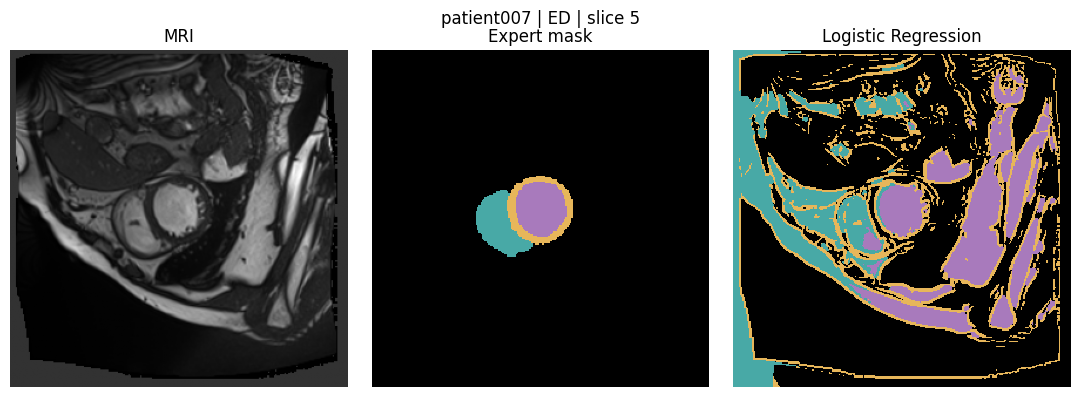

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
pid = val_ids[0]
example_volume, example_truth = load_processed_pair(pid, "ED")
k = example_volume.shape[2] // 2
example_prediction = lr_model.predict(
    extract_pixel_features(example_volume[:, :, k])
).reshape(example_volume.shape[:2])
cmap = ListedColormap(["black", "#48A9A6", "#E7B65A", "#A87ABC"])
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, array, title in zip(axes, [example_volume[:, :, k], example_truth[:, :, k], example_prediction], ["MRI", "Expert mask", "Logistic Regression"]):
    if title == "MRI":
        ax.imshow(array.T, cmap="gray", origin="lower")
    else:
        ax.imshow(array.T, cmap=cmap, vmin=0, vmax=3, interpolation="nearest", origin="lower")
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"{pid} | ED | slice {k}")
plt.tight_layout()
fig.savefig(experiment_dir / "lr_prediction_example.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.3 Random Forest tuning and validation

**Random Forest search**

Train all eight settings on the same samples and score each on training and validation volumes, recording the time taken. We pick the highest validation mean Dice; if two were exactly tied, the smaller forest would win.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
completed_path = experiment_dir / 'rf_completed_results.csv'
if completed_path.is_file():
    rf_results = pd.read_csv(completed_path)
    assert len(rf_results) == 8 and rf_results['run_id'].nunique() == 8
else:
    from sklearn.ensemble import RandomForestClassifier
    rf_rows = []
    for index, config in enumerate(rf_configs, start=1):
        run_id = f"RF_{index:02d}"
        print(run_id, config, flush=True)
        forest = RandomForestClassifier(**config, n_jobs=-1, random_state=42)
        start = perf_counter()
        forest.fit(X_train, y_train)
        fit_seconds = perf_counter() - start
        joblib.dump(forest, experiment_dir / f"{run_id}.joblib")
        row = {"run_id": run_id, **config, "fit_seconds": fit_seconds}
        for split_name, ids in [("train", train_ids), ("val", val_ids)]:
            volumes, patients, summary, timing = evaluate_segmentation(forest, ids)
            volumes.to_csv(experiment_dir / f"{run_id}_{split_name}_volumes.csv", index=False)
            patients.to_csv(experiment_dir / f"{run_id}_{split_name}_patients.csv", index=False)
            summary.to_csv(experiment_dir / f"{run_id}_{split_name}_summary.csv")
            for structure in STRUCTURES.values():
                for metric in ["dice", "precision", "recall"]:
                    row[f"{split_name}_{metric}_{structure}"] = summary.loc[structure, metric]
            for metric in ["dice", "precision", "recall"]:
                row[f"{split_name}_mean_{metric}"] = summary.loc["Mean foreground", metric]
            row[f"{split_name}_predict_seconds"] = timing["predict_seconds"]
            row[f"{split_name}_evaluation_seconds"] = timing["total_evaluation_seconds"]
        rf_rows.append(row)
        rf_results = pd.DataFrame(rf_rows)
        rf_results.to_csv(experiment_dir / "rf_completed_results.csv", index=False)
        print(run_id, "validation Dice:", round(row["val_mean_dice"], 4), flush=True)

ranked_rf = rf_results.sort_values(
    ["val_mean_dice", "n_estimators", "max_depth", "min_samples_leaf"],
    ascending=[False, True, True, False]
)
best_rf_row = ranked_rf.iloc[0]
best_rf_model = joblib.load(experiment_dir / f"{best_rf_row['run_id']}.joblib")
ranked_rf.to_csv(experiment_dir / "rf_ranked_results.csv", index=False)
with open(experiment_dir / "rf_selection.txt", "w") as file:
    file.write(f"Selected {best_rf_row['run_id']} by highest patient-averaged mean foreground validation Dice: {best_rf_row['val_mean_dice']:.6f}. Exact ties prefer fewer trees, shallower depth, then larger leaves.")
display(ranked_rf[["run_id", "n_estimators", "max_depth", "min_samples_leaf", "train_mean_dice", "val_mean_dice", "fit_seconds"]])

RF_01 {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 50}
Evaluated 1/80 patients
Evaluated 2/80 patients
Evaluated 3/80 patients
Evaluated 4/80 patients
Evaluated 5/80 patients
Evaluated 6/80 patients
Evaluated 7/80 patients
Evaluated 8/80 patients
Evaluated 9/80 patients
Evaluated 10/80 patients
Evaluated 11/80 patients
Evaluated 12/80 patients
Evaluated 13/80 patients
Evaluated 14/80 patients
Evaluated 15/80 patients
Evaluated 16/80 patients
Evaluated 17/80 patients
Evaluated 18/80 patients
Evaluated 19/80 patients
Evaluated 20/80 patients
Evaluated 21/80 patients
Evaluated 22/80 patients
Evaluated 23/80 patients
Evaluated 24/80 patients
Evaluated 25/80 patients
Evaluated 26/80 patients
Evaluated 27/80 patients
Evaluated 28/80 patients
Evaluated 29/80 patients
Evaluated 30/80 patients
Evaluated 31/80 patients
Evaluated 32/80 patients
Evaluated 33/80 patients
Evaluated 34/80 patients
Evaluated 35/80 patients
Evaluated 36/80 patients
Evaluated 37/80 patients
Evaluated 38/80 p

,run_id,n_estimators,max_depth,min_samples_leaf,train_mean_dice,val_mean_dice,fit_seconds
5,RF_06,100,20,2,0.405406,0.346771,196.444451
7,RF_08,100,20,5,0.402022,0.346553,202.061046
4,RF_05,50,20,2,0.405221,0.346444,103.045439
6,RF_07,50,20,5,0.401519,0.346246,100.054627
3,RF_04,100,10,5,0.354836,0.321731,139.946809
1,RF_02,100,10,2,0.354875,0.321558,141.122817
0,RF_01,50,10,2,0.354583,0.321430,68.934212
2,RF_03,50,10,5,0.352816,0.319249,68.439841


**Random Forest against Logistic Regression**

The selected forest (RF_06) on the same validation slice as before, plus its full validation scores.

Selected Random Forest: RF_06


,dice,precision,recall
structure,,,
RV,0.2564,0.1661,0.6923
Myocardium,0.2859,0.1802,0.7281
LV,0.4980,0.4283,0.7251
Mean foreground,0.3468,0.2582,0.7152


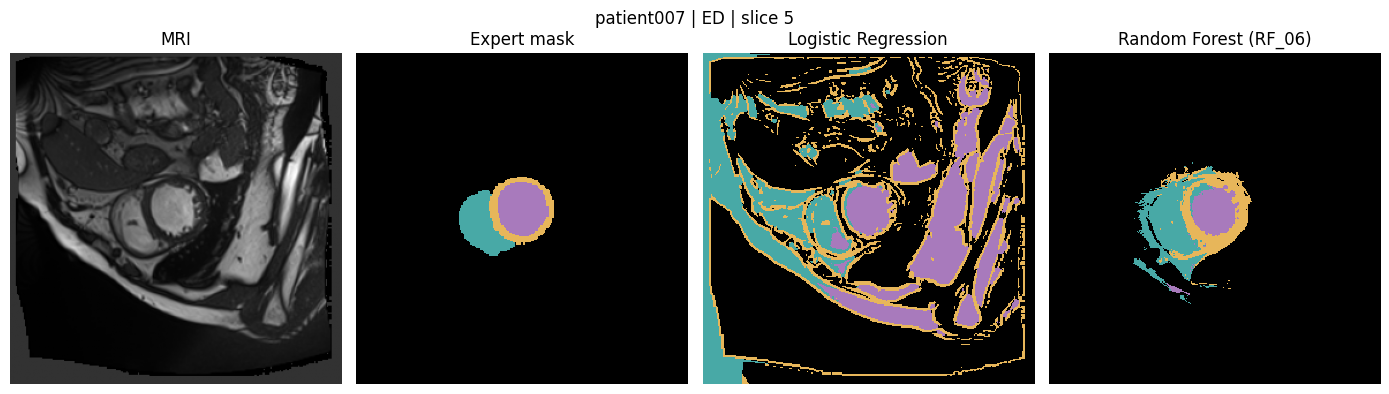

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

best_run = str(best_rf_row["run_id"])

rf_summary = pd.read_csv(
    experiment_dir / f"{best_run}_val_summary.csv",
    index_col=0
)
print("Selected Random Forest:", best_run)
display(rf_summary.round(4))

# Same patient and slice used in the Logistic Regression figure.
pid = val_ids[0]
volume, truth = load_processed_pair(pid, "ED")
k = volume.shape[2] // 2

features = extract_pixel_features(volume[:, :, k])
lr_prediction = lr_model.predict(features).reshape(volume.shape[:2])
rf_prediction = best_rf_model.predict(features).reshape(
    volume.shape[:2]
)

cmap = ListedColormap([
    "black", "#48A9A6", "#E7B65A", "#A87ABC"
])

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

panels = [
    ("MRI", volume[:, :, k]),
    ("Expert mask", truth[:, :, k]),
    ("Logistic Regression", lr_prediction),
    (f"Random Forest ({best_run})", rf_prediction)
]

for ax, (title, array) in zip(axes, panels):
    if title == "MRI":
        ax.imshow(array.T, cmap="gray", origin="lower")
    else:
        ax.imshow(
            array.T, cmap=cmap, vmin=0, vmax=3,
            interpolation="nearest", origin="lower"
        )
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"{pid} | ED | slice {k}")
plt.tight_layout()
fig.savefig(
    experiment_dir / "classical_model_comparison.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

Load RF_06's saved validation scores, per patient and per volume.

In [ ]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/"
    "random_forest_20261106_151100_091562"
)

# Load RF_06 validation results
patient_file = RUN_DIR / "RF_06_val_patients.csv"
volume_file = RUN_DIR / "RF_06_val_volumes.csv"

patient_df = pd.read_csv(patient_file)
volume_df = pd.read_csv(volume_file)

print("RF_06 VALIDATION — PATIENT RESULTS")
print("Shape:", patient_df.shape)
display(patient_df.head(10))

print("\nRF_06 VALIDATION — VOLUME RESULTS")
print("Shape:", volume_df.shape)
display(volume_df.head(10))

print("\nPATIENT CSV COLUMNS:")
print(patient_df.columns.tolist())

print("\nVOLUME CSV COLUMNS:")
print(volume_df.columns.tolist())

RF_06 VALIDATION — PATIENT RESULTS
Shape: (60, 5)


,patient_id,structure,dice,precision,recall
0,patient007,LV,0.750465,0.751166,0.750555
1,patient007,Myocardium,0.456487,0.302628,0.928885
2,patient007,RV,0.438293,0.301465,0.815487
3,patient008,LV,0.542673,0.681119,0.451378
4,patient008,Myocardium,0.445944,0.288625,0.980602
5,patient008,RV,0.371607,0.239720,0.878515
6,patient011,LV,0.469918,0.477585,0.462817
7,patient011,Myocardium,0.292039,0.183107,0.721026
8,patient011,RV,0.326759,0.198880,0.921606
9,patient015,LV,0.679308,0.616257,0.758004



RF_06 VALIDATION — VOLUME RESULTS
Shape: (120, 6)


,patient_id,phase,structure,dice,precision,recall
0,patient007,ED,RV,0.510041,0.362486,0.860195
1,patient007,ED,Myocardium,0.460475,0.306798,0.922628
2,patient007,ED,LV,0.780746,0.798679,0.763600
3,patient007,ES,RV,0.366544,0.240444,0.770779
4,patient007,ES,Myocardium,0.452498,0.298458,0.935142
5,patient007,ES,LV,0.720184,0.703653,0.737511
6,patient008,ED,RV,0.452364,0.305433,0.871707
7,patient008,ED,Myocardium,0.437058,0.281420,0.977860
8,patient008,ED,LV,0.602765,0.737808,0.509509
9,patient008,ES,RV,0.290849,0.174007,0.885324



PATIENT CSV COLUMNS:
['patient_id', 'structure', 'dice', 'precision', 'recall']

VOLUME CSV COLUMNS:
['patient_id', 'phase', 'structure', 'dice', 'precision', 'recall']


Average RF_06's scores by structure and by phase, and find its weakest patient-structure pairs.

In [ ]:
# Average performance for each cardiac structure
print("RF_06 — PERFORMANCE BY STRUCTURE")

structure_summary = (
    patient_df
    .groupby("structure")[["dice", "precision", "recall"]]
    .agg(["mean", "std"])
    .round(4)
)

display(structure_summary)

# Performance by structure and cardiac phase
print("\nRF_06 — PERFORMANCE BY STRUCTURE AND PHASE")

phase_summary = (
    volume_df
    .groupby(["phase", "structure"])[
        ["dice", "precision", "recall"]
    ]
    .mean()
    .round(4)
)

display(phase_summary)

# Identify the five worst patient-structure combinations
print("\nFIVE LOWEST PATIENT-LEVEL DICE SCORES")

worst_cases = (
    patient_df
    .sort_values("dice", ascending=True)
    .head(5)
)

display(worst_cases)

RF_06 — PERFORMANCE BY STRUCTURE


dice         precision          recall        
              mean     std      mean     std    mean     std
structure                                                   
LV          0.4980  0.1479    0.4283  0.1685  0.7251  0.2221
Myocardium  0.2859  0.1269    0.1802  0.0876  0.7281  0.2335
RV          0.2564  0.1545    0.1661  0.1119  0.6923  0.2781


RF_06 — PERFORMANCE BY STRUCTURE AND PHASE


dice  precision  recall
phase structure                            
ED    LV          0.5922     0.5281  0.7551
      Myocardium  0.2790     0.1760  0.7114
      RV          0.3229     0.2159  0.7108
ES    LV          0.4038     0.3285  0.6952
      Myocardium  0.2928     0.1845  0.7447
      RV          0.1900     0.1164  0.6737


FIVE LOWEST PATIENT-LEVEL DICE SCORES


,patient_id,structure,dice,precision,recall
52,patient094,Myocardium,0.026910,0.015415,0.105842
32,patient049,RV,0.039147,0.021236,0.306619
29,patient047,RV,0.044544,0.025933,0.173356
53,patient094,RV,0.049486,0.029946,0.149785
26,patient044,RV,0.087404,0.050190,0.401713


Dice per structure for all eight forest settings on the same 20 validation patients.

In [ ]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/"
    "random_forest_20261106_151100_091562"
)

all_rf_results = []

for i in range(1, 9):

    rf_name = f"RF_{i:02d}"
    file_path = RUN_DIR / f"{rf_name}_val_patients.csv"

    df = pd.read_csv(file_path)

    summary = (
        df.groupby("structure")[["dice", "precision", "recall"]]
        .mean()
        .reset_index()
    )

    summary["model"] = rf_name
    all_rf_results.append(summary)

rf_comparison = pd.concat(
    all_rf_results,
    ignore_index=True
)

rf_dice_comparison = rf_comparison.pivot(
    index="model",
    columns="structure",
    values="dice"
).round(4)

print("DICE COMPARISON — ALL RANDOM FOREST CONFIGURATIONS")
display(rf_dice_comparison)

print("\nOVERALL MEAN DICE RANKING")

overall_ranking = (
    rf_comparison
    .groupby("model")["dice"]
    .mean()
    .sort_values(ascending=False)
    .round(4)
    .reset_index(name="mean_foreground_dice")
)

display(overall_ranking)

DICE COMPARISON — ALL RANDOM FOREST CONFIGURATIONS


structure,LV,Myocardium,RV
model,,,
RF_01,0.4748,0.2476,0.2419
RF_02,0.4744,0.2482,0.2421
RF_03,0.4732,0.2451,0.2394
RF_04,0.4746,0.2468,0.2438
RF_05,0.4979,0.2855,0.2560
RF_06,0.4980,0.2859,0.2564
RF_07,0.4993,0.2841,0.2553
RF_08,0.4994,0.2848,0.2555



OVERALL MEAN DICE RANKING


,model,mean_foreground_dice
0,RF_06,0.3468
1,RF_08,0.3466
2,RF_05,0.3464
3,RF_07,0.3462
4,RF_04,0.3217
5,RF_02,0.3216
6,RF_01,0.3214
7,RF_03,0.3192


Rank the validation patients from worst to best for RF_06 and look at each structure separately.

In [ ]:
# Patient-level RF_06 validation scores (one row per patient and structure)
rf06_df = pd.read_csv(RUN_DIR / "RF_06_val_patients.csv")


# Patient-level performance analysis for RF_06

# 1. Mean Dice across the three structures for each patient
patient_summary = (
    rf06_df.groupby("patient_id")
    .agg(
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean")
    )
    .sort_values("mean_dice")
    .round(4)
)

print("PATIENT PERFORMANCE — WORST TO BEST")
display(patient_summary)

# 2. Individual structure performance for every patient
patient_structure_dice = rf06_df.pivot(
    index="patient_id",
    columns="structure",
    values="dice"
).round(4)

print("\nDICE PER PATIENT AND STRUCTURE")
display(patient_structure_dice)

# 3. Five weakest patients for each structure
for structure in ["LV", "Myocardium", "RV"]:
    print(f"\nFIVE WORST PATIENTS — {structure}")

    worst_patients = (
        rf06_df[rf06_df["structure"] == structure]
        .nsmallest(5, "dice")
        [["patient_id", "dice", "precision", "recall"]]
        .round(4)
    )

    display(worst_patients)


PATIENT PERFORMANCE — WORST TO BEST


,mean_dice,mean_precision,mean_recall
patient_id,,,
patient094,0.1412,0.0857,0.4176
patient084,0.1520,0.0934,0.4999
patient047,0.1730,0.1460,0.3594
patient022,0.2023,0.1210,0.7301
patient058,0.2527,0.1963,0.5898
patient063,0.2754,0.1878,0.6905
patient044,0.2915,0.1891,0.7212
patient049,0.3038,0.2121,0.6620
patient038,0.3260,0.2281,0.6843



DICE PER PATIENT AND STRUCTURE


structure,LV,Myocardium,RV
patient_id,,,
patient007,0.7505,0.4565,0.4383
patient008,0.5427,0.4459,0.3716
patient011,0.4699,0.2920,0.3268
patient015,0.6793,0.3101,0.1683
patient021,0.6631,0.4612,0.2722
patient022,0.3009,0.1523,0.1538
patient032,0.5161,0.5241,0.2807
patient038,0.4483,0.2699,0.2599
patient044,0.5097,0.2774,0.0874



FIVE WORST PATIENTS — LV


,patient_id,dice,precision,recall
48,patient084,0.2068,0.1225,0.7756
27,patient047,0.2920,0.3053,0.2807
15,patient022,0.3009,0.1848,0.9492
51,patient094,0.3471,0.2118,0.9973
42,patient075,0.3500,0.3060,0.4194



FIVE WORST PATIENTS — Myocardium


,patient_id,dice,precision,recall
52,patient094,0.0269,0.0154,0.1058
49,patient084,0.1041,0.0591,0.4388
16,patient022,0.1523,0.0928,0.4261
34,patient058,0.1568,0.0954,0.4408
28,patient047,0.1823,0.1068,0.6243



FIVE WORST PATIENTS — RV


,patient_id,dice,precision,recall
32,patient049,0.0391,0.0212,0.3066
29,patient047,0.0445,0.0259,0.1734
53,patient094,0.0495,0.0299,0.1498
26,patient044,0.0874,0.0502,0.4017
38,patient063,0.1284,0.0762,0.4803


Compare ED with ES for RF_06 and find the weakest patient-phase combinations.

In [ ]:
# Volume-level RF_06 validation scores (one row per patient, phase and structure)
rf06_volumes = pd.read_csv(RUN_DIR / "RF_06_val_volumes.csv")


# RF_06: Cardiac phase and structure analysis

# 1. Performance by cardiac phase
phase_summary = (
    rf06_volumes.groupby("phase")[["dice", "precision", "recall"]]
    .mean()
    .round(4)
)

print("PERFORMANCE BY CARDIAC PHASE")
display(phase_summary)


# 2. Performance by structure and phase
structure_phase_summary = (
    rf06_volumes.groupby(["phase", "structure"])
    [["dice", "precision", "recall"]]
    .mean()
    .round(4)
)

print("\nPERFORMANCE BY PHASE AND STRUCTURE")
display(structure_phase_summary)


# 3. Dice comparison table
phase_dice_comparison = (
    rf06_volumes.pivot_table(
        index="structure",
        columns="phase",
        values="dice",
        aggfunc="mean"
    )
    .round(4)
)

print("\nDICE COMPARISON: ED VS ES")
display(phase_dice_comparison)


# 4. Mean Dice for each patient and cardiac phase
patient_phase_summary = (
    rf06_volumes.groupby(["patient_id", "phase"])["dice"]
    .mean()
    .reset_index(name="mean_dice")
    .sort_values("mean_dice")
    .round(4)
)

print("\nPATIENT-PHASE PERFORMANCE — WORST TO BEST")
display(patient_phase_summary)


# 5. Ten worst individual volume measurements
print("\nTEN WORST VOLUME-LEVEL RESULTS")

worst_volumes = (
    rf06_volumes.nsmallest(10, "dice")
    [["patient_id", "phase", "structure",
      "dice", "precision", "recall"]]
    .round(4)
)

display(worst_volumes)


PERFORMANCE BY CARDIAC PHASE


,dice,precision,recall
phase,,,
ED,0.3980,0.3067,0.7258
ES,0.2955,0.2098,0.7045



PERFORMANCE BY PHASE AND STRUCTURE


dice  precision  recall
phase structure                            
ED    LV          0.5922     0.5281  0.7551
      Myocardium  0.2790     0.1760  0.7114
      RV          0.3229     0.2159  0.7108
ES    LV          0.4038     0.3285  0.6952
      Myocardium  0.2928     0.1845  0.7447
      RV          0.1900     0.1164  0.6737


DICE COMPARISON: ED VS ES


phase,ED,ES
structure,,
LV,0.5922,0.4038
Myocardium,0.2790,0.2928
RV,0.3229,0.1900



PATIENT-PHASE PERFORMANCE — WORST TO BEST


,patient_id,phase,mean_dice
35,patient094,ES,0.1176
33,patient084,ES,0.1410
11,patient022,ES,0.1562
32,patient084,ED,0.1630
34,patient094,ED,0.1647
25,patient063,ES,0.1701
18,patient047,ED,0.1703
19,patient047,ES,0.1756
23,patient058,ES,0.2051
10,patient022,ED,0.2484



TEN WORST VOLUME-LEVEL RESULTS


,patient_id,phase,structure,dice,precision,recall
63,patient049,ES,RV,0.0120,0.0062,0.2333
106,patient094,ES,Myocardium,0.0249,0.0142,0.0992
57,patient047,ES,RV,0.0262,0.0143,0.1530
103,patient094,ED,Myocardium,0.0290,0.0166,0.1125
105,patient094,ES,RV,0.0424,0.0244,0.1594
51,patient044,ES,RV,0.0449,0.0239,0.3727
75,patient063,ES,RV,0.0486,0.0260,0.3683
102,patient094,ED,RV,0.0566,0.0355,0.1402
54,patient047,ED,RV,0.0629,0.0375,0.1937
60,patient049,ED,RV,0.0663,0.0363,0.3799


RF_06 (100 trees, depth 20, minimum leaf size 2) had the best validation mean Dice, **0.3468**. It did better at ED than at ES (0.3980 against 0.2955), and the LV was its strongest structure. Patients 094, 084 and 047 were difficult for it, as the tables above show.

## <span style="color:#247C87">7. U-Net models</span>

U-Net uses an ImageNet-pretrained ResNet-34 encoder, a segmentation decoder, one MRI channel, and four output classes. All parameters are fine-tuned. The encoder learning rate is 0.0001; the decoder and output head use 0.001. Training uses cross-entropy plus foreground Dice loss.

The recorded run used 20 epochs and took 23.48 minutes. Its lowest validation loss was **0.1237 at epoch 12**. Loss measures the training objective and is not a hard-prediction Dice score.

### 7.1 Original ResNet-34 U-Net

**Model and environment**

Load the U-Net with an ImageNet-pretrained ResNet-34 encoder (from the segmentation_models_pytorch library), set it to one input channel and four output classes, and count its parameters. A random input checks the output shape. This check happened to run on a CPU session; the actual training later ran on a T4 GPU.

In [ ]:
!pip install -q segmentation-models-pytorch
import torch, torchvision
import torch.nn.functional as F
import segmentation_models_pytorch as smp

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| smp", smp.__version__)
print("GPU available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

torch.manual_seed(42)
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=1, classes=4)

def n_params(m):
    return sum(p.numel() for p in m.parameters())
print("\nParameters (millions): total", round(n_params(model) / 1e6, 2),
      "| encoder", round(n_params(model.encoder) / 1e6, 2),
      "| decoder", round(n_params(model.decoder) / 1e6, 2),
      "| output head", round(n_params(model.segmentation_head) / 1e6, 3))

try:
    print("First conv weight shape:", tuple(model.encoder.conv1.weight.shape))   # expect (64, 1, 7, 7)
except Exception as e:
    print("Could not read first conv:", e)
try:
    print("Pretrained settings:", smp.encoders.encoders["resnet34"]["pretrained_settings"]["imagenet"])
except Exception as e:
    print("Weight-source info not available in this version:", e)

# One random batch: 2 single-channel 288x288 slices, random labels 0-3
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device).eval()
x = torch.randn(2, 1, 288, 288, device=device)
y = torch.randint(0, 4, (2, 288, 288), device=device)
with torch.no_grad():
    out = model(x)
print("\nOutput shape:", tuple(out.shape), "| all finite:", bool(torch.isfinite(out).all()))
print("Cross-entropy loss on random labels:", float(F.cross_entropy(out, y)))

torch 2.14.1+cpu | torchvision 0.29.1+cpu | smp 0.6.0
GPU available: False | CPU only


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


Parameters (millions): total 24.43 | encoder 21.28 | decoder 3.15 | output head 0.001
First conv weight shape: (64, 1, 7, 7)
Pretrained settings: {'repo_id': 'smp-hub/resnet34.imagenet', 'revision': '7a57b34f723329ff020b3f8bc41771163c519d0c'}

Output shape: (2, 4, 288, 288) | all finite: True
Cross-entropy loss on random labels: 1.4860082864761353


**What the processed files contain**

A look inside the saved files: one image array, one mask array, the affine, and a text record of every preprocessing setting.

In [ ]:
import json, re
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

PROC_DIR = Path('/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288')
assert PROC_DIR.exists(), "Folder not found: check the Drive is mounted and the path is right."

files = sorted(f for f in PROC_DIR.rglob('*') if f.is_file())
rel = [f.relative_to(PROC_DIR) for f in files]
print("Files:", len(files), "| types:", dict(Counter(f.suffix for f in files)))
print("Example paths:", [str(p) for p in rel[:4]])
ids = sorted({m.group(0) for p in rel for m in [re.search(r'patient\d{3}', str(p))] if m})
print("Distinct patient IDs in paths:", len(ids), "| first/last:", ids[:1], ids[-1:])
phases = Counter(f.stem for f in files if f.suffix == '.npz')
print("Files per phase name:", dict(phases))

# Every entry of the first .npz (nothing is modified)
npz = [f for f in files if f.suffix == '.npz']
f = npz[0]
print("\nInspecting:", f.relative_to(PROC_DIR))
d = np.load(f, allow_pickle=False)
print("Entries in file:", d.files)
for k in d.files:
    try:
        a = d[k]
    except Exception as e:
        print(f"  {k}: could not be read without pickle ({e})")
        continue
    if a.dtype.kind in 'USO':
        txt = str(a.item() if a.shape == () else a.tolist())
        print(f"  {k}: text, {len(txt)} characters:\n    {txt[:700]}")
    else:
        extra = f", values {np.unique(a).tolist()}" if a.dtype.kind in 'iu' and a.size else ""
        print(f"  {k}: shape {a.shape}, dtype {a.dtype}, min {a.min():.3g}, max {a.max():.3g}, finite {bool(np.isfinite(a).all())}{extra}")

# Index / metadata / config files
for f in files:
    if f.suffix == '.csv':
        t = pd.read_csv(f)
        print(f"\nCSV {f.relative_to(PROC_DIR)}: {t.shape[0]} rows; columns: {list(t.columns)}")
        print(t.head(4).to_string())
    elif f.suffix == '.json':
        j = json.loads(f.read_text())
        print(f"\nJSON {f.relative_to(PROC_DIR)}: " + (f"keys {list(j.keys())[:15]}" if isinstance(j, dict) else f"list of {len(j)} items"))

Files: 201 | types: {'.npz': 200, '.csv': 1}
Example paths: ['patient001/ED.npz', 'patient001/ES.npz', 'patient002/ED.npz', 'patient002/ES.npz']
Distinct patient IDs in paths: 100 | first/last: ['patient001'] ['patient100']
Files per phase name: {'ED': 100, 'ES': 100}

Inspecting: patient001/ED.npz
Entries in file: ['image', 'mask', 'affine', 'metadata']
  image: shape (288, 288, 10), dtype float32, min -0.934, max 6.29, finite True
  mask: shape (288, 288, 10), dtype uint8, min 0, max 3, finite True, values [0, 1, 2, 3]
  affine: shape (4, 4), dtype float64, min -1.5, max 46.5, finite True
  metadata: text, 483 characters:
    {"original_shape": [216, 256, 10], "resampled_shape": [225, 267, 10], "final_shape": [288, 288, 10], "original_spacing": [1.5625, 1.5625, 10.0], "target_spacing": 1.5, "effective_spacing": [1.4997209821428572, 1.4978853383458648, 10.0], "intensity_mean": 82.16265106201172, "intensity_std": 87.93397521972656, "crop_start": [0, 0], "padding": [31, 32, 10, 11], "fo

**Copying the data to Colab**

Copy the processed files to Colab's local disk, which is much faster to read during training, and check that the saved metadata adds up.

In [ ]:
import ast, json, shutil, time
import numpy as np
import pandas as pd
from pathlib import Path

PROC_DRIVE = Path('/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288')
PROC_LOCAL = Path('/content/acdc_pre288')

if not PROC_LOCAL.exists():
    t0 = time.time(); shutil.copytree(PROC_DRIVE, PROC_LOCAL)
    print("Copied to local disk in", round(time.time() - t0), "s")
else:
    print("Local copy already exists")

data_path = Path('/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads')
split = pd.read_csv(data_path / 'patient_split_seed42.csv')
summary = pd.read_csv(PROC_LOCAL / 'preprocessing_summary.csv')

print("\nSplit counts:", split['split'].value_counts().to_dict())
print("Patients in split == patients in folder:", set(split['patient_id']) == set(summary['patient']))
print("Every patient has ED and ES:", bool((summary.groupby('patient')['phase'].nunique() == 2).all()))
print("Volumes with finite=False:", int((~summary['finite']).sum()),
      "| volumes with foreground_lost=True:", int(summary['foreground_lost'].sum()))

shapes = summary['shape'].map(ast.literal_eval)
print("All in-plane sizes 288x288:", bool(shapes.map(lambda s: s[:2] == (288, 288)).all()),
      "| slices per volume:", min(s[2] for s in shapes), "-", max(s[2] for s in shapes))
summary['n_slices'] = shapes.map(lambda s: s[2])
m = summary.merge(split[['patient_id', 'split']], left_on='patient', right_on='patient_id')
print("2D slices per split:", m.groupby('split')['n_slices'].sum().to_dict())

# Metadata of every file (only the small text entry is read)
bad, cropped = [], []
tspacing, stds = set(), []
for r in summary.itertuples():
    with np.load(PROC_LOCAL / r.patient / f'{r.phase}.npz') as d:
        md = json.loads(str(d['metadata']))
    tspacing.add(md['target_spacing']); stds.append(md['intensity_std'])
    if md['final_shape'][:2] != [288, 288]:
        bad.append((r.patient, r.phase, 'final shape'))
    if md['foreground_before_crop'] != md['foreground_after_crop']:
        bad.append((r.patient, r.phase, 'foreground changed by crop'))
    p = md['padding']
    if md['crop_start'] == [0, 0]:
        ok = (md['resampled_shape'][0] + p[0] + p[1] == 288) and (md['resampled_shape'][1] + p[2] + p[3] == 288)
        if not ok:
            bad.append((r.patient, r.phase, 'padding does not add up'))
    else:
        cropped.append((r.patient, r.phase, md['resampled_shape'][:2], md['crop_start'], p))
print("\nTarget spacings seen:", tspacing, "| smallest intensity_std:", round(min(stds), 2))
print("Metadata problems:", bad if bad else "none")
print("Volumes with a non-zero crop_start:", len(cropped))
for c in cropped[:12]:
    print("  ", c)

Local copy already exists

Split counts: {'train': 80, 'validation': 20}
Patients in split == patients in folder: True
Every patient has ED and ES: True
Volumes with finite=False: 0 | volumes with foreground_lost=True: 0
All in-plane sizes 288x288: True | slices per volume: 6 - 18
2D slices per split: {'train': 1504, 'validation': 398}

Target spacings seen: {1.5} | smallest intensity_std: 24.87
Metadata problems: none
Volumes with a non-zero crop_start: 10
   ('patient006', 'ED', [272, 300], [0, 6], [8, 8, 0, 0])
   ('patient006', 'ES', [272, 300], [0, 6], [8, 8, 0, 0])
   ('patient020', 'ED', [244, 300], [0, 6], [22, 22, 0, 0])
   ('patient020', 'ES', [244, 300], [0, 6], [22, 22, 0, 0])
   ('patient037', 'ED', [270, 320], [0, 16], [9, 9, 0, 0])
   ('patient037', 'ES', [270, 320], [0, 16], [9, 9, 0, 0])
   ('patient042', 'ED', [272, 300], [0, 6], [8, 8, 0, 0])
   ('patient042', 'ES', [272, 300], [0, 6], [8, 8, 0, 0])
   ('patient080', 'ED', [253, 300], [0, 6], [17, 18, 0, 0])
   ('pat

**Slice dataset**

The U-Net works on 2D slices. This dataset returns one slice at a time with its mask, and keeps track of which patient, phase and slice it came from. All validation slices are kept, including ones with no heart in them.

Split variable created: True
Columns: ['patient_id', 'condition', 'split']
Patient counts: {'train': 80, 'validation': 20}
Training slices: 1504 | validation slices: 398
patient026 ES slice 0: x (1, 288, 288) torch.float32, y (288, 288) torch.int64, labels [0], mean brightness per label {0: 0.11}
patient051 ED slice 6: x (1, 288, 288) torch.float32, y (288, 288) torch.int64, labels [0, 1, 2, 3], mean brightness per label {0: -0.04, 1: 0.9, 2: 0.31, 3: 1.54}
patient078 ES slice 2: x (1, 288, 288) torch.float32, y (288, 288) torch.int64, labels [0, 1, 2, 3], mean brightness per label {0: -0.03, 1: 1.96, 2: 0.98, 3: 2.06}


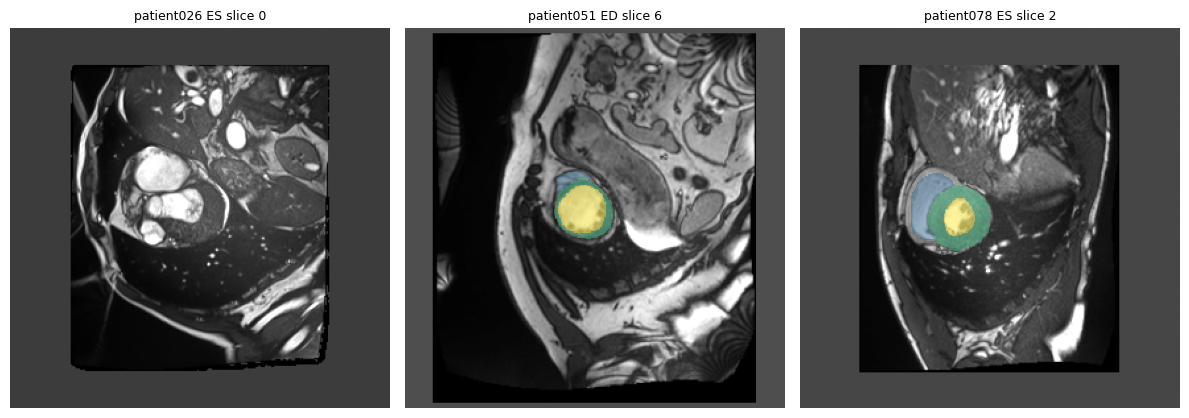


Batch: (8, 1, 288, 288) torch.float32 | masks (8, 288, 288) torch.int64 | finite: True
First items in batch: [('patient001', 'ED', 0), ('patient001', 'ED', 1), ('patient001', 'ED', 2)]


In [ ]:

import pandas as pd
from pathlib import Path

# Explicitly load the patient split into memory
split_path = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads/patient_split_seed42.csv"
)

split = pd.read_csv(split_path)

print("Split variable created:", isinstance(split, pd.DataFrame))
print("Columns:", split.columns.tolist())
print("Patient counts:", split["split"].value_counts().to_dict())
import ast
import numpy as np
import torch
import matplotlib.pyplot as plt
from functools import lru_cache
from torch.utils.data import Dataset, DataLoader

@lru_cache(maxsize=48)                                   # keeps recent volumes in memory, not all 200
def load_volume_arrays(path):
    with np.load(path) as d:
        return d['image'], d['mask']

class ACDCSlices(Dataset):
    """One item = one 2D slice: image (1,288,288) float32, mask (288,288) int64 labels 0-3, plus patient, phase, slice index."""
    def __init__(self, root, patient_ids, summary):
        self.root = Path(root)
        rows = summary[summary['patient'].isin(patient_ids)].sort_values(['patient', 'phase'])
        self.items = [(r.patient, r.phase, k) for r in rows.itertuples()
                      for k in range(ast.literal_eval(r.shape)[2])]      # every slice is kept
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        pid, ph, k = self.items[i]
        img, msk = load_volume_arrays(str(self.root / pid / f'{ph}.npz'))
        x = torch.from_numpy(np.ascontiguousarray(img[:, :, k])).unsqueeze(0)
        y = torch.from_numpy(msk[:, :, k].astype(np.int64))
        return x, y, pid, ph, k

train_ids = split.loc[split['split'] == 'train', 'patient_id'].tolist()
val_ids = split.loc[split['split'] == 'validation', 'patient_id'].tolist()
train_ds = ACDCSlices(PROC_LOCAL, train_ids, summary)
val_ds = ACDCSlices(PROC_LOCAL, val_ids, summary)
print("Training slices:", len(train_ds), "| validation slices:", len(val_ds))

# Three fixed training slices (not random, so the check is repeatable)
picks = [len(train_ds) // 4, len(train_ds) // 2, 3 * len(train_ds) // 4]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, i in zip(axes, picks):
    x, y, pid, ph, k = train_ds[i]
    img, msk = x[0].numpy(), y.numpy()
    lo, hi = np.percentile(img, [1, 99])
    ax.imshow(img.T, cmap='gray', origin='lower', vmin=lo, vmax=hi)
    ax.imshow(np.ma.masked_equal(msk, 0).T, cmap='viridis', vmin=0, vmax=3, alpha=0.45,
              interpolation='nearest', origin='lower')
    ax.set_title(f'{pid} {ph} slice {k}', fontsize=9); ax.axis('off')
    means = {int(l): round(float(img[msk == l].mean()), 2) for l in (0, 1, 2, 3) if (msk == l).any()}
    print(f"{pid} {ph} slice {k}: x {tuple(x.shape)} {x.dtype}, y {tuple(y.shape)} {y.dtype}, labels {np.unique(msk).tolist()}, mean brightness per label {means}")
plt.tight_layout(); plt.show()

# One batch from the DataLoader
xb, yb, pb, phb, kb = next(iter(DataLoader(train_ds, batch_size=8, shuffle=False)))
print("\nBatch:", tuple(xb.shape), xb.dtype, "| masks", tuple(yb.shape), yb.dtype, "| finite:", bool(torch.isfinite(xb).all()))
print("First items in batch:", list(zip(pb[:3], phb[:3], [int(k) for k in kb[:3]])))

**One forward pass**

Pass a real batch through the model to check the output has four class scores per pixel and the loss is a finite number.

In [ ]:
import torch
import torch.nn.functional as F

# Select the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to GPU and set evaluation mode
model = model.to(device)
model.eval()

# Get one real batch from the training dataset
xb, yb, patients, phases, slices = next(
    iter(DataLoader(train_ds, batch_size=8, shuffle=False))
)

# Move images and masks to GPU
xb = xb.to(device)
yb = yb.to(device)

# Forward pass
with torch.no_grad():
    logits = model(xb)
    loss = F.cross_entropy(logits, yb)

# Check results
print("Device:", device)
print("Input shape:", tuple(xb.shape))
print("Target shape:", tuple(yb.shape))
print("Output shape:", tuple(logits.shape))

print("\nInput finite:", bool(torch.isfinite(xb).all()))
print("Output finite:", bool(torch.isfinite(logits).all()))
print("Loss finite:", bool(torch.isfinite(loss)))
print("Cross-entropy loss:", round(loss.item(), 4))

print("\nTarget labels:", torch.unique(yb).tolist())
print("Predicted labels:", torch.unique(logits.argmax(dim=1)).tolist())

print("\nBatch patient identities:")
for p, ph, k in zip(patients, phases, slices):
    print(f"{p} | {ph} | slice {k}")

Device: cpu
Input shape: (8, 1, 288, 288)
Target shape: (8, 288, 288)
Output shape: (8, 4, 288, 288)

Input finite: True
Output finite: True
Loss finite: True
Cross-entropy loss: 1.7177

Target labels: [0, 1, 2, 3]
Predicted labels: [0, 1, 2, 3]

Batch patient identities:
patient001 | ED | slice 0
patient001 | ED | slice 1
patient001 | ED | slice 2
patient001 | ED | slice 3
patient001 | ED | slice 4
patient001 | ED | slice 5
patient001 | ED | slice 6
patient001 | ED | slice 7


**Data loaders**

Training slices are shuffled each epoch, validation slices stay in a fixed order. Batch size 8.

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_ds,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training slices:", len(train_ds))
print("Training batches:", len(train_loader))
print("Validation slices:", len(val_ds))
print("Validation batches:", len(val_loader))

Training slices: 1504
Training batches: 188
Validation slices: 398
Validation batches: 50


**A fresh model for training**

Create a new U-Net with the ImageNet encoder weights for the training run, and check it once on a real batch.

In [ ]:
# Recreate a fresh U-Net with ImageNet-pretrained ResNet34 encoder
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=4
).to(device)

# Check the model using a real training batch
model.eval()

images, masks, _, _, _ = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)
    loss = F.cross_entropy(logits, masks)

print("Fresh model initialized successfully.")
print("Device:", device)
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 4))
print("Output finite:", torch.isfinite(logits).all().item())
print("Loss finite:", torch.isfinite(loss).item())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Fresh model initialized successfully.
Device: cpu
Input shape: (8, 1, 288, 288)
Output shape: (8, 4, 288, 288)
Loss: 1.2761
Output finite: True
Loss finite: True


**Loss and optimizer**

The loss is cross-entropy plus a Dice loss over the three heart structures (background left out). The Dice part pushes the model to get the small structures right, even though they cover few pixels. AdamW trains all layers, with a smaller learning rate for the pretrained encoder (0.0001) than for the new decoder and output head (0.001).

In [ ]:
import torch
import torch.nn.functional as F

# Multiclass Dice loss, excluding background (class 0)
def multiclass_dice_loss(logits, targets, epsilon=1e-6):
    probabilities = torch.softmax(logits, dim=1)

    targets_one_hot = F.one_hot(
        targets,
        num_classes=4
    ).permute(0, 3, 1, 2).float()

    dimensions = (0, 2, 3)

    intersection = (probabilities * targets_one_hot).sum(dim=dimensions)

    denominator = (
        probabilities.sum(dim=dimensions)
        + targets_one_hot.sum(dim=dimensions)
    )

    dice = (2 * intersection + epsilon) / (denominator + epsilon)

    # Ignore background when calculating Dice loss
    return 1 - dice[1:].mean()


# Combined loss
def segmentation_loss(logits, targets):
    ce_loss = F.cross_entropy(logits, targets)
    dice_loss = multiclass_dice_loss(logits, targets)

    return ce_loss + dice_loss


# Make all model parameters trainable
for parameter in model.parameters():
    parameter.requires_grad = True


# AdamW optimizer with separate learning rates
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": 1e-4
        },
        {
            "params": model.decoder.parameters(),
            "lr": 1e-3
        },
        {
            "params": model.segmentation_head.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)


# Initial training configuration
EPOCHS = 20

print("Optimizer:", type(optimizer).__name__)
print("Encoder learning rate:", optimizer.param_groups[0]["lr"])
print("Decoder learning rate:", optimizer.param_groups[1]["lr"])
print("Output head learning rate:", optimizer.param_groups[2]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print("Epochs:", EPOCHS)
print("Loss: Cross-Entropy + Foreground Dice")

Optimizer: AdamW
Encoder learning rate: 0.0001
Decoder learning rate: 0.001
Output head learning rate: 0.001
Weight decay: 0.0001
Epochs: 20
Loss: Cross-Entropy + Foreground Dice


**One epoch of training and validation**

One function trains for a full pass over the training slices; the other computes the validation loss without updating the model.

In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()

    total_loss = 0.0
    total_slices = 0

    for images, masks, _, _, _ in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = segmentation_loss(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_slices += images.size(0)

    return total_loss / total_slices


def validate_one_epoch(model, loader, device):
    model.eval()

    total_loss = 0.0
    total_slices = 0

    with torch.no_grad():
        for images, masks, _, _, _ in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(images)
            loss = segmentation_loss(logits, masks)

            total_loss += loss.item() * images.size(0)
            total_slices += images.size(0)

    return total_loss / total_slices


print("Training and validation functions defined successfully.")

Training and validation functions defined successfully.


**Training**

Train for 20 epochs. After each epoch we save the latest checkpoint, and separately the one with the lowest validation loss so far. If the best checkpoint already exists, the cell loads it instead of training again.

In [ ]:
from pathlib import Path
import torch
best_path = ORIGINAL_CNN_DIR / 'best_model.pth'
if best_path.is_file():
    checkpoint = torch.load(best_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    original_history = pd.read_csv(ORIGINAL_CNN_DIR / 'training_history.csv')
    display(original_history.round(4))
    print('Selected epoch:', checkpoint['epoch'])
    print('Best validation loss:', checkpoint['best_val_loss'])
    print('Checkpoint:', best_path)
else:
    import os
    import pandas as pd
    import time

    # Check that Google Drive is mounted
    assert os.path.isdir("/content/drive/MyDrive"), (
        "Google Drive is not mounted. Please mount Drive before training."
    )

    # Create a separate experiment folder
    checkpoint_dir = (
        "/content/drive/MyDrive/ACDC dataset/"
        "ACDC_experiments/unet_resnet34_seed42"
    )

    os.makedirs(checkpoint_dir, exist_ok=True)

    best_checkpoint_path = os.path.join(
        checkpoint_dir, "best_model.pth"
    )

    last_checkpoint_path = os.path.join(
        checkpoint_dir, "last_checkpoint.pth"
    )

    history_path = os.path.join(
        checkpoint_dir, "training_history.csv"
    )

    # Training history
    history = []
    best_val_loss = float("inf")

    print("Starting full training...")
    print("Training slices:", len(train_ds))
    print("Validation slices:", len(val_ds))
    print("Epochs:", EPOCHS)
    print("Checkpoint folder:", checkpoint_dir)

    start_time = time.time()

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model, train_loader, optimizer, device
        )

        val_loss = validate_one_epoch(
            model, val_loader, device
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        # Save the best model based on validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "history": history
            }, best_checkpoint_path)

            best_message = " | Best model saved"
        else:
            best_message = ""

        # Save the latest checkpoint after every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": history
        }, last_checkpoint_path)

        # Update the CSV history
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
            f"{best_message}"
        )

    elapsed_time = (time.time() - start_time) / 60

    print("\nTraining completed.")
    print("Best validation loss:", round(best_val_loss, 4))
    print("Time elapsed:", round(elapsed_time, 2), "minutes")
    print("Best checkpoint:", best_checkpoint_path)
    print("Latest checkpoint:", last_checkpoint_path)
    print("Training history:", history_path)

Starting full training...
Training slices: 1504
Validation slices: 398
Epochs: 20
Checkpoint folder: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42
Epoch 01/20 | Train Loss: 0.5025 | Validation Loss: 0.1964 | Best model saved
Epoch 02/20 | Train Loss: 0.1502 | Validation Loss: 0.1601 | Best model saved
Epoch 03/20 | Train Loss: 0.1216 | Validation Loss: 0.1487 | Best model saved
Epoch 04/20 | Train Loss: 0.1040 | Validation Loss: 0.1621
Epoch 05/20 | Train Loss: 0.1000 | Validation Loss: 0.1611
Epoch 06/20 | Train Loss: 0.1029 | Validation Loss: 0.1395 | Best model saved
Epoch 07/20 | Train Loss: 0.0899 | Validation Loss: 0.1372 | Best model saved
Epoch 08/20 | Train Loss: 0.0818 | Validation Loss: 0.1525
Epoch 09/20 | Train Loss: 0.0817 | Validation Loss: 0.1353 | Best model saved
Epoch 10/20 | Train Loss: 0.0789 | Validation Loss: 0.1328 | Best model saved
Epoch 11/20 | Train Loss: 0.0838 | Validation Loss: 0.1634
Epoch 12/20 | Train Loss: 0.0759 | Validati

The training and validation loss curves. The marked epoch (12) has the lowest validation loss and is the one we kept.

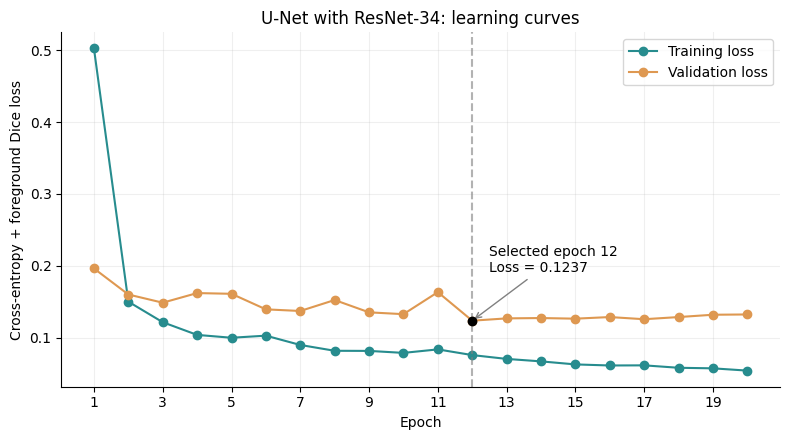

In [ ]:
FIG_DIR = CLASSICAL_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'train': '#278C8E', 'val': '#DE9851'}
history_path = Path(
    "/content/drive/MyDrive/ACDC dataset/"
    "ACDC_experiments/unet_resnet34_seed42/training_history.csv"
)

assert history_path.is_file(), (
    "The CNN training_history.csv must be available in this folder."
)

cnn_history = pd.read_csv(history_path).sort_values("epoch")
best_index = cnn_history["val_loss"].idxmin()
best_epoch = int(cnn_history.loc[best_index, "epoch"])
best_loss = float(cnn_history.loc[best_index, "val_loss"])

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    cnn_history["epoch"], cnn_history["train_loss"],
    "o-", color=COLORS["train"], label="Training loss"
)
ax.plot(
    cnn_history["epoch"], cnn_history["val_loss"],
    "o-", color=COLORS["val"], label="Validation loss"
)
ax.axvline(best_epoch, color="gray", linestyle="--", alpha=0.6)
ax.scatter(best_epoch, best_loss, color="black", zorder=5)
ax.annotate(
    f"Selected epoch {best_epoch}\nLoss = {best_loss:.4f}",
    xy=(best_epoch, best_loss),
    xytext=(12, 35), textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "gray"}
)

ax.set(
    title="U-Net with ResNet-34: learning curves",
    xlabel="Epoch",
    ylabel="Cross-entropy + foreground Dice loss"
)
ax.set_xticks(cnn_history["epoch"][::2])
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    FIG_DIR / "03_unet_learning_curves.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

### 7.2 Validation and recurring-error analysis

Read the original U-Net's per-volume validation scores and structure means.

These scores were first computed with an evaluation cell that did not make it into this notebook. Section 9.1 recomputes them directly from the saved checkpoint with a shared evaluator and gets the same result (0.890435 against 0.890434 here), so the numbers below are reproducible.

In [ ]:
import os
import pandas as pd

unet_dir = "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42"

per_volume_path = os.path.join(
    unet_dir, "validation_dice_per_volume.csv"
)
summary_path = os.path.join(
    unet_dir, "validation_dice_summary.csv"
)

per_volume = pd.read_csv(per_volume_path)
summary = pd.read_csv(summary_path)

print("PER-VOLUME VALIDATION RESULTS")
print("Shape:", per_volume.shape)
display(per_volume.head(15))

print("\nCOLUMNS:")
print(per_volume.columns.tolist())

print("\nVALIDATION SUMMARY")
display(summary)

PER-VOLUME VALIDATION RESULTS
Shape: (40, 6)


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
0,patient007,ED,0.952792,0.877418,0.967721,0.932643
1,patient007,ES,0.931082,0.866773,0.956033,0.917963
2,patient008,ED,0.953752,0.873954,0.965795,0.931167
3,patient008,ES,0.866374,0.891304,0.961606,0.906428
4,patient011,ED,0.938611,0.873793,0.966415,0.926273
5,patient011,ES,0.895533,0.867846,0.951151,0.904843
6,patient015,ED,0.941658,0.867234,0.968963,0.925952
7,patient015,ES,0.868849,0.814199,0.940488,0.874512
8,patient021,ED,0.927383,0.912245,0.953242,0.930956
9,patient021,ES,0.713471,0.893650,0.858770,0.821963



COLUMNS:
['Patient', 'Phase', 'RV_Dice', 'Myocardium_Dice', 'LV_Dice', 'Mean_Dice']

VALIDATION SUMMARY


,Structure,Mean_Dice
0,RV,0.873301
1,Myocardium,0.865888
2,LV,0.932113
3,Overall mean,0.890434


Patient063 at ES had the lowest score of all 40 volumes. Here we look at it, rank the patients, and find the one closest to the median.

In [ ]:
# 1. Patient063 at ES
print("PATIENT063 — ES")
display(
    per_volume[
        (per_volume["Patient"] == "patient063") &
        (per_volume["Phase"] == "ES")
    ]
)

# 2. Average Dice for each patient across ED and ES
patient_scores = (
    per_volume.groupby("Patient")["Mean_Dice"]
    .mean()
    .reset_index()
    .rename(columns={"Mean_Dice": "Patient_Mean_Dice"})
)

# Lowest-scoring patient
print("\nLOWEST-SCORING PATIENT")
display(patient_scores.sort_values("Patient_Mean_Dice").head(5))

# 3. Patient closest to the median
median_score = patient_scores["Patient_Mean_Dice"].median()

patient_scores["Distance_From_Median"] = (
    patient_scores["Patient_Mean_Dice"] - median_score
).abs()

print("\nPATIENT CLOSEST TO THE MEDIAN")
display(
    patient_scores.sort_values("Distance_From_Median").head(5)
)

print("\nValidation patient median:", median_score)

PATIENT063 — ES


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
25,patient063,ES,0.676345,0.853939,0.764776,0.76502



LOWEST-SCORING PATIENT


,Patient,Patient_Mean_Dice
17,patient094,0.807568
16,patient084,0.825728
12,patient063,0.831826
9,patient047,0.864398
5,patient022,0.872571



PATIENT CLOSEST TO THE MEDIAN


,Patient,Patient_Mean_Dice,Distance_From_Median
3,patient015,0.900232,0.000480
7,patient038,0.899272,0.000480
8,patient044,0.890651,0.009100
10,patient049,0.887972,0.011780
6,patient032,0.914508,0.014756



Validation patient median: 0.8997517799086814


Load the selected checkpoint and show its predictions on three ES cases: a difficult one, the weakest patient overall, and a typical one.

Original U-Net checkpoint loaded successfully.
Device: cuda
Checkpoint epoch: 12
patient063 ES | Volume shape: (288, 288, 8) | Selected slice: 2 | Labels: [0, 1, 2, 3] | Predicted labels: [0, 1, 2, 3]
patient094 ES | Volume shape: (288, 288, 10) | Selected slice: 1 | Labels: [0, 1, 2, 3] | Predicted labels: [0, 1, 2, 3]
patient015 ES | Volume shape: (288, 288, 9) | Selected slice: 2 | Labels: [0, 1, 2, 3] | Predicted labels: [0, 1, 2, 3]


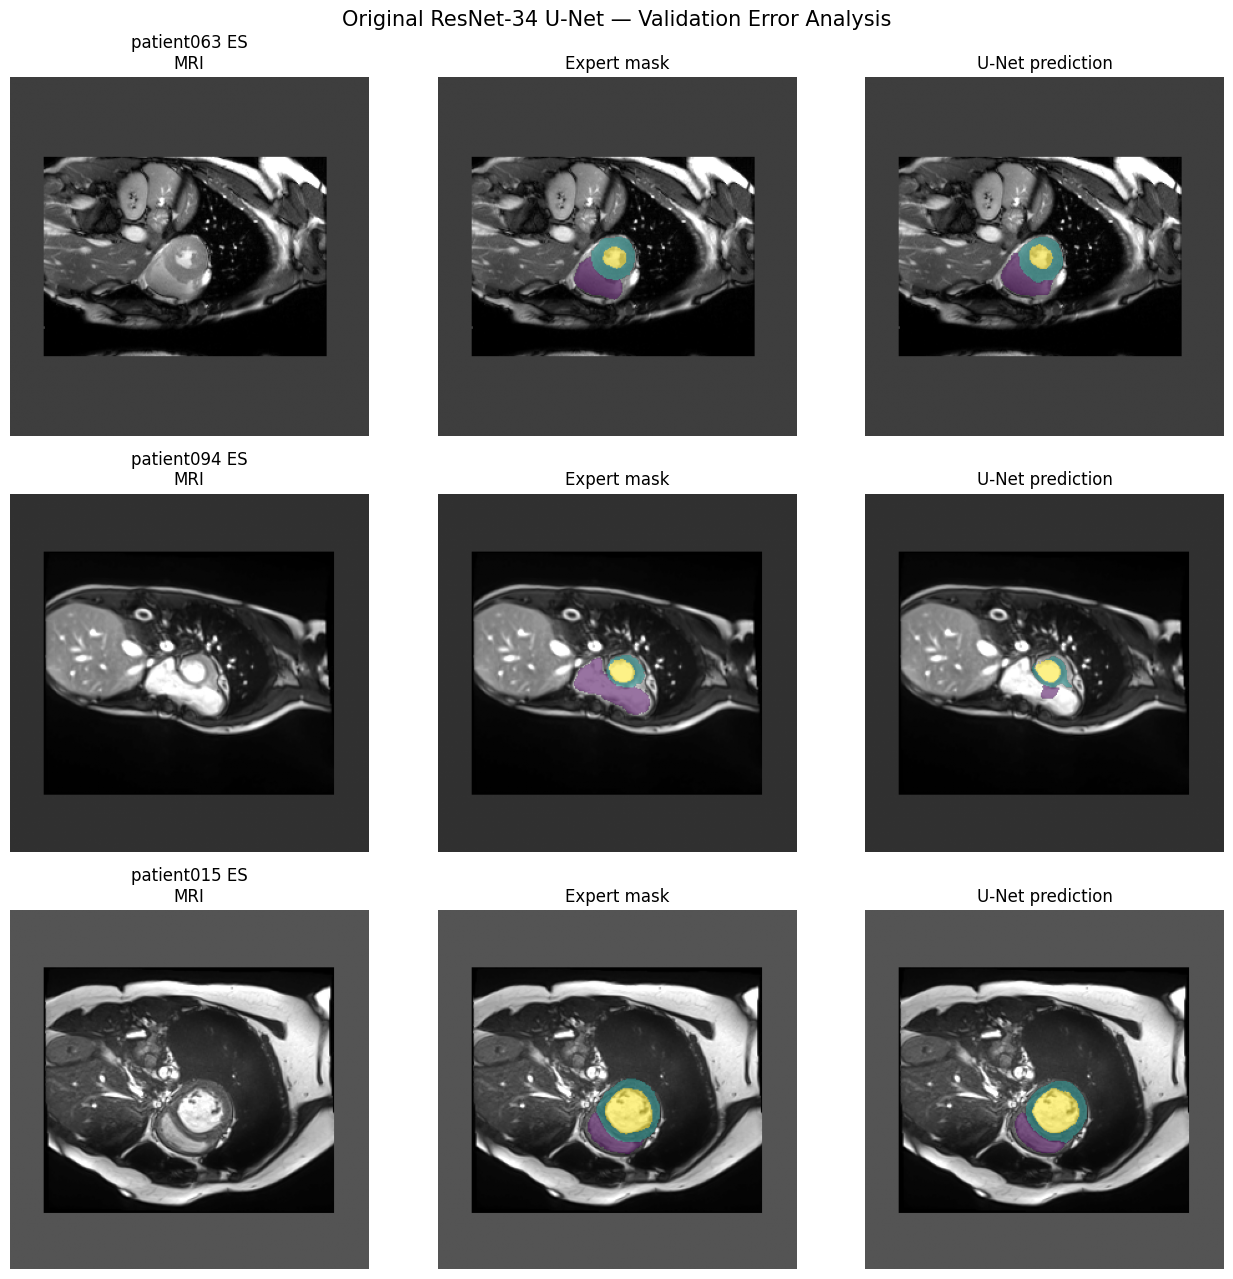

In [ ]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

# --------------------------------------------------
# 1. Load the saved original U-Net checkpoint
# --------------------------------------------------

checkpoint_path = (
    "/content/drive/MyDrive/ACDC dataset/"
    "ACDC_experiments/unet_resnet34_seed42/best_model.pth"
)

assert os.path.isfile(checkpoint_path), "U-Net checkpoint not found."
assert os.path.isdir(str(PROC_LOCAL)), "Processed data folder not found."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4
).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Original U-Net checkpoint loaded successfully.")
print("Device:", device)
print("Checkpoint epoch:", checkpoint.get("epoch", "Not recorded"))

# --------------------------------------------------
# 2. Select the three cases
# --------------------------------------------------

selected_cases = [
    ("patient063", "ES"),
    ("patient094", "ES"),
    ("patient015", "ES")
]

# --------------------------------------------------
# 3. Predict each volume
# --------------------------------------------------

fig, axes = plt.subplots(
    len(selected_cases), 3,
    figsize=(13, 13)
)

for row, (patient, phase) in enumerate(selected_cases):

    volume_path = PROC_LOCAL / patient / f"{phase}.npz"

    assert volume_path.is_file(), f"Missing volume: {volume_path}"

    with np.load(volume_path) as data:
        images = data["image"].astype(np.float32)
        masks = data["mask"].astype(np.int64)

    # Select the slice containing the most foreground pixels
    foreground_counts = np.count_nonzero(masks, axis=(0, 1))
    slice_idx = int(np.argmax(foreground_counts))

    # Predict the complete volume in batches
    predictions = []

    with torch.no_grad():
        for start in range(0, images.shape[2], 8):

            batch = images[:, :, start:start + 8]
            batch = np.transpose(batch, (2, 0, 1))

            batch_tensor = torch.from_numpy(
                np.ascontiguousarray(batch)
            ).unsqueeze(1).to(device)

            logits = model(batch_tensor)
            batch_predictions = logits.argmax(dim=1)

            predictions.append(
                batch_predictions.cpu().numpy()
            )

    predictions = np.concatenate(predictions, axis=0)
    predicted_mask = predictions[slice_idx]

    # Ground truth and prediction for the selected slice
    image_slice = images[:, :, slice_idx]
    expert_mask = masks[:, :, slice_idx]

    print(
        f"{patient} {phase} | "
        f"Volume shape: {images.shape} | "
        f"Selected slice: {slice_idx} | "
        f"Labels: {np.unique(expert_mask).tolist()} | "
        f"Predicted labels: {np.unique(predicted_mask).tolist()}"
    )

    # Display MRI, expert mask, and prediction
    lo, hi = np.percentile(image_slice, [1, 99])

    axes[row, 0].imshow(
        image_slice.T, cmap="gray",
        origin="lower", vmin=lo, vmax=hi
    )
    axes[row, 0].set_title(f"{patient} {phase}\nMRI")

    axes[row, 1].imshow(
        image_slice.T, cmap="gray",
        origin="lower", vmin=lo, vmax=hi
    )
    axes[row, 1].imshow(
        np.ma.masked_equal(expert_mask.T, 0),
        cmap="viridis", vmin=1, vmax=3,
        alpha=0.55, origin="lower"
    )
    axes[row, 1].set_title("Expert mask")

    axes[row, 2].imshow(
        image_slice.T, cmap="gray",
        origin="lower", vmin=lo, vmax=hi
    )
    axes[row, 2].imshow(
        np.ma.masked_equal(predicted_mask.T, 0),
        cmap="viridis", vmin=1, vmax=3,
        alpha=0.55, origin="lower"
    )
    axes[row, 2].set_title("U-Net prediction")

    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "Original ResNet-34 U-Net — Validation Error Analysis",
    fontsize=15
)
plt.tight_layout()
plt.show()

Dice per structure on just the slices shown above.

In [ ]:

import numpy as np
import pandas as pd
import torch

# --------------------------------------------------
# 1. Define cardiac structure labels
# --------------------------------------------------

class_names = {
    1: "RV",
    2: "Myocardium",
    3: "LV"
}

selected_cases = [
    ("patient063", "ES"),
    ("patient094", "ES"),
    ("patient015", "ES")
]

results = []

# --------------------------------------------------
# 2. Calculate Dice for each selected patient
# --------------------------------------------------

model.eval()

for patient, phase in selected_cases:

    volume_path = PROC_LOCAL / patient / f"{phase}.npz"

    with np.load(volume_path) as data:
        images = data["image"].astype(np.float32)
        masks = data["mask"].astype(np.int64)

    # Use the same slice selection as visual analysis
    foreground_counts = np.count_nonzero(
        masks, axis=(0, 1)
    )
    slice_idx = int(np.argmax(foreground_counts))

    # Predict the selected slice
    image_slice = images[:, :, slice_idx]

    input_tensor = torch.from_numpy(
        np.ascontiguousarray(image_slice)
    ).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        predicted_mask = logits.argmax(dim=1)[0].cpu().numpy()

    expert_mask = masks[:, :, slice_idx]

    # --------------------------------------------------
    # 3. Calculate Dice separately for each structure
    # --------------------------------------------------

    for label, structure in class_names.items():

        ground_truth = (expert_mask == label)
        prediction = (predicted_mask == label)

        intersection = np.logical_and(
            ground_truth, prediction
        ).sum()

        denominator = (
            ground_truth.sum() + prediction.sum()
        )

        dice = (
            2.0 * intersection / denominator
            if denominator > 0 else np.nan
        )

        results.append({
            "Patient": patient,
            "Phase": phase,
            "Slice": slice_idx,
            "Structure": structure,
            "Dice": dice
        })

# --------------------------------------------------
# 4. Display results
# --------------------------------------------------

dice_results = pd.DataFrame(results)

print("Per-class Dice scores:")
display(
    dice_results.pivot(
        index="Patient",
        columns="Structure",
        values="Dice"
    ).round(4)
)

print("\nDetailed results:")
display(dice_results.round(4))


Per-class Dice scores:


Structure,LV,Myocardium,RV
Patient,,,
patient015,0.9594,0.8714,0.9307
patient063,0.9190,0.9102,0.9174
patient094,0.9258,0.6882,0.1760



Detailed results:


,Patient,Phase,Slice,Structure,Dice
0,patient063,ES,2,RV,0.9174
1,patient063,ES,2,Myocardium,0.9102
2,patient063,ES,2,LV,0.9190
3,patient094,ES,1,RV,0.1760
4,patient094,ES,1,Myocardium,0.6882
5,patient094,ES,1,LV,0.9258
6,patient015,ES,2,RV,0.9307
7,patient015,ES,2,Myocardium,0.8714
8,patient015,ES,2,LV,0.9594


The ten validation volumes with the lowest RV Dice.

In [ ]:
# Same per-volume validation scores loaded in the cell above
validation_results = per_volume


# Sort all validation volumes by RV Dice score
rv_analysis = validation_results.sort_values(
    by="RV_Dice",
    ascending=True
)

print("10 volumes with the lowest RV Dice scores:")
display(
    rv_analysis[
        ["Patient", "Phase", "RV_Dice",
         "Myocardium_Dice", "LV_Dice", "Mean_Dice"]
    ].head(10).round(4)
)

# Count volumes with low RV Dice scores
print("\nRV performance analysis:")

print("RV Dice below 0.50:",
      (validation_results["RV_Dice"] < 0.50).sum())

print("RV Dice below 0.70:",
      (validation_results["RV_Dice"] < 0.70).sum())

print("Mean RV Dice:",
      round(validation_results["RV_Dice"].mean(), 4))


10 volumes with the lowest RV Dice scores:


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
25,patient063,ES,0.6763,0.8539,0.7648,0.7650
9,patient021,ES,0.7135,0.8936,0.8588,0.8220
21,patient049,ES,0.7338,0.8828,0.9561,0.8576
23,patient058,ES,0.7602,0.8650,0.9438,0.8564
35,patient094,ES,0.7607,0.7568,0.8209,0.7795
19,patient047,ES,0.7633,0.8252,0.9360,0.8415
17,patient044,ES,0.7663,0.8790,0.9438,0.8630
33,patient084,ES,0.7706,0.8447,0.8079,0.8077
11,patient022,ES,0.7918,0.8838,0.8585,0.8447
34,patient094,ED,0.8243,0.7355,0.9472,0.8357



RV performance analysis:
RV Dice below 0.50: 0
RV Dice below 0.70: 1
Mean RV Dice: 0.8733


Compare ED with ES, and count how many volumes fall below 0.80 Dice for each structure.

In [ ]:

# --------------------------------------------------
# Compare ED and ES validation performance
# --------------------------------------------------

phase_comparison = (
    validation_results
    .groupby("Phase")[
        ["RV_Dice", "Myocardium_Dice", "LV_Dice", "Mean_Dice"]
    ]
    .mean()
)

print("Mean Dice scores by cardiac phase:")
display(phase_comparison.round(4))

# --------------------------------------------------
# Count low-performing volumes per structure
# --------------------------------------------------

print("\nVolumes with Dice below 0.80:")

for structure, column in [
    ("RV", "RV_Dice"),
    ("Myocardium", "Myocardium_Dice"),
    ("LV", "LV_Dice")
]:
    count = (validation_results[column] < 0.80).sum()
    print(f"{structure}: {count} / {len(validation_results)}")

# --------------------------------------------------
# Compare the number of low-performing cases by phase
# --------------------------------------------------

print("\nLow-performing RV volumes by phase:")

rv_low = validation_results[
    validation_results["RV_Dice"] < 0.80
]

display(
    rv_low.groupby("Phase")
    .size()
    .rename("Number of volumes")
    .to_frame()
)


Mean Dice scores by cardiac phase:


,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
Phase,,,,
ED,0.9234,0.8612,0.9573,0.9139
ES,0.8232,0.8706,0.9069,0.8669



Volumes with Dice below 0.80:
RV: 9 / 40
Myocardium: 3 / 40
LV: 1 / 40

Low-performing RV volumes by phase:


,Number of volumes
Phase,
ES,9


Mean validation Dice was 0.9139 at ED and 0.8669 at ES. The RV showed the biggest drop, from 0.9234 to 0.8232, and all nine volumes with RV Dice below 0.80 were at ES. The 0.80 cut-off is only a way to count the weak cases, not a clinical threshold.

The ten weakest volumes for each structure.

In [ ]:
# Identify the 10 lowest-scoring validation volumes
columns = {
    "RV": "RV_Dice",
    "Myocardium": "Myocardium_Dice",
    "LV": "LV_Dice"
}

for structure, column in columns.items():
    print(f"\n10 lowest-performing {structure} volumes:")

    display(
        validation_results
        .nsmallest(10, column)[
            ["Patient", "Phase", "RV_Dice",
             "Myocardium_Dice", "LV_Dice", "Mean_Dice"]
        ]
        .round(4)
        .reset_index(drop=True)
    )


10 lowest-performing RV volumes:


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
0,patient063,ES,0.6763,0.8539,0.7648,0.7650
1,patient021,ES,0.7135,0.8936,0.8588,0.8220
2,patient049,ES,0.7338,0.8828,0.9561,0.8576
3,patient058,ES,0.7602,0.8650,0.9438,0.8564
4,patient094,ES,0.7607,0.7568,0.8209,0.7795
5,patient047,ES,0.7633,0.8252,0.9360,0.8415
6,patient044,ES,0.7663,0.8790,0.9438,0.8630
7,patient084,ES,0.7706,0.8447,0.8079,0.8077
8,patient022,ES,0.7918,0.8838,0.8585,0.8447
9,patient094,ED,0.8243,0.7355,0.9472,0.8357



10 lowest-performing Myocardium volumes:


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
0,patient094,ED,0.8243,0.7355,0.9472,0.8357
1,patient094,ES,0.7607,0.7568,0.8209,0.7795
2,patient084,ED,0.8636,0.7728,0.8949,0.8437
3,patient015,ES,0.8688,0.8142,0.9405,0.8745
4,patient047,ED,0.8982,0.8180,0.9456,0.8873
5,patient047,ES,0.7633,0.8252,0.9360,0.8415
6,patient063,ED,0.9139,0.8364,0.9456,0.8986
7,patient058,ED,0.9064,0.8402,0.9549,0.9005
8,patient084,ES,0.7706,0.8447,0.8079,0.8077
9,patient095,ED,0.9719,0.8476,0.9632,0.9276



10 lowest-performing LV volumes:


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
0,patient063,ES,0.6763,0.8539,0.7648,0.7650
1,patient084,ES,0.7706,0.8447,0.8079,0.8077
2,patient094,ES,0.7607,0.7568,0.8209,0.7795
3,patient022,ES,0.7918,0.8838,0.8585,0.8447
4,patient021,ES,0.7135,0.8936,0.8588,0.8220
5,patient032,ES,0.8280,0.9386,0.8854,0.8840
6,patient096,ES,0.9394,0.8865,0.8880,0.9046
7,patient084,ED,0.8636,0.7728,0.8949,0.8437
8,patient038,ES,0.8309,0.8827,0.9190,0.8776
9,patient095,ES,0.9311,0.8608,0.9191,0.9037


Dice for each slice of three difficult volumes, to see whether the errors are spread out or concentrated in a few slices.

In [ ]:
import numpy as np
import pandas as pd
import torch

cases_to_inspect = [
    ("patient063", "ES"),
    ("patient094", "ES"),
    ("patient094", "ED"),
]

slice_results = []

model.eval()

for patient, phase in cases_to_inspect:

    data = np.load(PROC_LOCAL / patient / f"{phase}.npz")

    images = data["image"].astype(np.float32)
    masks = data["mask"].astype(np.int64)

    num_slices = images.shape[2]

    # Convert (H, W, S) to (S, H, W)
    image_batch = torch.from_numpy(
        np.transpose(images, (2, 0, 1))
    ).unsqueeze(1).to(device)

    with torch.no_grad():
        predictions = []

        for start in range(0, num_slices, 8):
            batch = image_batch[start:start + 8]
            logits = model(batch)
            predictions.append(logits.argmax(dim=1).cpu().numpy())

    predicted_masks = np.concatenate(predictions, axis=0)

    # Calculate Dice separately for each slice and structure
    for slice_idx in range(num_slices):

        row = {
            "Patient": patient,
            "Phase": phase,
            "Slice": slice_idx
        }

        for label, structure in [
            (1, "RV"),
            (2, "Myocardium"),
            (3, "LV")
        ]:

            gt = masks[:, :, slice_idx] == label
            pred = predicted_masks[slice_idx] == label

            denominator = gt.sum() + pred.sum()

            dice = (
                2 * np.logical_and(gt, pred).sum() / denominator
                if denominator > 0 else np.nan
            )

            row[f"{structure}_Dice"] = dice

        slice_results.append(row)

slice_dice_df = pd.DataFrame(slice_results)

print("Per-slice Dice results:")
display(slice_dice_df.round(4))

print("\nLowest-scoring slice for each structure and volume:")

for (patient, phase), group in slice_dice_df.groupby(
    ["Patient", "Phase"]
):
    print(f"\n{patient} {phase}")

    for structure in ["RV", "Myocardium", "LV"]:
        column = f"{structure}_Dice"
        worst = group.loc[group[column].idxmin()]

        print(
            f"{structure}: Slice {int(worst['Slice'])}, "
            f"Dice = {worst[column]:.4f}"
        )

Per-slice Dice results:


,Patient,Phase,Slice,RV_Dice,Myocardium_Dice,LV_Dice
0,patient063,ES,0,0.0000,0.0000,0.0000
1,patient063,ES,1,0.0000,0.9075,0.9165
2,patient063,ES,2,0.9174,0.9102,0.9190
3,patient063,ES,3,0.9089,0.8954,0.9020
4,patient063,ES,4,0.7944,0.8710,0.9000
5,patient063,ES,5,0.6778,0.9176,0.8614
6,patient063,ES,6,NaN,0.8819,0.6786
7,patient063,ES,7,NaN,NaN,NaN
8,patient094,ES,0,0.0000,0.0000,0.0000
9,patient094,ES,1,0.1760,0.6882,0.9258



Lowest-scoring slice for each structure and volume:

patient063 ES
RV: Slice 0, Dice = 0.0000
Myocardium: Slice 0, Dice = 0.0000
LV: Slice 0, Dice = 0.0000

patient094 ED
RV: Slice 0, Dice = 0.0000
Myocardium: Slice 9, Dice = 0.2983
LV: Slice 9, Dice = 0.7946

patient094 ES
RV: Slice 0, Dice = 0.0000
Myocardium: Slice 0, Dice = 0.0000
LV: Slice 0, Dice = 0.0000


Pixel counts per slice for the expert mask and the prediction. If the prediction has pixels where the expert has none, it is a false positive; if it has far fewer, it is missing tissue.

In [ ]:
import numpy as np
import pandas as pd
import torch

cases_to_check = [
    ("patient063", "ES"),
    ("patient094", "ES"),
    ("patient094", "ED"),
]

count_results = []

model.eval()

for patient, phase in cases_to_check:

    data = np.load(PROC_LOCAL / patient / f"{phase}.npz")

    images = data["image"].astype(np.float32)
    masks = data["mask"].astype(np.int64)

    image_batch = torch.from_numpy(
        np.transpose(images, (2, 0, 1))
    ).unsqueeze(1).to(device)

    predictions = []

    with torch.no_grad():
        for start in range(0, len(image_batch), 8):
            logits = model(image_batch[start:start + 8])
            predictions.append(
                logits.argmax(dim=1).cpu().numpy()
            )

    predicted_masks = np.concatenate(predictions, axis=0)

    for slice_idx in range(masks.shape[2]):

        gt_slice = masks[:, :, slice_idx]
        pred_slice = predicted_masks[slice_idx]

        row = {
            "Patient": patient,
            "Phase": phase,
            "Slice": slice_idx,
        }

        for label, structure in [
            (1, "RV"),
            (2, "Myocardium"),
            (3, "LV")
        ]:
            row[f"{structure}_GT_pixels"] = int(
                np.sum(gt_slice == label)
            )
            row[f"{structure}_Pred_pixels"] = int(
                np.sum(pred_slice == label)
            )

        count_results.append(row)

count_df = pd.DataFrame(count_results)

display(count_df)

,Patient,Phase,Slice,RV_GT_pixels,RV_Pred_pixels,Myocardium_GT_pixels,Myocardium_Pred_pixels,LV_GT_pixels,LV_Pred_pixels
0,patient063,ES,0,0,49,0,349,0,378
1,patient063,ES,1,0,878,708,762,258,257
2,patient063,ES,2,710,694,718,730,252,279
3,patient063,ES,3,525,463,595,667,251,208
4,patient063,ES,4,296,200,537,579,206,174
5,patient063,ES,5,117,63,376,389,113,89
6,patient063,ES,6,0,0,334,301,36,20
7,patient063,ES,7,0,0,0,0,0,0
8,patient094,ES,0,439,0,301,0,443,0
9,patient094,ES,1,1200,118,324,263,298,268


The errors are concentrated in the first and last slices of the heart. Sometimes the model draws heart where the expert drew nothing, and sometimes it misses most of the RV (patient094 ES, slice 0 and 1). Patient063 ES stays difficult. Since the RV at end-systole was the most common failure, we tried giving the RV more weight in the loss.

### 7.3 RV-weighted U-Net

The second U-Net changes only one thing: in the Dice part of the loss, the RV counts twice as much as the myocardium and the LV (weights 2, 1, 1). The architecture, the 80/20 split, the learning rates and the 20 epochs stay the same. It starts again from the ImageNet encoder weights and saves to its own folder.

The RV-weighted loss. Cross-entropy is unchanged; only the Dice part is weighted.

In [ ]:

import torch
import torch.nn.functional as F

# RV-weighted multiclass Dice loss
# Label 1 = RV, Label 2 = Myocardium, Label 3 = LV
def multiclass_dice_loss(logits, targets, epsilon=1e-6):
    probabilities = torch.softmax(logits, dim=1)

    targets_one_hot = F.one_hot(
        targets,
        num_classes=4
    ).permute(0, 3, 1, 2).float()

    dimensions = (0, 2, 3)

    intersection = (probabilities * targets_one_hot).sum(dim=dimensions)

    denominator = (
        probabilities.sum(dim=dimensions)
        + targets_one_hot.sum(dim=dimensions)
    )

    dice = (2 * intersection + epsilon) / (denominator + epsilon)

    # Give RV twice the importance of the other foreground structures
    class_weights = torch.tensor(
        [2.0, 1.0, 1.0],
        device=logits.device
    )

    foreground_dice_loss = 1 - dice[1:]

    return (
        foreground_dice_loss * class_weights
    ).sum() / class_weights.sum()


# Combined loss
def segmentation_loss(logits, targets):
    ce_loss = F.cross_entropy(logits, targets)
    dice_loss = multiclass_dice_loss(logits, targets)

    return ce_loss + dice_loss


print("RV-weighted segmentation loss defined successfully.")


RV-weighted segmentation loss defined successfully.


A separate folder for this experiment, so the original run is never overwritten.

In [ ]:

import os

# Create a separate folder for the RV-weighted experiment
rv_experiment_dir = (
    "/content/drive/MyDrive/ACDC dataset/"
    "ACDC_experiments/unet_resnet34_seed42_rv_weighted"
)

os.makedirs(rv_experiment_dir, exist_ok=True)

# Separate checkpoint and history paths
best_checkpoint_path = os.path.join(
    rv_experiment_dir, "best_model.pth"
)

last_checkpoint_path = os.path.join(
    rv_experiment_dir, "last_checkpoint.pth"
)

history_path = os.path.join(
    rv_experiment_dir, "training_history.csv"
)

print("RV-weighted experiment folder created successfully.")
print("Experiment folder:", rv_experiment_dir)
print("Best checkpoint:", best_checkpoint_path)
print("Latest checkpoint:", last_checkpoint_path)
print("Training history:", history_path)


RV-weighted experiment folder created successfully.
Experiment folder: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted
Best checkpoint: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/best_model.pth
Latest checkpoint: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/last_checkpoint.pth
Training history: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/training_history.csv


A fresh U-Net with ImageNet encoder weights and the same optimizer settings as before.

In [ ]:

import torch
import segmentation_models_pytorch as smp

# Reproduce the original model initialization
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=4
)

model = model.to(device)

# Make all parameters trainable
for parameter in model.parameters():
    parameter.requires_grad = True

# Fresh optimizer with the original learning rates
optimizer = torch.optim.AdamW(
    [
        {"params": model.encoder.parameters(), "lr": 1e-4},
        {"params": model.decoder.parameters(), "lr": 1e-3},
        {"params": model.segmentation_head.parameters(), "lr": 1e-3}
    ],
    weight_decay=1e-4
)

EPOCHS = 20

print("Fresh RV-weighted model initialized successfully.")
print("Device:", device)
print("Architecture: U-Net + ResNet34")
print("Encoder weights: ImageNet pretrained")
print("Optimizer: AdamW")
print("Epochs:", EPOCHS)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Fresh RV-weighted model initialized successfully.
Device: cuda
Architecture: U-Net + ResNet34
Encoder weights: ImageNet pretrained
Optimizer: AdamW
Epochs: 20
Training batches: 188
Validation batches: 50


The same training and validation functions, now using the RV-weighted loss.

In [ ]:

def train_one_epoch(model, loader, optimizer, device):
    model.train()

    total_loss = 0.0
    total_slices = 0

    for images, masks, _, _, _ in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = segmentation_loss(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_slices += images.size(0)

    return total_loss / total_slices


def validate_one_epoch(model, loader, device):
    model.eval()

    total_loss = 0.0
    total_slices = 0

    with torch.no_grad():
        for images, masks, _, _, _ in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(images)
            loss = segmentation_loss(logits, masks)

            total_loss += loss.item() * images.size(0)
            total_slices += images.size(0)

    return total_loss / total_slices


print("Training and validation functions defined successfully.")


Training and validation functions defined successfully.


Train for 20 epochs and keep the checkpoint with the lowest validation loss (epoch 17). The two runs use different losses, so their loss values cannot be compared with each other.

In [ ]:
from pathlib import Path
import torch
if Path(best_checkpoint_path).is_file():
    checkpoint = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    display(pd.read_csv(history_path).round(4))
    print('Selected epoch:', checkpoint['epoch'])
    print('Best validation loss:', checkpoint['best_val_loss'])
    print('Checkpoint:', best_checkpoint_path)
else:

    import os
    import pandas as pd
    import time
    import torch

    # Verify that we are saving to the NEW experiment folder
    assert "rv_weighted" in rv_experiment_dir

    os.makedirs(rv_experiment_dir, exist_ok=True)

    assert not os.path.exists(best_checkpoint_path), (
        "A best checkpoint already exists. Check before overwriting."
    )

    # Use the device on which the model currently resides
    device = next(model.parameters()).device

    history = []
    best_val_loss = float("inf")

    print("Starting RV-weighted training...")
    print("Device:", device)
    print("Training slices:", len(train_ds))
    print("Validation slices:", len(val_ds))
    print("Epochs:", EPOCHS)
    print("Experiment folder:", rv_experiment_dir)

    start_time = time.time()

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model, train_loader, optimizer, device
        )

        val_loss = validate_one_epoch(
            model, val_loader, device
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "history": history
            }, best_checkpoint_path)

            best_message = " | Best model saved"
        else:
            best_message = ""

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": history
        }, last_checkpoint_path)

        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
            f"{best_message}"
        )

    elapsed_time = (time.time() - start_time) / 60

    print("\nRV-weighted training completed!")
    print("Best validation loss:", round(best_val_loss, 4))
    print("Time elapsed:", round(elapsed_time, 2), "minutes")
    print("Best checkpoint:", best_checkpoint_path)
    print("Training history:", history_path)


Starting RV-weighted training...
Device: cuda:0
Training slices: 1504
Validation slices: 398
Epochs: 20
Experiment folder: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted
Epoch 01/20 | Train Loss: 0.7036 | Validation Loss: 0.2314 | Best model saved
Epoch 02/20 | Train Loss: 0.1698 | Validation Loss: 0.1935 | Best model saved
Epoch 03/20 | Train Loss: 0.1305 | Validation Loss: 0.1633 | Best model saved
Epoch 04/20 | Train Loss: 0.1107 | Validation Loss: 0.1531 | Best model saved
Epoch 05/20 | Train Loss: 0.0958 | Validation Loss: 0.1457 | Best model saved
Epoch 06/20 | Train Loss: 0.0973 | Validation Loss: 0.1447 | Best model saved
Epoch 07/20 | Train Loss: 0.0948 | Validation Loss: 0.1541
Epoch 08/20 | Train Loss: 0.0894 | Validation Loss: 0.1383 | Best model saved
Epoch 09/20 | Train Loss: 0.0806 | Validation Loss: 0.1284 | Best model saved
Epoch 10/20 | Train Loss: 0.0758 | Validation Loss: 0.1441
Epoch 11/20 | Train Loss: 0.0749 | Validation Los

Check that the RV-weighted checkpoint exists and that validation has all 40 patient-phase volumes.

In [ ]:
from pathlib import Path
import torch

new_model_path = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/best_model.pth"
)

print("Best checkpoint exists:", new_model_path.is_file())

checkpoint = torch.load(
    new_model_path,
    map_location=device,
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

print("\nValidation patient-phase pairs:", len(set(
    (pid, phase) for pid, phase, _ in val_ds.items
)))

Best checkpoint exists: True

Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'history']

Validation patient-phase pairs: 40


Load the selected RV-weighted checkpoint.

In [ ]:
# Load the best RV-weighted checkpoint
checkpoint = torch.load(
    new_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Best RV-weighted model loaded successfully!")
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Model device:", next(model.parameters()).device)

Best RV-weighted model loaded successfully!
Best checkpoint epoch: 17
Best validation loss: 0.12404691817323167
Model device: cuda:0


Predict every validation slice, rebuild the full volumes, and compute Dice for each structure.

In [ ]:
weighted_scores_path = WEIGHTED_CNN_DIR / 'validation_dice_per_volume.csv'
if weighted_scores_path.is_file():
    new_per_volume = pd.read_csv(weighted_scores_path)
    assert len(new_per_volume) == 40
    display(new_per_volume.head())
else:
    import numpy as np
    import pandas as pd
    import torch
    from pathlib import Path

    def calculate_dice(prediction, target, class_id, epsilon=1e-6):
        pred_mask = prediction == class_id
        true_mask = target == class_id

        intersection = np.logical_and(pred_mask, true_mask).sum()
        denominator = pred_mask.sum() + true_mask.sum()

        if denominator == 0:
            return np.nan

        return (2.0 * intersection + epsilon) / (denominator + epsilon)


    # Group validation slices by patient and phase
    volume_groups = {}

    for pid, phase, slice_idx in val_ds.items:
        volume_groups.setdefault((pid, phase), []).append(
            (slice_idx, pid, phase)
        )

    new_results = []

    model.eval()

    with torch.no_grad():
        for (pid, phase), slices in sorted(volume_groups.items()):

            slices = sorted(slices, key=lambda x: x[0])

            predictions = []
            ground_truths = []

            for slice_idx, _, _ in slices:
                image, mask, _, _, _ = val_ds[
                    val_ds.items.index((pid, phase, slice_idx))
                ]

                image = image.unsqueeze(0).to(device)

                logits = model(image)
                prediction = torch.argmax(logits, dim=1)

                predictions.append(prediction.squeeze(0).cpu().numpy())
                ground_truths.append(mask.numpy())

            prediction_volume = np.stack(predictions, axis=-1)
            target_volume = np.stack(ground_truths, axis=-1)

            rv_dice = calculate_dice(prediction_volume, target_volume, 1)
            myo_dice = calculate_dice(prediction_volume, target_volume, 2)
            lv_dice = calculate_dice(prediction_volume, target_volume, 3)

            mean_dice = np.nanmean([rv_dice, myo_dice, lv_dice])

            new_results.append({
                "Patient": pid,
                "Phase": phase,
                "RV_Dice": rv_dice,
                "Myocardium_Dice": myo_dice,
                "LV_Dice": lv_dice,
                "Mean_Dice": mean_dice
            })

    new_per_volume = pd.DataFrame(new_results)

    print("Evaluation completed!")
    print("Number of validation volumes:", len(new_per_volume))
    display(new_per_volume.head())

Evaluation completed!
Number of validation volumes: 40


,Patient,Phase,RV_Dice,Myocardium_Dice,LV_Dice,Mean_Dice
0,patient007,ED,0.957769,0.832018,0.961698,0.917162
1,patient007,ES,0.885879,0.842047,0.954583,0.894170
2,patient008,ED,0.951037,0.882341,0.969128,0.934169
3,patient008,ES,0.884351,0.892495,0.961209,0.912685
4,patient011,ED,0.930967,0.885468,0.970638,0.929024


Compare the two U-Nets by structure and by phase, and save the comparison tables.

In [ ]:
import pandas as pd
from pathlib import Path

# Calculate mean Dice for each structure
structures = ["RV_Dice", "Myocardium_Dice", "LV_Dice"]

baseline_means = per_volume[structures].mean()
new_means = new_per_volume[structures].mean()

comparison = pd.DataFrame({
    "Structure": ["RV", "Myocardium", "LV"],
    "Baseline_Dice": baseline_means.values,
    "RV_Weighted_Dice": new_means.values,
    "Difference": (new_means - baseline_means).values
})

# Add overall mean
comparison.loc[len(comparison)] = {
    "Structure": "Overall mean",
    "Baseline_Dice": baseline_means.mean(),
    "RV_Weighted_Dice": new_means.mean(),
    "Difference": new_means.mean() - baseline_means.mean()
}

print("BASELINE VS RV-WEIGHTED MODEL")
display(comparison.round(6))

# Compare performance by cardiac phase
phase_comparison = []

for phase in ["ED", "ES"]:
    baseline_phase = per_volume[per_volume["Phase"] == phase]
    new_phase = new_per_volume[new_per_volume["Phase"] == phase]

    for structure in structures:
        phase_comparison.append({
            "Phase": phase,
            "Structure": structure.replace("_Dice", ""),
            "Baseline_Dice": baseline_phase[structure].mean(),
            "RV_Weighted_Dice": new_phase[structure].mean(),
            "Difference": (
                new_phase[structure].mean()
                - baseline_phase[structure].mean()
            )
        })

phase_comparison = pd.DataFrame(phase_comparison)

print("\nCOMPARISON BY CARDIAC PHASE")
display(phase_comparison.round(6))

# Save new results separately from the original baseline
results_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted"
)
results_dir.mkdir(parents=True, exist_ok=True)

new_per_volume.to_csv(
    results_dir / "validation_dice_per_volume.csv",
    index=False
)

comparison.to_csv(
    results_dir / "baseline_vs_rv_weighted_comparison.csv",
    index=False
)

phase_comparison.to_csv(
    results_dir / "phase_comparison.csv",
    index=False
)

print("\nAll comparison results saved successfully!")

BASELINE VS RV-WEIGHTED MODEL


,Structure,Baseline_Dice,RV_Weighted_Dice,Difference
0,RV,0.873301,0.881068,0.007767
1,Myocardium,0.865888,0.864591,-0.001297
2,LV,0.932113,0.931490,-0.000623
3,Overall mean,0.890434,0.892383,0.001949



COMPARISON BY CARDIAC PHASE


,Phase,Structure,Baseline_Dice,RV_Weighted_Dice,Difference
0,ED,RV,0.923370,0.926343,0.002973
1,ED,Myocardium,0.861167,0.860415,-0.000752
2,ED,LV,0.957305,0.957976,0.000671
3,ES,RV,0.823233,0.835793,0.012560
4,ES,Myocardium,0.870609,0.868766,-0.001843
5,ES,LV,0.906921,0.905005,-0.001916



All comparison results saved successfully!


How many volumes still have RV Dice below 0.80, and which ones.

In [ ]:
# Compare low-performing RV volumes
threshold = 0.80

baseline_low = per_volume[
    per_volume["RV_Dice"] < threshold
]

new_low = new_per_volume[
    new_per_volume["RV_Dice"] < threshold
]

print("RV DICE BELOW 0.80")
print("Baseline:", len(baseline_low), "/ 40")
print("RV-weighted:", len(new_low), "/ 40")

print("\nBASELINE LOW-PERFORMING CASES")
display(
    baseline_low[["Patient", "Phase", "RV_Dice"]]
    .sort_values("RV_Dice")
)

print("\nNEW MODEL LOW-PERFORMING CASES")
display(
    new_low[["Patient", "Phase", "RV_Dice"]]
    .sort_values("RV_Dice")
)

print("\nRV-WEIGHTED MODEL: LOW-PERFORMING ES CASES")
display(
    new_low[new_low["Phase"] == "ES"][
        ["Patient", "Phase", "RV_Dice"]
    ]
)

RV DICE BELOW 0.80
Baseline: 9 / 40
RV-weighted: 6 / 40

BASELINE LOW-PERFORMING CASES


,Patient,Phase,RV_Dice
25,patient063,ES,0.676345
9,patient021,ES,0.713471
21,patient049,ES,0.733799
23,patient058,ES,0.760248
35,patient094,ES,0.760667
19,patient047,ES,0.763317
17,patient044,ES,0.766296
33,patient084,ES,0.770587
11,patient022,ES,0.791848



NEW MODEL LOW-PERFORMING CASES


,Patient,Phase,RV_Dice
25,patient063,ES,0.675676
9,patient021,ES,0.731886
19,patient047,ES,0.741894
21,patient049,ES,0.763524
35,patient094,ES,0.785558
17,patient044,ES,0.789809



RV-WEIGHTED MODEL: LOW-PERFORMING ES CASES


,Patient,Phase,RV_Dice
9,patient021,ES,0.731886
17,patient044,ES,0.789809
19,patient047,ES,0.741894
21,patient049,ES,0.763524
25,patient063,ES,0.675676
35,patient094,ES,0.785558


Save the settings and the main numbers of this experiment.

In [ ]:
from pathlib import Path
import json

results_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted"
)

experiment_summary = {
    "experiment": "RV-weighted U-Net",
    "architecture": "U-Net with ResNet34 encoder",
    "seed": 42,
    "epochs_trained": 20,
    "best_checkpoint_epoch": 17,
    "loss": "Cross Entropy + RV-weighted multiclass Dice",
    "dice_class_weights": {
        "RV": 2.0,
        "Myocardium": 1.0,
        "LV": 1.0
    },
    "validation_volumes": 40,
    "baseline_mean_dice": {
        "RV": 0.873301,
        "Myocardium": 0.865888,
        "LV": 0.932113,
        "Overall": 0.890434
    },
    "rv_weighted_mean_dice": {
        "RV": 0.881068,
        "Myocardium": 0.864591,
        "LV": 0.931490,
        "Overall": 0.892383
    },
    "rv_cases_below_0.80": {
        "baseline": 9,
        "rv_weighted": 6
    }
}

summary_path = results_dir / "experiment_summary.json"

with open(summary_path, "w") as f:
    json.dump(experiment_summary, f, indent=4)

print("Experiment summary saved:")
print(summary_path)

Experiment summary saved:
/content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/experiment_summary.json


The RV-weighted run's loss curves, with the selected epoch marked.

Selected checkpoint: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_seed42_rv_weighted/best_model.pth


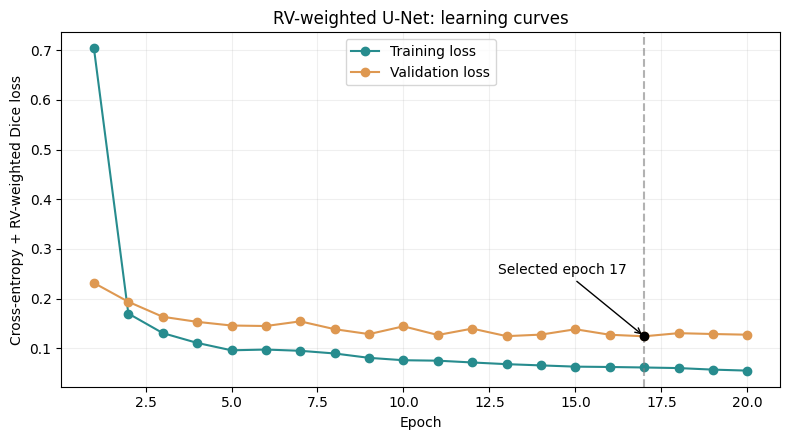

In [ ]:
weighted_history = pd.read_csv(WEIGHTED_CNN_DIR / 'training_history.csv').sort_values('epoch')
selected = weighted_history.loc[weighted_history['val_loss'].idxmin()]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(weighted_history['epoch'], weighted_history['train_loss'], 'o-', color='#278C8E', label='Training loss')
ax.plot(weighted_history['epoch'], weighted_history['val_loss'], 'o-', color='#DE9851', label='Validation loss')
ax.axvline(selected['epoch'], color='grey', ls='--', alpha=.6)
ax.scatter(selected['epoch'], selected['val_loss'], color='black', zorder=5)
ax.annotate(f"Selected epoch {int(selected['epoch'])}", (selected['epoch'], selected['val_loss']),
            xytext=(-105, 45), textcoords='offset points', arrowprops={'arrowstyle': '->'})
ax.set(title='RV-weighted U-Net: learning curves', xlabel='Epoch', ylabel='Cross-entropy + RV-weighted Dice loss')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()
print('Selected checkpoint:', WEIGHTED_CNN_DIR / 'best_model.pth')

The selected RV-weighted checkpoint is epoch 17. RV Dice increased from 0.873301 to 0.881068, while mean foreground Dice increased from 0.890434 to 0.892383. The largest gain was in ES RV Dice (+0.012560). Myocardium and LV Dice decreased slightly.

RV volumes below 0.80 decreased from 9/40 to 6/40, all at ES. The fix did not help every case: patient047 ES worsened and patient063 ES remained difficult. This is a modest improvement in one validation experiment, without evidence from repeated seeds or a final test. The two training losses use different class weights and should not be compared as if they were the same objective.

## <span style="color:#247C87">8. Validation results and cost</span>

### 8.1 Validation comparisons

Validation Dice, precision and recall for the two classical models, then all eight forest settings with their training times.

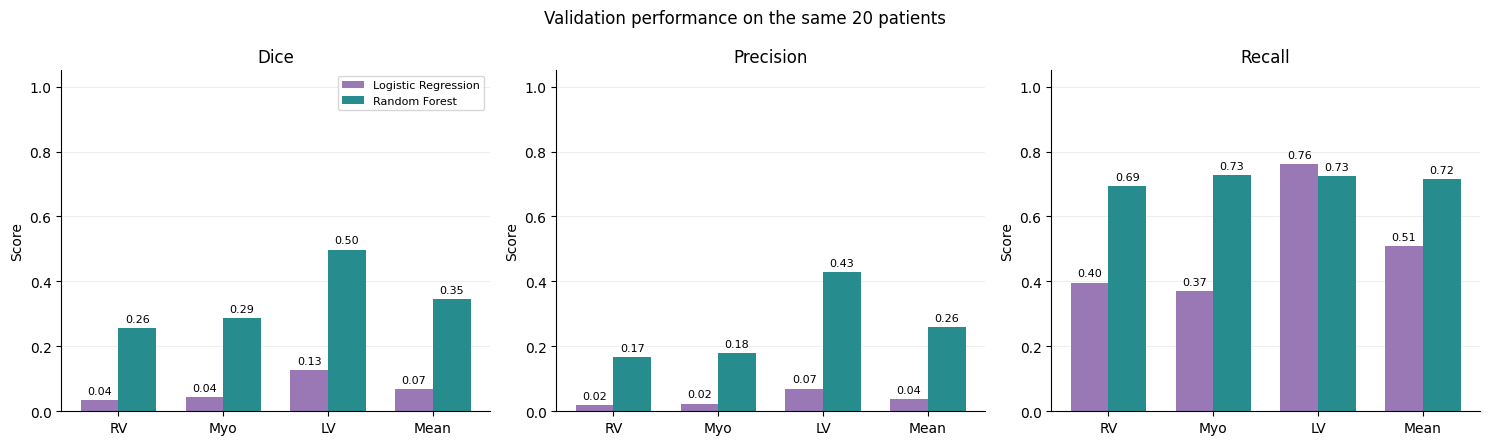

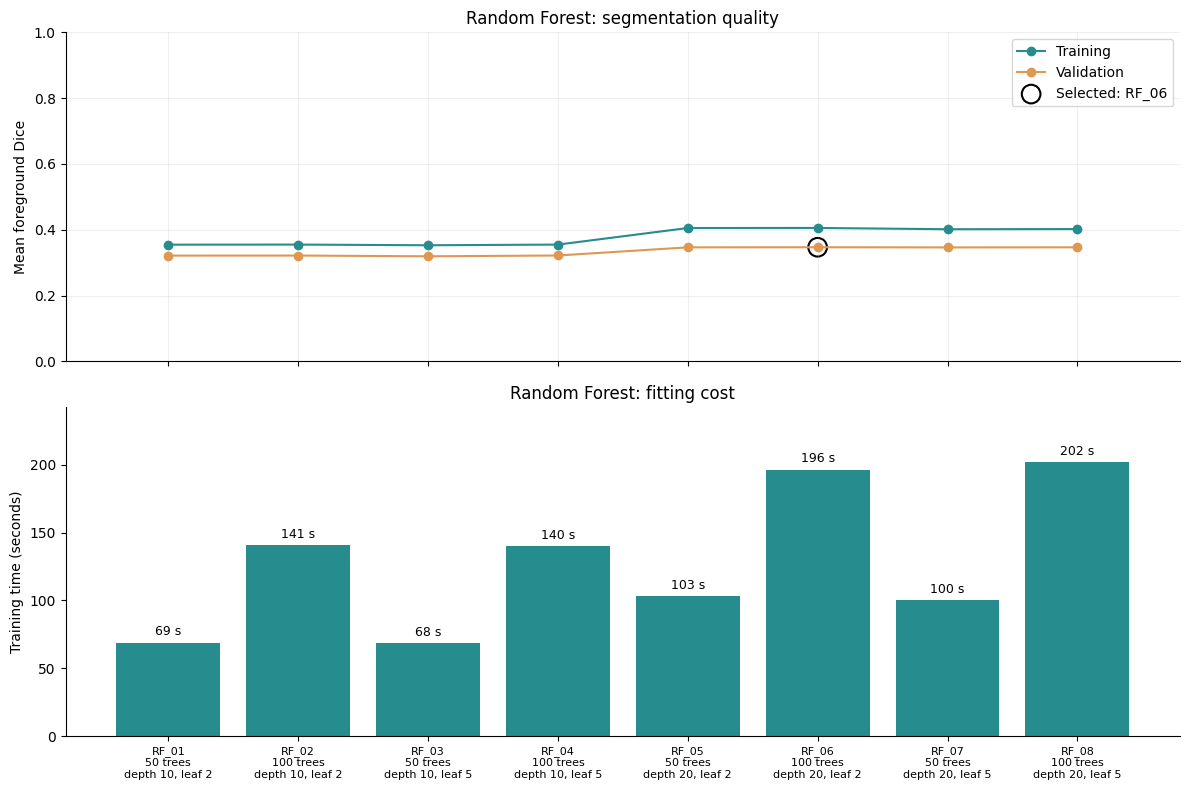

,Model,Mean Dice,Mean precision,Mean recall
0,Logistic Regression,0.0688,0.0376,0.5094
1,Random Forest (RF_06),0.3468,0.2582,0.7152


Figures saved to: /content/drive/MyDrive/ACDC dataset/experiments/random_forest_20261106_151100_091562/figures


In [ ]:
experiment_dir = CLASSICAL_DIR
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = experiment_dir / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white"
})

COLORS = {
    "lr": "#9A78B5",
    "rf": "#278C8E",
    "train": "#278C8E",
    "val": "#DE9851"
}

# Read the recorded results.
lr_scores = pd.read_csv(
    experiment_dir / "lr_validation_summary.csv", index_col=0
)
rf_runs = pd.read_csv(
    experiment_dir / "rf_completed_results.csv"
)
ranked = rf_runs.sort_values(
    ["val_mean_dice", "n_estimators",
     "max_depth", "min_samples_leaf"],
    ascending=[False, True, True, False]
)
selected_run = ranked.iloc[0]["run_id"]

rf_scores = pd.read_csv(
    experiment_dir / f"{selected_run}_val_summary.csv",
    index_col=0
)

# 1. Validation metrics for the classical models.
structures = ["RV", "Myocardium", "LV", "Mean foreground"]
x = np.arange(len(structures))
width = 0.36

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, metric in zip(axes, ["dice", "precision", "recall"]):
    for offset, scores, label, color in [
        (-width / 2, lr_scores, "Logistic Regression", COLORS["lr"]),
        (width / 2, rf_scores, "Random Forest", COLORS["rf"])
    ]:
        bars = ax.bar(
            x + offset,
            scores.loc[structures, metric],
            width, label=label, color=color
        )
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=3)

    ax.set_xticks(x, ["RV", "Myo", "LV", "Mean"])
    ax.set_ylim(0, 1.05)
    ax.set_title(metric.capitalize())
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].legend(fontsize=8)
fig.suptitle("Validation performance on the same 20 patients")
fig.tight_layout()
fig.savefig(
    FIG_DIR / "01_classical_validation.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# 2. Random Forest tuning and computational cost.
runs = rf_runs.sort_values("run_id").reset_index(drop=True)
x = np.arange(len(runs))

labels = [
    f"{r.run_id}\n{r.n_estimators} trees\n"
    f"depth {r.max_depth}, leaf {r.min_samples_leaf}"
    for r in runs.itertuples()
]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    x, runs["train_mean_dice"], "o-",
    color=COLORS["train"], label="Training"
)
axes[0].plot(
    x, runs["val_mean_dice"], "o-",
    color=COLORS["val"], label="Validation"
)

best_position = runs.index[runs["run_id"] == selected_run][0]
axes[0].scatter(
    best_position,
    runs.loc[best_position, "val_mean_dice"],
    s=180, facecolors="none", edgecolors="black",
    linewidths=1.5, label=f"Selected: {selected_run}"
)

axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean foreground Dice")
axes[0].set_title("Random Forest: segmentation quality")
axes[0].legend()
axes[0].grid(alpha=0.2)

bars = axes[1].bar(
    x, runs["fit_seconds"], color=COLORS["rf"]
)
axes[1].bar_label(bars, fmt="%.0f s", padding=3, fontsize=9)
axes[1].set_ylabel("Training time (seconds)")
axes[1].set_title("Random Forest: fitting cost")
axes[1].set_xticks(x, labels, fontsize=8)
axes[1].margins(y=0.2)

fig.tight_layout()
fig.savefig(
    FIG_DIR / "02_random_forest_tuning.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Save a compact table alongside the figures.
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", f"Random Forest ({selected_run})"],
    "Mean Dice": [
        lr_scores.loc["Mean foreground", "dice"],
        rf_scores.loc["Mean foreground", "dice"]
    ],
    "Mean precision": [
        lr_scores.loc["Mean foreground", "precision"],
        rf_scores.loc["Mean foreground", "precision"]
    ],
    "Mean recall": [
        lr_scores.loc["Mean foreground", "recall"],
        rf_scores.loc["Mean foreground", "recall"]
    ]
})
comparison.to_csv(FIG_DIR / "classical_comparison.csv", index=False)
display(comparison.round(4))

print("Figures saved to:", FIG_DIR)

The two U-Nets next to the classical models, plus RV Dice at ED and ES for both U-Nets.

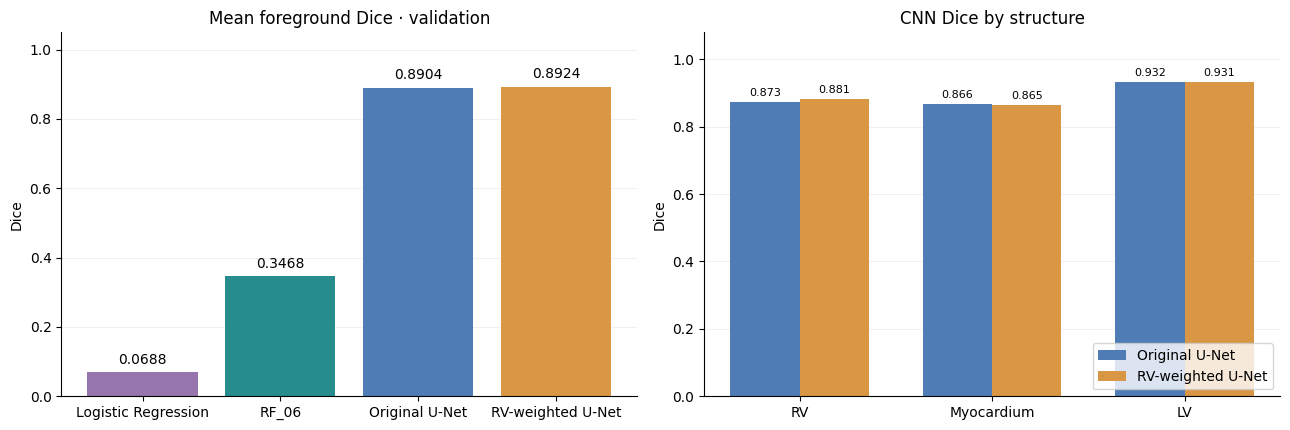

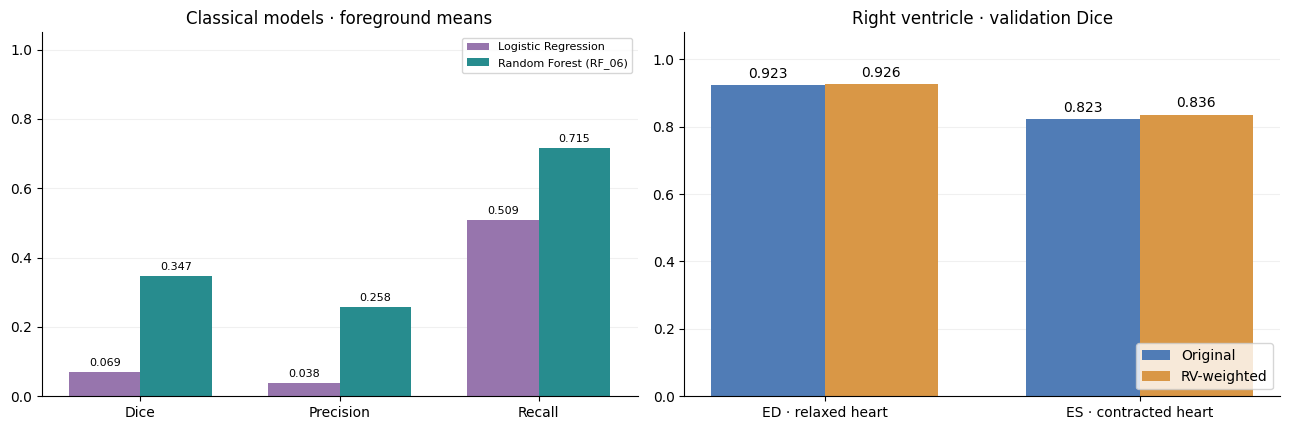

In [ ]:
classical_table = pd.read_csv(CLASSICAL_DIR / 'figures/classical_comparison.csv')
cnn_comparison = pd.read_csv(WEIGHTED_CNN_DIR / 'baseline_vs_rv_weighted_comparison.csv')
cnn_phase = pd.read_csv(WEIGHTED_CNN_DIR / 'phase_comparison.csv')
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})
colors = ['#9775AD', '#278C8E', '#507CB6', '#D99746']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
cnn_rows = cnn_comparison.set_index('Structure')
mean_key = next(k for k in cnn_rows.index if 'mean' in str(k).lower())
labels = ['Logistic Regression', 'RF_06', 'Original U-Net', 'RV-weighted U-Net']
values = list(classical_table['Mean Dice']) + [cnn_rows.loc[mean_key, 'Baseline_Dice'], cnn_rows.loc[mean_key, 'RV_Weighted_Dice']]
bars = axes[0].bar(labels, values, color=colors)
axes[0].bar_label(bars, fmt='%.4f', padding=4)
axes[0].set(title='Mean foreground Dice · validation', ylim=(0, 1.05), ylabel='Dice')
structs = ['RV', 'Myocardium', 'LV']
x = np.arange(3)
for offset, column, label, color in [(-.18, 'Baseline_Dice', 'Original U-Net', colors[2]), (.18, 'RV_Weighted_Dice', 'RV-weighted U-Net', colors[3])]:
    bars = axes[1].bar(x + offset, cnn_rows.loc[structs, column], .36, label=label, color=color)
    axes[1].bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
axes[1].set_xticks(x, structs)
axes[1].set(title='CNN Dice by structure', ylim=(0, 1.08), ylabel='Dice')
axes[1].legend(loc='lower right')
for ax in axes: ax.grid(axis='y', alpha=.18); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
metric_cols = ['Mean Dice', 'Mean precision', 'Mean recall']
x = np.arange(3)
for i, row in classical_table.reset_index(drop=True).iterrows():
    bars = axes[0].bar(x + (i-.5)*.36, [row[k] for k in metric_cols], .36,
                       label=row['Model'], color=colors[i])
    axes[0].bar_label(bars, fmt='%.3f', fontsize=8, padding=3)
axes[0].set_xticks(x, ['Dice', 'Precision', 'Recall'])
axes[0].set(title='Classical models · foreground means', ylim=(0, 1.05))
axes[0].legend(fontsize=8)
phase_rv = cnn_phase[cnn_phase['Structure'].eq('RV')].set_index('Phase').loc[['ED','ES']]
x = np.arange(2)
for offset, column, label, color in [(-.18,'Baseline_Dice','Original',colors[2]),(.18,'RV_Weighted_Dice','RV-weighted',colors[3])]:
    bars=axes[1].bar(x+offset,phase_rv[column],.36,label=label,color=color)
    axes[1].bar_label(bars,fmt='%.3f',padding=3)
axes[1].set_xticks(x,['ED · relaxed heart','ES · contracted heart'])
axes[1].set(title='Right ventricle · validation Dice',ylim=(0,1.08))
axes[1].legend(loc='lower right')
for ax in axes: ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### 8.2 Features and computational cost

All saved classical results and fitting times in one place.

In [ ]:
import pandas as pd
import json
from pathlib import Path

rf_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/random_forest_20261106_151100_091562"
)

# Inspect aggregate comparison files
files_to_read = [
    "classical_comparison.csv",

    "rf_completed_results.csv",
    "rf_ranked_results.csv",
    "RF_03_val_summary.csv",
    "RF_04_val_summary.csv",
    "RF_05_val_summary.csv",
    "RF_06_val_summary.csv",
    "RF_07_val_summary.csv",
    "RF_08_val_summary.csv",
    "lr_validation_summary.csv",
    "lr_training_log.csv"
]

for filename in files_to_read:
    path = (rf_dir / "figures" / filename) if filename == "classical_comparison.csv" else (rf_dir / filename)

    if path.exists():
        print(f"\n{'='*60}")
        print(filename)
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df.head(10))
    else:
        print(f"\nNOT FOUND: {filename}")

# Inspect configuration
config_path = rf_dir / "baseline_config.json"

if config_path.exists():
    print("\nEXPERIMENT CONFIGURATION")
    with open(config_path) as f:
        print(json.dumps(json.load(f), indent=4))

# Inspect timing
timing_path = rf_dir / "lr_validation_timing.json"

if timing_path.exists():
    print("\nLOGISTIC REGRESSION TIMING")
    with open(timing_path) as f:
        print(json.dumps(json.load(f), indent=4))


rf_completed_results.csv
Shape: (8, 33)


,run_id,max_depth,min_samples_leaf,n_estimators,fit_seconds,train_dice_RV,train_precision_RV,train_recall_RV,train_dice_Myocardium,train_precision_Myocardium,...,val_precision_Myocardium,val_recall_Myocardium,val_dice_LV,val_precision_LV,val_recall_LV,val_mean_dice,val_mean_precision,val_mean_recall,val_predict_seconds,val_evaluation_seconds
0,RF_01,10,2,50,68.934212,0.268993,0.170526,0.789782,0.280403,0.171193,...,0.149911,0.745970,0.474850,0.398521,0.730946,0.321430,0.234599,0.716360,62.514072,66.043198
1,RF_02,10,2,100,141.122817,0.269268,0.170607,0.791342,0.280728,0.171436,...,0.150346,0.745801,0.474361,0.398320,0.729706,0.321558,0.234732,0.716419,117.132493,120.494291
2,RF_03,10,5,50,68.439841,0.266283,0.168381,0.791411,0.277950,0.169453,...,0.148310,0.741456,0.473187,0.397187,0.728458,0.319249,0.232907,0.714419,60.628283,64.047777
3,RF_04,10,5,100,139.946809,0.270641,0.171762,0.790330,0.279739,0.170560,...,0.149293,0.747292,0.474551,0.399188,0.728053,0.321731,0.235084,0.716967,118.123221,121.545742
4,RF_05,20,2,50,103.045439,0.302830,0.194538,0.835754,0.342208,0.218135,...,0.180035,0.726240,0.497851,0.428146,0.725182,0.346444,0.258006,0.713915,82.472028,85.943580
5,RF_06,20,2,100,196.444451,0.303276,0.194824,0.837058,0.342309,0.218144,...,0.180228,0.728056,0.497985,0.428310,0.725137,0.346771,0.258218,0.715151,158.915407,162.416397
6,RF_07,20,5,50,100.054627,0.299694,0.192284,0.832090,0.338013,0.214970,...,0.178718,0.729048,0.499324,0.429794,0.727204,0.346246,0.257896,0.716307,79.404981,82.845542
7,RF_08,20,5,100,202.061046,0.299975,0.192448,0.833126,0.338744,0.215526,...,0.179225,0.729756,0.499352,0.429764,0.727290,0.346553,0.258090,0.716767,155.810557,159.259682



rf_ranked_results.csv
Shape: (8, 33)


,run_id,max_depth,min_samples_leaf,n_estimators,fit_seconds,train_dice_RV,train_precision_RV,train_recall_RV,train_dice_Myocardium,train_precision_Myocardium,...,val_precision_Myocardium,val_recall_Myocardium,val_dice_LV,val_precision_LV,val_recall_LV,val_mean_dice,val_mean_precision,val_mean_recall,val_predict_seconds,val_evaluation_seconds
0,RF_06,20,2,100,196.444451,0.303276,0.194824,0.837058,0.342309,0.218144,...,0.180228,0.728056,0.497985,0.428310,0.725137,0.346771,0.258218,0.715151,158.915407,162.416397
1,RF_08,20,5,100,202.061046,0.299975,0.192448,0.833126,0.338744,0.215526,...,0.179225,0.729756,0.499352,0.429764,0.727290,0.346553,0.258090,0.716767,155.810557,159.259682
2,RF_05,20,2,50,103.045439,0.302830,0.194538,0.835754,0.342208,0.218135,...,0.180035,0.726240,0.497851,0.428146,0.725182,0.346444,0.258006,0.713915,82.472028,85.943580
3,RF_07,20,5,50,100.054627,0.299694,0.192284,0.832090,0.338013,0.214970,...,0.178718,0.729048,0.499324,0.429794,0.727204,0.346246,0.257896,0.716307,79.404981,82.845542
4,RF_04,10,5,100,139.946809,0.270641,0.171762,0.790330,0.279739,0.170560,...,0.149293,0.747292,0.474551,0.399188,0.728053,0.321731,0.235084,0.716967,118.123221,121.545742
5,RF_02,10,2,100,141.122817,0.269268,0.170607,0.791342,0.280728,0.171436,...,0.150346,0.745801,0.474361,0.398320,0.729706,0.321558,0.234732,0.716419,117.132493,120.494291
6,RF_01,10,2,50,68.934212,0.268993,0.170526,0.789782,0.280403,0.171193,...,0.149911,0.745970,0.474850,0.398521,0.730946,0.321430,0.234599,0.716360,62.514072,66.043198
7,RF_03,10,5,50,68.439841,0.266283,0.168381,0.791411,0.277950,0.169453,...,0.148310,0.741456,0.473187,0.397187,0.728458,0.319249,0.232907,0.714419,60.628283,64.047777



RF_03_val_summary.csv
Shape: (4, 4)


,structure,dice,precision,recall
0,RV,0.239440,0.153224,0.673344
1,Myocardium,0.245121,0.148310,0.741456
2,LV,0.473187,0.397187,0.728458
3,Mean foreground,0.319249,0.232907,0.714419


... (11 outputs left out)

,structure,dice,precision,recall
0,RV,0.035562,0.018934,0.396166
1,Myocardium,0.044451,0.023747,0.370103
2,LV,0.126508,0.070071,0.761838
3,Mean foreground,0.068840,0.037584,0.509369



lr_training_log.csv
Shape: (1, 4)


,model,C,training_samples,fit_seconds
0,Logistic Regression,1.0,550198,7.57633



EXPERIMENT CONFIGURATION
{
    "sampling_seed": 42,
    "pixels_per_class_per_slice": 100,
    "feature_names": [
        "intensity",
        "local_mean",
        "local_std",
        "row_position",
        "column_position"
    ],
    "local_window_size": 5,
    "processed_data_folder": "/content/drive/MyDrive/ACDC dataset/ACDC_preprocessed_288",
    "training_samples": 550198,
    "sklearn_version": "1.6.1",
    "logistic_regression": {
        "C": 1.0,
        "max_iter": 1000,
        "random_state": 42
    }
}

LOGISTIC REGRESSION TIMING
{
    "predict_seconds": 5.483813079999436,
    "total_evaluation_seconds": 10.01561080099998
}


How much the selected forest relied on each of the five pixel features.

In [ ]:
import joblib
import json
import numpy as np
import pandas as pd

# Load the saved RF_06 model
rf06_path = rf_dir / "RF_06.joblib"
rf06_model = joblib.load(rf06_path)

print("RF_06 loaded successfully!")
print("Model type:", type(rf06_model))

# Get the underlying Random Forest estimator
estimator = rf06_model

if not hasattr(estimator, "feature_importances_"):
    if hasattr(rf06_model, "named_steps"):
        print("Pipeline steps:", list(rf06_model.named_steps.keys()))
        for step in reversed(list(rf06_model.named_steps.values())):
            if hasattr(step, "feature_importances_"):
                estimator = step
                break

# Read the feature names from the experiment configuration
with open(rf_dir / "baseline_config.json") as f:
    config = json.load(f)

feature_names = config["feature_names"]

if not hasattr(estimator, "feature_importances_"):
    print("Feature importance is not directly available.")
else:
    importances = estimator.feature_importances_

    print("\nNumber of features:", len(feature_names))
    print("Number of importance values:", len(importances))

    if len(feature_names) == len(importances):
        feature_importance = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False)

        display(feature_importance)

        print("\nMost important feature:")
        print(feature_importance.iloc[0]["Feature"])
    else:
        print("Warning: Feature names and importance values do not match.")

RF_06 loaded successfully!
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>

Number of features: 5
Number of importance values: 5


,Feature,Importance
3,row_position,0.299431
4,column_position,0.185843
1,local_mean,0.177254
0,intensity,0.175141
2,local_std,0.162330



Most important feature:
row_position


File sizes of every saved model, plus the training-time records we have. The size column is labelled MB in this output, from an earlier run of this cell, but the values are in MiB (1024 × 1024 bytes).

In [ ]:
from pathlib import Path
import pandas as pd

# Random Forest and Logistic Regression experiment folder
rf_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/"
    "random_forest_20261106_151100_091562"
)

# U-Net experiment folders
baseline_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/"
    "unet_resnet34_seed42"
)

weighted_dir = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments/"
    "unet_resnet34_seed42_rv_weighted"
)

folders = {
    "Classical models": rf_dir,
    "Original U-Net": baseline_dir,
    "RV-weighted U-Net": weighted_dir
}

records = []

for folder_name, folder in folders.items():
    if not folder.exists():
        print(f"Folder not found: {folder}")
        continue

    for file in sorted(folder.iterdir()):
        if file.is_file() and (
            file.suffix.lower() in [".joblib", ".pth", ".pt"]
        ):
            size_bytes = file.stat().st_size
            records.append({
                "Experiment": folder_name,
                "File": file.name,
                "Size_MiB": size_bytes / (1024 ** 2),
                "Size_bytes": size_bytes
            })

if records:
    size_table = pd.DataFrame(records)
    display(size_table)
else:
    print("No model files found.")

# Show available timing records
print("\n--- Available training-time records ---")

for folder_name, folder in folders.items():
    if not folder.exists():
        continue

    for filename in [
        "training_history.csv",
        "lr_training_log.csv",
        "lr_validation_timing.json",
        "experiment_summary.json"
    ]:
        path = folder / filename
        if path.exists():
            print(f"\n{folder_name} — {filename}")
            if path.suffix == ".csv":
                display(pd.read_csv(path).tail())
            else:
                print(path.read_text())

,Experiment,File,Size_MB,Size_bytes
0,Classical models,RF_01.joblib,4.760720,4991977
1,Classical models,RF_02.joblib,9.629189,10096937
2,Classical models,RF_03.joblib,4.578164,4800553
3,Classical models,RF_04.joblib,9.167031,9612329
4,Classical models,RF_05.joblib,176.932412,185527081
5,Classical models,RF_06.joblib,354.121072,371322857
6,Classical models,RF_07.joblib,129.291482,135571945
7,Classical models,RF_08.joblib,258.854043,271428137
8,Classical models,logistic_regression.joblib,0.001580,1657
9,Original U-Net,best_model.pth,279.866893,293461707



--- Available training-time records ---

Classical models — lr_training_log.csv


,model,C,training_samples,fit_seconds
0,Logistic Regression,1.0,550198,7.57633



Classical models — lr_validation_timing.json
{
  "predict_seconds": 5.483813079999436,
  "total_evaluation_seconds": 10.01561080099998
}

Original U-Net — training_history.csv


,epoch,train_loss,val_loss
15,16,0.061391,0.128764
16,17,0.061577,0.125753
17,18,0.058200,0.128751
18,19,0.057422,0.131976
19,20,0.054253,0.132370



RV-weighted U-Net — training_history.csv


,epoch,train_loss,val_loss
15,16,0.062206,0.127141
16,17,0.061176,0.124047
17,18,0.059959,0.130319
18,19,0.056947,0.128603
19,20,0.054862,0.127243



RV-weighted U-Net — experiment_summary.json
{
    "experiment": "RV-weighted U-Net",
    "architecture": "U-Net with ResNet34 encoder",
    "seed": 42,
    "epochs_trained": 20,
    "best_checkpoint_epoch": 17,
    "loss": "Cross Entropy + RV-weighted multiclass Dice",
    "dice_class_weights": {
        "RV": 2.0,
        "Myocardium": 1.0,
        "LV": 1.0
    },
    "validation_volumes": 40,
    "baseline_mean_dice": {
        "RV": 0.873301,
        "Myocardium": 0.865888,
        "LV": 0.932113,
        "Overall": 0.890434
    },
    "rv_weighted_mean_dice": {
        "RV": 0.881068,
        "Myocardium": 0.864591,
        "LV": 0.93149,
        "Overall": 0.892383
    },
    "rv_cases_below_0.80": {
        "baseline": 9,
        "rv_weighted": 6
    }
}


Look for any saved hardware or timing logs. Only the classical experiment folder has them; the U-Net timings come from the training printouts above.

In [ ]:
from pathlib import Path

folders = {
    "Classical models": rf_dir,
    "Original U-Net": baseline_dir,
    "RV-weighted U-Net": weighted_dir
}

keywords = ["time", "hardware", "device", "config", "log", "environment"]

for name, folder in folders.items():
    print(f"\n--- {name} ---")

    for path in sorted(folder.rglob("*")):
        if path.is_file() and any(
            word in path.name.lower() for word in keywords
        ):
            print(path.relative_to(folder))


--- Classical models ---
baseline_config.json
logistic_regression.joblib
lr_training_log.csv
sampling_log.csv

--- Original U-Net ---

--- RV-weighted U-Net ---


The forest's feature importances as a chart.

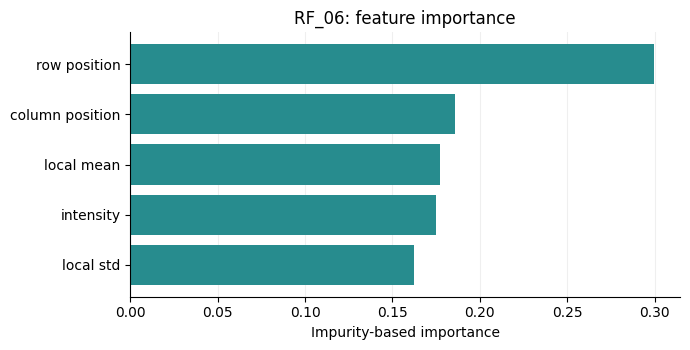

In [ ]:
f = feature_importance.sort_values('Importance')
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(f['Feature'].str.replace('_', ' '), f['Importance'], color='#278C8E')
ax.set(title='RF_06: feature importance', xlabel='Impurity-based importance')
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

RF_05 achieved mean Dice 0.346444 in 103.05 seconds, compared with 0.346771 in 196.44 seconds for RF_06. Doubling the tree count produced a gain of only 0.000327 Dice and approximately doubled the stored forest size (176.93 versus 354.12 MiB).

Row position had the highest RF_06 importance (0.299431), followed by column position (0.185843). These are impurity-based importances and describe feature use within the fitted forest; they do not establish causality.

The original CNN training log records 23.48 minutes and the RV-weighted run records 21.15 minutes. Historical hardware was not recorded, so these are descriptive timings rather than a controlled hardware comparison. The CNN checkpoint files are approximately 279.87 MiB each and contain optimizer state as well as weights; their sizes are not weights-only inference sizes.

### 8.3 Interpretation

On the validation patients, both U-Nets are far ahead of the classical models. Logistic Regression labels a lot of tissue outside the heart as heart, which shows up as very low precision. The Random Forest finds the right area but draws rough, oversized regions. The RV-weighted loss helped the right ventricle at end-systole a little, but it did not fix the hardest cases.

Section 9 tries one more improvement and picks the final model using a rule fixed in advance. Section 10 then checks everything once on the 50 test patients.

## <span style="color:#247C87">9. Final model: fine-tuning and selection</span>

### 9.1 Setup and a shared evaluator

This cell can be run on its own in a fresh Colab session with a T4 GPU. It reloads the split and the preprocessed volumes, then defines one evaluator that every U-Net is scored with from here on. The evaluator predicts whole volumes, can optionally clean up the prediction, and computes Dice, precision and recall per structure. The two phases are averaged within each patient, then patients are averaged with equal weight.

As a check, it re-scores the two saved U-Nets. Both match the earlier values (0.8904 and 0.8924), so the evaluator measures exactly what the earlier sections did. It also confirms that the test ZIPs include expert masks, which the final test needs.

In [1]:
# ===== FINAL STEP 1: setup, shared evaluator, and checks =====
from google.colab import drive
drive.mount('/content/drive')
%pip install -q segmentation-models-pytorch

import json, math, random, shutil, time, zipfile
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from scipy import ndimage

ROOT = Path('/content/drive/MyDrive/ACDC dataset')
DATA_DIR = ROOT / 'ACDC_patient_downloads'
PROC_DRIVE = ROOT / 'ACDC_preprocessed_288'
PROC_LOCAL = Path('/content/acdc_pre288')
EXP = ROOT / 'ACDC_experiments'
ORIGINAL_CKPT = EXP / 'unet_resnet34_seed42/best_model.pth'
WEIGHTED_CKPT = EXP / 'unet_resnet34_seed42_rv_weighted/best_model.pth'
FINETUNE_DIR = EXP / 'unet_resnet34_rv_weighted_finetune_aug'   # new folder, old runs untouched

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then rerun"
device = torch.device('cuda')
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| smp", smp.__version__)

# Same 80/20 patient split as every earlier experiment
split = pd.read_csv(DATA_DIR / 'patient_split_seed42.csv')
train_ids = sorted(split.loc[split['split'] == 'train', 'patient_id'])
val_ids = sorted(split.loc[split['split'] == 'validation', 'patient_id'])
assert len(train_ids) == 80 and len(val_ids) == 20 and not set(train_ids) & set(val_ids)

# Copy processed volumes to fast local disk, then load them into memory
VOLS = {}
for pid in train_ids + val_ids:
    for ph in ('ED', 'ES'):
        src, dst = PROC_DRIVE / pid / f'{ph}.npz', PROC_LOCAL / pid / f'{ph}.npz'
        if not dst.is_file():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)
        with np.load(dst) as d:
            VOLS[(pid, ph)] = (d['image'].astype(np.float32), d['mask'].astype(np.int64))
count = lambda ids: sum(VOLS[(p, ph)][0].shape[2] for p in ids for ph in ('ED', 'ES'))
print("Training slices:", count(train_ids), "| validation slices:", count(val_ids))   # expect 1504 | 398

# ---------- shared model loading, prediction, post-processing and scoring ----------
STRUCT = {1: 'RV', 2: 'Myocardium', 3: 'LV'}

def load_unet(path):
    model = smp.Unet('resnet34', encoder_weights=None, in_channels=1, classes=4)
    ck = torch.load(path, map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    return model.to(device).eval(), ck.get('epoch')

@torch.no_grad()
def predict_volume(model, img, tta=False):
    """Predict all slices of one volume. tta=True also averages 3 flipped versions."""
    x = torch.from_numpy(np.ascontiguousarray(np.transpose(img, (2, 0, 1))))[:, None].to(device)
    probs = torch.softmax(model(x), 1)
    if tta:
        for dims in ([3], [2], [2, 3]):
            probs += torch.softmax(model(x.flip(dims)), 1).flip(dims)
        probs /= 4
    return np.transpose(probs.argmax(1).cpu().numpy(), (1, 2, 0))   # back to (H, W, slices)

def keep_largest(pred):
    """Post-processing: for each structure keep only its largest 3D connected region."""
    out = np.zeros_like(pred)
    for c in STRUCT:
        lab, n = ndimage.label(pred == c)
        if n:
            out[lab == np.argmax(np.bincount(lab.ravel())[1:]) + 1] = c
    return out

def score(pred, gt):
    r = {}
    for c, n in STRUCT.items():
        p, g = pred == c, gt == c
        tp, np_, ng = np.count_nonzero(p & g), np.count_nonzero(p), np.count_nonzero(g)
        r[f'{n}_dice'] = 2 * tp / (np_ + ng) if np_ + ng else np.nan
        r[f'{n}_precision'] = tp / np_ if np_ else np.nan
        r[f'{n}_recall'] = tp / ng if ng else np.nan
    return r

def evaluate(model, ids, vols, tta=False, pp=False):
    model.eval()
    rows = []
    for pid in ids:
        for ph in ('ED', 'ES'):
            img, gt = vols[(pid, ph)]
            pred = predict_volume(model, img, tta)
            if pp:
                pred = keep_largest(pred)
            rows.append({'patient_id': pid, 'phase': ph, **score(pred, gt)})
    return pd.DataFrame(rows)

def summarize(df):
    """Average the two phases per patient, then patients equally, then the 3 structures."""
    cols = [c for c in df.columns if c.endswith(('_dice', '_precision', '_recall'))]
    s = df.groupby('patient_id')[cols].mean().mean()
    out = {n: s[f'{n}_dice'] for n in STRUCT.values()}
    out['Mean Dice'] = np.mean([out[n] for n in STRUCT.values()])
    out['Mean precision'] = np.mean([s[f'{n}_precision'] for n in STRUCT.values()])
    out['Mean recall'] = np.mean([s[f'{n}_recall'] for n in STRUCT.values()])
    out['ES RV Dice'] = df.loc[df['phase'] == 'ES', 'RV_dice'].mean()
    out['RV vols < 0.80'] = int((df['RV_dice'] < 0.80).sum())
    return out

# ---------- check: re-score both saved U-Nets with the shared evaluator ----------
for name, path, saved in [('Original U-Net', ORIGINAL_CKPT, 0.890434),
                          ('RV-weighted U-Net', WEIGHTED_CKPT, 0.892383)]:
    m, ep = load_unet(path)
    s = summarize(evaluate(m, val_ids, VOLS))
    print(f"{name} (epoch {ep}): mean Dice {s['Mean Dice']:.6f} | notebook value {saved} | ES RV {s['ES RV Dice']:.4f}")
    del m

# ---------- check: do the test ZIPs include expert masks? (file names only) ----------
test_zips = sorted((DATA_DIR / 'testing').glob('patient*.zip'))
names = [n.split('/')[-1] for n in zipfile.ZipFile(test_zips[0]).namelist()]
print("\nTest ZIPs:", len(test_zips), "|", test_zips[0].name, "contains:", names)
print("Expert masks in test ZIP:", any(n.endswith('_gt.nii.gz') for n in names))

Mounted at /content/drive
GPU: Tesla T4 | torch 2.14.1+cu130 | smp 0.6.0
Training slices: 1504 | validation slices: 398
Original U-Net (epoch 12): mean Dice 0.890435 | notebook value 0.890434 | ES RV 0.8232
RV-weighted U-Net (epoch 17): mean Dice 0.892383 | notebook value 0.892383 | ES RV 0.8358

Test ZIPs: 50 | patient101.zip contains: ['Info.cfg', 'patient101_frame01_gt.nii.gz', 'patient101_4d.nii.gz', 'patient101_frame01.nii.gz', 'patient101_frame14.nii.gz', 'patient101_frame14_gt.nii.gz', 'MANDATORY_CITATION.md']
Expert masks in test ZIP: True


### 9.2 Fine-tuning with augmentation

We start from the RV-weighted U-Net (epoch 17), keep the same loss, and train 10 more epochs on the 80 training patients with learning rates ten times smaller than before. During training each slice gets a random rotation (up to 15°), a zoom between 0.9 and 1.1, random left/right and up/down flips, and a small contrast change. The image and its mask always receive the same geometric change, and validation slices are never augmented.

After every epoch we score the 20 validation patients and keep the best epoch, but only if it beats the starting model. The new model is saved in its own folder, so the earlier runs stay untouched.

In [2]:
# ===== FINAL STEP 2: fine-tune the RV-weighted U-Net with augmentation =====
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

CONFIG = {
    'parent_checkpoint': str(WEIGHTED_CKPT),
    'loss': 'cross-entropy + foreground Dice with weights RV 2, Myocardium 1, LV 1 (same as parent)',
    'epochs': 10, 'batch_size': 8,
    'lr_encoder': 1e-5, 'lr_decoder_and_head': 1e-4, 'weight_decay': 1e-4,
    'optimizer': 'AdamW, fresh state (parent optimizer state not reused)',
    'augmentation': 'training only: rotation +-15 deg, scale 0.9-1.1, horizontal/vertical flips p=0.5, contrast x0.9-1.1',
    'selection': 'highest validation mean foreground Dice on complete volumes; kept only if better than parent',
    'seed': SEED, 'train_patients': 80, 'validation_patients': 20,
}
FINETUNE_DIR.mkdir(parents=True, exist_ok=True)
best_path = FINETUNE_DIR / 'best_model.pth'

def augment(x, y):
    """Same random rotation/scale/flip for image and mask; contrast change for image only."""
    B = x.shape[0]
    ang = (torch.rand(B, device=device) * 2 - 1) * math.radians(15)
    sc = 1 + (torch.rand(B, device=device) * 2 - 1) * 0.1
    fx = torch.where(torch.rand(B, device=device) < 0.5, -1.0, 1.0)
    fy = torch.where(torch.rand(B, device=device) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.zeros(B, 2, 3, device=device)
    theta[:, 0, 0], theta[:, 0, 1] = cos * fx, -sin * fy
    theta[:, 1, 0], theta[:, 1, 1] = sin * fx, cos * fy
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='zeros', align_corners=False)
    y = F.grid_sample(y[:, None].float(), grid, mode='nearest', align_corners=False)[:, 0].long()
    x = x * (1 + (torch.rand(B, 1, 1, 1, device=device) * 2 - 1) * 0.1)
    return x, y

DICE_WEIGHTS = torch.tensor([2.0, 1.0, 1.0], device=device)
def segmentation_loss(logits, targets, eps=1e-6):
    probs = torch.softmax(logits, 1)
    onehot = F.one_hot(targets, 4).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum((0, 2, 3))
    denom = probs.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    dice = (2 * inter + eps) / (denom + eps)
    dice_loss = ((1 - dice[1:]) * DICE_WEIGHTS).sum() / DICE_WEIGHTS.sum()
    return F.cross_entropy(logits, targets) + dice_loss

if best_path.exists():
    # Already trained in an earlier session: show the saved history instead of training again
    print("Fine-tuned model already saved:", best_path)
    display(pd.read_csv(FINETUNE_DIR / 'finetune_history.csv').round(4))
else:
    model, parent_epoch = load_unet(WEIGHTED_CKPT)
    CONFIG['parent_epoch'] = parent_epoch
    optimizer = torch.optim.AdamW([
        {'params': model.encoder.parameters(), 'lr': CONFIG['lr_encoder']},
        {'params': list(model.decoder.parameters()) + list(model.segmentation_head.parameters()),
         'lr': CONFIG['lr_decoder_and_head']},
    ], weight_decay=CONFIG['weight_decay'])

    train_items = [(p, ph, k) for p in train_ids for ph in ('ED', 'ES') for k in range(VOLS[(p, ph)][0].shape[2])]
    rng = np.random.default_rng(SEED)

    parent = summarize(evaluate(model, val_ids, VOLS))
    best_dice, best_epoch = parent['Mean Dice'], 0
    history = [{'epoch': 0, 'train_loss': np.nan, **parent}]
    print(f"Epoch 00 (parent) | val mean Dice {parent['Mean Dice']:.4f} | ES RV {parent['ES RV Dice']:.4f}")

    start = time.time()
    for epoch in range(1, CONFIG['epochs'] + 1):
        model.train()
        order, total = rng.permutation(len(train_items)), 0.0
        for b in range(0, len(order), CONFIG['batch_size']):
            batch = [train_items[i] for i in order[b:b + CONFIG['batch_size']]]
            x = torch.from_numpy(np.stack([VOLS[(p, ph)][0][:, :, k] for p, ph, k in batch]))[:, None].to(device)
            y = torch.from_numpy(np.stack([VOLS[(p, ph)][1][:, :, k] for p, ph, k in batch])).to(device)
            x, y = augment(x, y)
            optimizer.zero_grad(set_to_none=True)
            loss = segmentation_loss(model(x), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)

        s = summarize(evaluate(model, val_ids, VOLS))      # evaluate() switches to eval mode
        history.append({'epoch': epoch, 'train_loss': total / len(train_items), **s})
        note = ''
        if s['Mean Dice'] > best_dice:
            best_dice, best_epoch = s['Mean Dice'], epoch
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'val_mean_dice': best_dice, 'config': CONFIG}, best_path)   # weights only (smaller file)
            note = ' | best so far, saved'
        print(f"Epoch {epoch:02d} | train loss {total / len(train_items):.4f} | val mean Dice {s['Mean Dice']:.4f} "
              f"| ES RV {s['ES RV Dice']:.4f}{note}")
        pd.DataFrame(history).to_csv(FINETUNE_DIR / 'finetune_history.csv', index=False)

    minutes = (time.time() - start) / 60
    CONFIG.update({'training_minutes': round(minutes, 2), 'best_epoch': best_epoch,
                   'best_val_mean_dice': best_dice, 'parent_val_mean_dice': parent['Mean Dice'],
                   'gpu': torch.cuda.get_device_name(0)})
    (FINETUNE_DIR / 'config.json').write_text(json.dumps(CONFIG, indent=2))

    print(f"\nTraining time: {minutes:.1f} min")
    if best_epoch == 0:
        print("No epoch beat the parent model -> keep the RV-weighted U-Net as final (an honest negative result).")
    else:
        print(f"Best epoch {best_epoch}: val mean Dice {best_dice:.4f} vs parent {parent['Mean Dice']:.4f} "
              f"(+{best_dice - parent['Mean Dice']:.4f})")
        print("Saved:", best_path)
    display(pd.DataFrame(history).round(4))

Epoch 00 (parent) | val mean Dice 0.8924 | ES RV 0.8358
Epoch 01 | train loss 0.2362 | val mean Dice 0.8884 | ES RV 0.8162
Epoch 02 | train loss 0.1473 | val mean Dice 0.8895 | ES RV 0.8252
Epoch 03 | train loss 0.1381 | val mean Dice 0.8893 | ES RV 0.8189
Epoch 04 | train loss 0.1254 | val mean Dice 0.8927 | ES RV 0.8274 | best so far, saved
Epoch 05 | train loss 0.1186 | val mean Dice 0.8935 | ES RV 0.8284 | best so far, saved
Epoch 06 | train loss 0.1135 | val mean Dice 0.8922 | ES RV 0.8256
Epoch 07 | train loss 0.1097 | val mean Dice 0.8933 | ES RV 0.8268
Epoch 08 | train loss 0.1090 | val mean Dice 0.8931 | ES RV 0.8269
Epoch 09 | train loss 0.1052 | val mean Dice 0.8929 | ES RV 0.8263
Epoch 10 | train loss 0.1067 | val mean Dice 0.8913 | ES RV 0.8244

Training time: 6.4 min
Best epoch 5: val mean Dice 0.8935 vs parent 0.8924 (+0.0011)
Saved: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/unet_resnet34_rv_weighted_finetune_aug/best_model.pth


,epoch,train_loss,RV,Myocardium,LV,Mean Dice,Mean precision,Mean recall,ES RV Dice,RV vols < 0.80
0,0,NaN,0.8811,0.8646,0.9315,0.8924,0.8968,0.8937,0.8358,6
1,1,0.2362,0.8682,0.8679,0.9290,0.8884,0.8914,0.8920,0.8162,10
2,2,0.1473,0.8732,0.8665,0.9290,0.8895,0.9014,0.8854,0.8252,7
3,3,0.1381,0.8695,0.8693,0.9290,0.8893,0.8958,0.8907,0.8189,9
4,4,0.1254,0.8754,0.8724,0.9303,0.8927,0.9024,0.8898,0.8274,7
5,5,0.1186,0.8762,0.8730,0.9314,0.8935,0.8911,0.9024,0.8284,8
6,6,0.1135,0.8741,0.8723,0.9301,0.8922,0.8943,0.8969,0.8256,8
7,7,0.1097,0.8739,0.8727,0.9333,0.8933,0.9001,0.8936,0.8268,8
8,8,0.1090,0.8745,0.8725,0.9321,0.8931,0.9013,0.8914,0.8269,7
9,9,0.1052,0.8750,0.8721,0.9315,0.8929,0.9018,0.8903,0.8263,8


**What we saw:** the best epoch (5) reached a validation mean Dice of 0.8935, against 0.8924 for the starting model. That gap is about the same size as the normal wobble from one epoch to the next. The myocardium improved (0.8646 to 0.8730), but the right ventricle, the structure we were trying to help, got slightly worse (0.8811 to 0.8762 overall, 0.8358 to 0.8284 at ES). So fine-tuning with augmentation did not give a clear improvement.

The learning rates were fixed, standard transfer-learning values (ten times lower for fine-tuning). We did not search over them.

### 9.3 Choosing the final model

We compare the three U-Nets, each with and without two extras that need no training:

- **clean-up**: for each structure, keep only its largest connected region, which removes small stray specks;
- **flip averaging**: predict the image and three mirrored copies, flip the predictions back, and average them.

The selection rule was written down before this cell was run: take the highest validation mean Dice, and if several candidates are within 0.002 of the best, take the one with the higher ES RV Dice, since that was our main failure.

In [3]:
# ===== FINAL STEP 3: choose the final model on the 20 validation patients =====
# Rule fixed BEFORE seeing these results: highest mean foreground Dice; if candidates are
# within 0.002 of the best, prefer the higher ES RV Dice (our main failure mode).
CANDIDATES = {
    'Original U-Net': ORIGINAL_CKPT,
    'RV-weighted U-Net': WEIGHTED_CKPT,
    'RV-weighted + fine-tuned': FINETUNE_DIR / 'best_model.pth',
}
VARIANTS = {
    'plain': dict(tta=False, pp=False),
    '+ clean-up': dict(tta=False, pp=True),
    '+ flips': dict(tta=True, pp=False),
    '+ flips + clean-up': dict(tta=True, pp=True),
}

rows, per_volume = [], {}
for mname, path in CANDIDATES.items():
    m, ep = load_unet(path)
    for vname, kw in VARIANTS.items():
        df = evaluate(m, val_ids, VOLS, **kw)
        per_volume[(mname, vname)] = df
        rows.append({'Model': mname, 'Epoch': ep, 'Variant': vname, **summarize(df)})
        print(f"{mname:26s} {vname:20s} mean Dice {rows[-1]['Mean Dice']:.4f} | ES RV {rows[-1]['ES RV Dice']:.4f}")
    del m; torch.cuda.empty_cache()

table = pd.DataFrame(rows)
table.to_csv(EXP / 'final_model_selection_validation.csv', index=False)

best = table['Mean Dice'].max()
choice = table[table['Mean Dice'] >= best - 0.002].sort_values('ES RV Dice', ascending=False).iloc[0]
FINAL = {
    'model': choice['Model'], 'variant': choice['Variant'],
    'checkpoint': str(CANDIDATES[choice['Model']]),
    'tta': VARIANTS[choice['Variant']]['tta'], 'pp': VARIANTS[choice['Variant']]['pp'],
    'val_mean_dice': float(choice['Mean Dice']), 'val_es_rv_dice': float(choice['ES RV Dice']),
    'rule': 'highest validation mean Dice; within 0.002 -> higher ES RV Dice',
}
(EXP / 'final_model_choice.json').write_text(json.dumps(FINAL, indent=2))
per_volume[(choice['Model'], choice['Variant'])].to_csv(EXP / 'final_model_validation_per_volume.csv', index=False)

print("\nFINAL MODEL:", FINAL['model'], "|", FINAL['variant'])
print(f"Validation mean Dice {FINAL['val_mean_dice']:.4f} | ES RV {FINAL['val_es_rv_dice']:.4f}")
display(table.round(4))

Original U-Net             plain                mean Dice 0.8904 | ES RV 0.8232
Original U-Net             + clean-up           mean Dice 0.8910 | ES RV 0.8241
Original U-Net             + flips              mean Dice 0.6155 | ES RV 0.2526
Original U-Net             + flips + clean-up   mean Dice 0.6075 | ES RV 0.2388
RV-weighted U-Net          plain                mean Dice 0.8924 | ES RV 0.8358
RV-weighted U-Net          + clean-up           mean Dice 0.8934 | ES RV 0.8366
RV-weighted U-Net          + flips              mean Dice 0.6147 | ES RV 0.1837
RV-weighted U-Net          + flips + clean-up   mean Dice 0.6082 | ES RV 0.1604
RV-weighted + fine-tuned   plain                mean Dice 0.8935 | ES RV 0.8284
RV-weighted + fine-tuned   + clean-up           mean Dice 0.8951 | ES RV 0.8342
RV-weighted + fine-tuned   + flips              mean Dice 0.8919 | ES RV 0.8205
RV-weighted + fine-tuned   + flips + clean-up   mean Dice 0.8918 | ES RV 0.8198

FINAL MODEL: RV-weighted U-Net | + clea

,Model,Epoch,Variant,RV,Myocardium,LV,Mean Dice,Mean precision,Mean recall,ES RV Dice,RV vols < 0.80
0,Original U-Net,12,plain,0.8733,0.8659,0.9321,0.8904,0.9009,0.8870,0.8232,9
1,Original U-Net,12,+ clean-up,0.8747,0.8649,0.9333,0.8910,0.9042,0.8848,0.8241,8
2,Original U-Net,12,+ flips,0.2665,0.7277,0.8523,0.6155,0.9543,0.5247,0.2526,40
3,Original U-Net,12,+ flips + clean-up,0.2554,0.7211,0.8461,0.6075,0.9607,0.5184,0.2388,40
4,RV-weighted U-Net,17,plain,0.8811,0.8646,0.9315,0.8924,0.8968,0.8937,0.8358,6
5,RV-weighted U-Net,17,+ clean-up,0.8816,0.8654,0.9333,0.8934,0.9000,0.8925,0.8366,6
6,RV-weighted U-Net,17,+ flips,0.1541,0.7890,0.9010,0.6147,0.9351,0.5526,0.1837,40
7,RV-weighted U-Net,17,+ flips + clean-up,0.1374,0.7865,0.9008,0.6082,0.9433,0.5477,0.1604,40
8,RV-weighted + fine-tuned,5,plain,0.8762,0.8730,0.9314,0.8935,0.8911,0.9024,0.8284,8
9,RV-weighted + fine-tuned,5,+ clean-up,0.8795,0.8722,0.9337,0.8951,0.8951,0.9014,0.8342,7


Two things stand out. First, flip averaging badly hurt the two models that never saw flipped images during training: their RV Dice fell to roughly 0.15 to 0.27. The fine-tuned model, which was trained with flips, was barely affected. This suggests the earlier models rely on the right ventricle usually sitting on the same side of the image, much like the Random Forest relying on pixel position (Section 8.2). Second, clean-up gave a small gain for every model.

Following the rule, the final model is the **RV-weighted U-Net with clean-up** (validation mean Dice 0.8934, ES RV Dice 0.8366). The fine-tuned version scored 0.8951, which is within 0.002, but its ES RV Dice was lower (0.8342). The final model is frozen from this point on.

## <span style="color:#247C87">10. Final test on 50 unseen patients</span>

### 10.1 Before the test: checking the test data and the saved models

Before scoring anything on the test set, we made sure everything was in place. These checks only read file names inside the ZIPs and load the saved models. They do not compute any test scores.

First, every test ZIP should contain the MRI frames, the two expert masks (ED and ES) and an Info.cfg file.

In [5]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

root = Path("/content/drive/MyDrive/ACDC dataset/ACDC_patient_downloads")
test_dir = root / "testing"

results = []

for zip_path in sorted(test_dir.glob("patient*.zip")):
    with ZipFile(zip_path, "r") as z:
        names = z.namelist()

    nii_files = [
        n for n in names
        if n.lower().endswith(".nii.gz")
    ]

    gt_files = [
        n for n in nii_files
        if "_gt.nii.gz" in n.lower()
    ]

    image_files = [
        n for n in nii_files
        if "_gt.nii.gz" not in n.lower()
    ]

    info_files = [
        n for n in names
        if Path(n).name.lower() == "info.cfg"
    ]

    results.append({
        "Patient": zip_path.stem,
        "MRI_files": len(image_files),
        "Expert_masks": len(gt_files),
        "Info_cfg": len(info_files) > 0,
        "Example_MRI": Path(image_files[0]).name if image_files else "Missing",
        "Example_mask": Path(gt_files[0]).name if gt_files else "Missing"
    })

test_inventory = pd.DataFrame(results)

print("--- TEST ARCHIVE CONTENTS ---")
display(test_inventory)

print("\n--- SUMMARY ---")
print("Patients:", len(test_inventory))
print("Patients with MRI files:", (test_inventory["MRI_files"] > 0).sum())
print("Patients with expert masks:", (test_inventory["Expert_masks"] > 0).sum())
print("Patients with Info.cfg:", test_inventory["Info_cfg"].sum())

print("\n--- DEVELOPMENT SPLIT ---")
split_path = root / "patient_split_seed42.csv"
split_df = pd.read_csv(split_path)

print("Unique patients:", split_df["patient_id"].nunique())
print("\nPatients per split:")
display(split_df["split"].value_counts())

print("\nConditions per split:")
display(pd.crosstab(split_df["split"], split_df["condition"]))

--- TEST ARCHIVE CONTENTS ---


,Patient,MRI_files,Expert_masks,Info_cfg,Example_MRI,Example_mask
0,patient101,3,2,True,patient101_4d.nii.gz,patient101_frame01_gt.nii.gz
1,patient102,3,2,True,patient102_frame13.nii.gz,patient102_frame13_gt.nii.gz
2,patient103,3,2,True,patient103_frame11.nii.gz,patient103_frame01_gt.nii.gz
3,patient104,3,2,True,patient104_frame11.nii.gz,patient104_frame01_gt.nii.gz
4,patient105,3,2,True,patient105_4d.nii.gz,patient105_frame10_gt.nii.gz
5,patient106,3,2,True,patient106_frame13.nii.gz,patient106_frame13_gt.nii.gz
6,patient107,3,2,True,patient107_frame01.nii.gz,patient107_frame10_gt.nii.gz
7,patient108,3,2,True,patient108_frame09.nii.gz,patient108_frame09_gt.nii.gz
8,patient109,3,2,True,patient109_frame01.nii.gz,patient109_frame10_gt.nii.gz
9,patient110,3,2,True,patient110_frame01.nii.gz,patient110_frame11_gt.nii.gz



--- SUMMARY ---
Patients: 50
Patients with MRI files: 50
Patients with expert masks: 50
Patients with Info.cfg: 50

--- DEVELOPMENT SPLIT ---
Unique patients: 100

Patients per split:


,count
split,
train,80
validation,20



Conditions per split:


condition,DCM,HCM,MINF,NOR,RV
split,,,,,
train,16,16,16,16,16
validation,4,4,4,4,4


Load every saved classical model (Logistic Regression and all eight forests) to make sure none of the files is damaged.

In [17]:
import joblib
import gc
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/"
    "random_forest_20261106_151100_091562"
)

model_paths = {
    "Logistic Regression": MODEL_DIR / "logistic_regression.joblib",
    **{
        f"RF_{i:02d}": MODEL_DIR / f"RF_{i:02d}.joblib"
        for i in range(1, 9)
    }
}

for name, path in model_paths.items():
    try:
        model = joblib.load(path)

        print(f"SUCCESS: {name}")
        print(f"  Type: {type(model).__name__}")

        if hasattr(model, "n_features_in_"):
            print(f"  Input features: {model.n_features_in_}")

        if hasattr(model, "classes_"):
            print(f"  Classes: {model.classes_}")

        del model
        gc.collect()

    except Exception as e:
        print(f"ERROR: {name} | {type(e).__name__}: {e}")

    print("-" * 45)

SUCCESS: Logistic Regression
  Type: Pipeline
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_01
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_02
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_03
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_04
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_05
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_06
  Type: RandomForestClassifier
  Input features: 5
  Classes: [0 1 2 3]
---------------------------------------------
SUCCESS: RF_07
  Type: RandomForestClassifier
  Input features: 5
  C

Rebuild both U-Nets from their checkpoints and pass a blank input through them to check the output shape. This runs on the CPU, so it does not touch the GPU used later.

In [8]:
import torch
import segmentation_models_pytorch as smp
import gc
from pathlib import Path

check_device = torch.check_device("cpu")

EXPERIMENT_ROOT = Path(
    "/content/drive/MyDrive/ACDC dataset/ACDC_experiments"
)

checkpoints = {
    "Original U-Net": (
        EXPERIMENT_ROOT / "unet_resnet34_seed42" / "best_model.pth"
    ),
    "RV-weighted U-Net": (
        EXPERIMENT_ROOT / "unet_resnet34_seed42_rv_weighted"
        / "best_model.pth"
    )
}

for name, path in checkpoints.items():

    print(f"\n{name}")
    print("-" * 50)

    try:
        checkpoint = torch.load(
            path,
            map_location=check_device,
            weights_only=True
        )

        model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=1,
            classes=4
        ).to(check_device)

        model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )

        model.eval()

        dummy_input = torch.zeros(1, 1, 288, 288)

        with torch.no_grad():
            output = model(dummy_input)

        print("SUCCESS: Architecture recreated")
        print("SUCCESS: Checkpoint weights loaded")
        print("Input shape:", tuple(dummy_input.shape))
        print("Output shape:", tuple(output.shape))
        print("Output finite:", torch.isfinite(output).all().item())

        del model, checkpoint, dummy_input, output
        gc.collect()

    except Exception as e:
        print(f"ERROR: {type(e).__name__}: {e}")


Original U-Net
--------------------------------------------------
SUCCESS: Architecture recreated
SUCCESS: Checkpoint weights loaded
Input shape: (1, 1, 288, 288)
Output shape: (1, 4, 288, 288)
Output finite: True

RV-weighted U-Net
--------------------------------------------------
SUCCESS: Architecture recreated
SUCCESS: Checkpoint weights loaded
Input shape: (1, 1, 288, 288)
Output shape: (1, 4, 288, 288)
Output finite: True


Run both U-Nets on one real scan from the validation patients (patient007, a development patient, not a test patient) and check that the predictions look valid.

In [9]:
import numpy as np
import pandas as pd
import torch
import segmentation_models_pytorch as smp
from pathlib import Path
import gc

# Use the existing development validation split
PROJECT_ROOT = Path("/content/drive/MyDrive/ACDC dataset")
DATA_ROOT = PROJECT_ROOT / "ACDC_patient_downloads"
PROC_ROOT = PROJECT_ROOT / "ACDC_preprocessed_288"

split = pd.read_csv(DATA_ROOT / "patient_split_seed42.csv")
val_ids = sorted(
    split.loc[split["split"] == "validation", "patient_id"].tolist()
)

assert len(val_ids) == 20
assert PROC_ROOT.is_dir()

# Select one validation patient (not a test patient)
patient_id = val_ids[0]
phase = "ED"
processed_file = PROC_ROOT / patient_id / f"{phase}.npz"

assert processed_file.is_file(), f"Missing file: {processed_file}"

with np.load(processed_file, allow_pickle=False) as data:
    image = data["image"].astype(np.float32)
    truth = data["mask"]

assert image.ndim == 3
assert image.shape == truth.shape
assert image.shape[:2] == (288, 288)
assert np.isfinite(image).all()

print("Development patient:", patient_id)
print("Phase:", phase)
print("MRI volume shape:", image.shape)

# Recreate the architecture and load the saved checkpoints
check_device = torch.check_device("cpu")

EXPERIMENT_ROOT = PROJECT_ROOT / "ACDC_experiments"

checkpoints = {
    "Original U-Net": (
        EXPERIMENT_ROOT / "unet_resnet34_seed42" / "best_model.pth"
    ),
    "RV-weighted U-Net": (
        EXPERIMENT_ROOT / "unet_resnet34_seed42_rv_weighted"
        / "best_model.pth"
    )
}

for name, checkpoint_path in checkpoints.items():
    print(f"\n{name}")
    print("-" * 50)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=check_device,
        weights_only=True
    )

    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=1,
        classes=4
    ).to(check_device)

    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()

    predictions = []

    with torch.no_grad():
        for k in range(image.shape[2]):
            # Same orientation and channel format as the training Dataset
            x = torch.from_numpy(
                np.ascontiguousarray(image[:, :, k])
            ).unsqueeze(0).unsqueeze(0).to(check_device)

            logits = model(x)
            predicted_mask = logits.argmax(dim=1).squeeze(0)

            predictions.append(predicted_mask.cpu().numpy())

    prediction_volume = np.stack(predictions, axis=2)

    print("SUCCESS: Real MRI inference completed")
    print("Prediction volume shape:", prediction_volume.shape)
    print("Predicted labels:", np.unique(prediction_volume))
    print("All predictions finite:", np.isfinite(prediction_volume).all())

    del model, checkpoint, predictions, prediction_volume
    gc.collect()

Development patient: patient007
Phase: ED
MRI volume shape: (288, 288, 10)

Original U-Net
--------------------------------------------------
SUCCESS: Real MRI inference completed
Prediction volume shape: (288, 288, 10)
Predicted labels: [0 1 2 3]
All predictions finite: True

RV-weighted U-Net
--------------------------------------------------
SUCCESS: Real MRI inference completed
Prediction volume shape: (288, 288, 10)
Predicted labels: [0 1 2 3]
All predictions finite: True


The same check for Logistic Regression and RF_06 on one slice of that scan, using the same feature function as in training.

In [14]:
import joblib
import numpy as np
from pathlib import Path

# Saved classical model folder verified earlier
MODEL_DIR = Path(
    "/content/drive/MyDrive/ACDC dataset/experiments/"
    "random_forest_20261106_151100_091562"
)

lr_path = MODEL_DIR / "logistic_regression.joblib"
rf_path = MODEL_DIR / "RF_06.joblib"

assert lr_path.is_file(), f"Missing: {lr_path}"
assert rf_path.is_file(), f"Missing: {rf_path}"

# Load the two selected classical models
lr_model_check = joblib.load(lr_path)
rf06_model_check = joblib.load(rf_path)

# Confirm the feature definition from your notebook
EXPECTED_FEATURES = [
    "intensity",
    "local_mean",
    "local_std",
    "row_position",
    "column_position"
]

assert FEATURE_NAMES == EXPECTED_FEATURES

assert lr_model_check.n_features_in_ == 5
assert rf06_model_check.n_features_in_ == 5

# Use the same known development patient as the U-Net check
patient_id = "patient007"
phase = "ED"

volume, truth = load_processed_pair(patient_id, phase)

# Use the middle MRI slice
slice_index = volume.shape[2] // 2
image_slice = volume[:, :, slice_index]

# Extract features using the exact function used during training
features = extract_pixel_features(image_slice)

assert features.shape == (288 * 288, 5)
assert np.isfinite(features).all()

# Predict with both models
lr_prediction = lr_model_check.predict(features).reshape(288, 288)
rf06_prediction = rf06_model_check.predict(features).reshape(288, 288)

# Verify predictions
for name, prediction in [
    ("Logistic Regression", lr_prediction),
    ("RF_06", rf06_prediction)
]:
    assert prediction.shape == (288, 288)
    assert set(np.unique(prediction)).issubset({0, 1, 2, 3})

    print(f"\n{name}")
    print("SUCCESS: Real MRI inference completed")
    print("Prediction shape:", prediction.shape)
    print("Predicted labels:", np.unique(prediction))

print("\nFeature order:", FEATURE_NAMES)
print("Feature matrix shape:", features.shape)
print("\nSUCCESS: Both classical models passed the real-data inference check.")


Logistic Regression
SUCCESS: Real MRI inference completed
Prediction shape: (288, 288)
Predicted labels: [0 1 2 3]

RF_06
SUCCESS: Real MRI inference completed
Prediction shape: (288, 288)
Predicted labels: [0 1 2 3]

Feature order: ['intensity', 'local_mean', 'local_std', 'row_position', 'column_position']
Feature matrix shape: (82944, 5)

SUCCESS: Both classical models passed the real-data inference check.


All 50 test patients have their images, both expert masks and Info.cfg, and every saved model loads and produces valid predictions with all four labels. The fine-tuned U-Net was checked the same way when it was loaded in Section 9.3. Next, the actual test.

### 10.2 U-Nets on the test set

The 50 test patients go through exactly the same preprocessing as the development patients, and each model is scored once. Nothing about the models was changed after seeing these results. The cell saves its results, and if it is run again it just shows the saved results instead of testing a second time.

Besides the final model, the other U-Nets are scored too, so the report can show how the variants compare on unseen data.

In [4]:
# ===== FINAL STEP 4: preprocess the 50 test patients and score the frozen U-Nets (run once) =====
import gzip, nibabel as nib
from scipy.ndimage import zoom

TEST_PROC = ROOT / 'ACDC_preprocessed_288_test'
TEST_RESULTS = EXP / 'test_results'
TEST_PROC.mkdir(exist_ok=True); TEST_RESULTS.mkdir(exist_ok=True)
TARGET_SPACING, TARGET_SIZE = 1.5, (288, 288)
FINAL = json.loads((EXP / 'final_model_choice.json').read_text())
print("Frozen final model:", FINAL['model'], "|", FINAL['variant'])

# --- identical preprocessing to Section 5.3 (resample -> centre crop/pad -> normalise nonzero) ---
def center_crop_or_pad(a, target=TARGET_SIZE):
    th, tw = target; h, w = a.shape[:2]
    hs, ws = max((h - th) // 2, 0), max((w - tw) // 2, 0)
    c = a[hs:hs + min(h, th), ws:ws + min(w, tw), :]
    ph, pw = th - c.shape[0], tw - c.shape[1]
    return np.pad(c, ((ph // 2, ph - ph // 2), (pw // 2, pw - pw // 2), (0, 0))), (hs, ws, ph, pw)

def read_test_pair(zp, phase):
    with zipfile.ZipFile(zp) as z:
        names = {n.split('/')[-1]: n for n in z.namelist()}
        info = {}
        for line in z.read(names['Info.cfg']).decode('utf-8-sig').splitlines():
            if ':' in line:
                k, v = line.split(':', 1); info[k.strip()] = v.strip()
        pid, frame = zp.stem, int(info[phase])
        load = lambda n: nib.Nifti1Image.from_bytes(gzip.decompress(z.read(names[n])))
        img_f, msk_f = load(f'{pid}_frame{frame:02d}.nii.gz'), load(f'{pid}_frame{frame:02d}_gt.nii.gz')
    img, msk = img_f.get_fdata().astype(np.float32), msk_f.get_fdata()
    assert img.shape == msk.shape and np.allclose(msk, np.rint(msk)) and np.isfinite(img).all()
    return img, np.rint(msk).astype(np.uint8), tuple(float(s) for s in img_f.header.get_zooms()[:3]), info.get('Group')

def preprocess(img, msk, sp):
    f = (sp[0] / TARGET_SPACING, sp[1] / TARGET_SPACING, 1.0)
    img_r = zoom(img, f, order=1)
    msk_r = np.rint(zoom(msk, f, order=0)).astype(np.uint8)
    img_c, geo = center_crop_or_pad(img_r)
    msk_c, _ = center_crop_or_pad(msk_r)
    nz = img_c != 0
    x = np.zeros_like(img_c, dtype=np.float32)
    x[nz] = (img_c[nz] - img_c[nz].mean()) / img_c[nz].std()
    lost = any((msk_c == l).sum() < (msk_r == l).sum() for l in (1, 2, 3))
    assert x.shape[:2] == TARGET_SIZE and np.isfinite(x).all() and set(np.unique(msk_c)) <= {0, 1, 2, 3}
    return x, msk_c, geo, lost

test_ids = [zp.stem for zp in test_zips]
assert len(test_ids) == 50 and not set(test_ids) & set(train_ids + val_ids)
TEST_VOLS, GROUPS, lost_any = {}, {}, []
t0 = time.time()
for zp in test_zips:
    pid = zp.stem
    for ph in ('ED', 'ES'):
        out = TEST_PROC / pid / f'{ph}.npz'
        if out.is_file():
            with np.load(out) as d:
                TEST_VOLS[(pid, ph)] = (d['image'], d['mask'].astype(np.int64))
                meta = json.loads(str(d['metadata']))
        else:
            img, msk, sp, group = read_test_pair(zp, ph)
            x, y, geo, lost = preprocess(img, msk, sp)
            meta = {'group': group, 'original_shape': list(img.shape), 'original_spacing': list(sp),
                    'crop_start': [int(geo[0]), int(geo[1])], 'padding_hw': [int(geo[2]), int(geo[3])],
                    'foreground_lost': bool(lost)}
            out.parent.mkdir(parents=True, exist_ok=True)
            np.savez_compressed(out, image=x, mask=y, metadata=json.dumps(meta))
            TEST_VOLS[(pid, ph)] = (x, y.astype(np.int64))
        GROUPS[pid] = meta['group']
        if meta['foreground_lost']:
            lost_any.append((pid, ph))
print(f"Test volumes ready: {len(TEST_VOLS)} (expect 100) in {time.time() - t0:.0f}s | "
      f"slices: {sum(v[0].shape[2] for v in TEST_VOLS.values())} | foreground cut by crop: {lost_any or 'none'}")
print("Test patients per group:", pd.Series(GROUPS).value_counts().to_dict())

# --- score the frozen U-Nets once ---
TEST_MODELS = [
    ('Original U-Net', 'plain', ORIGINAL_CKPT, False),
    ('RV-weighted U-Net', 'plain', WEIGHTED_CKPT, False),
    ('RV-weighted U-Net', '+ clean-up', WEIGHTED_CKPT, True),
    ('RV-weighted + fine-tuned', '+ clean-up', FINETUNE_DIR / 'best_model.pth', True),
]
fname = lambda m, v: TEST_RESULTS / f"test_per_volume__{m}__{v}.csv".replace(' ', '_').replace('+', 'plus')
summary_file = TEST_RESULTS / 'cnn_test_summary.csv'
if summary_file.is_file():
    print("\nTest was already run once - showing the saved results, not re-running.")
    test_table = pd.read_csv(summary_file)
else:
    rows = []
    for mname, vname, path, pp in TEST_MODELS:
        m, ep = load_unet(path)
        df = evaluate(m, test_ids, TEST_VOLS, tta=False, pp=pp)
        df.to_csv(fname(mname, vname), index=False)
        rows.append({'Model': mname, 'Variant': vname,
                     'Final': mname == FINAL['model'] and vname == FINAL['variant'], **summarize(df)})
        del m; torch.cuda.empty_cache()
    test_table = pd.DataFrame(rows)
    test_table.to_csv(summary_file, index=False)

val_table = pd.read_csv(EXP / 'final_model_selection_validation.csv')
both = test_table.merge(val_table[['Model', 'Variant', 'Mean Dice', 'ES RV Dice']],
                        on=['Model', 'Variant'], suffixes=(' (test)', ' (val)'))
print("\nU-Nets: TEST (50 unseen patients) vs VALIDATION (20 patients)")
display(both.round(4))

# --- final model: test results by disease group and by phase ---
final_df = pd.read_csv(fname(FINAL['model'], FINAL['variant']))
final_df['group'] = final_df['patient_id'].map(GROUPS)
final_df['Mean_dice'] = final_df[['RV_dice', 'Myocardium_dice', 'LV_dice']].mean(axis=1)
print("\nFinal model on TEST by disease group:")
display(final_df.groupby('group')[['RV_dice', 'Myocardium_dice', 'LV_dice', 'Mean_dice']].mean().round(4))
print("Final model on TEST by phase:")
display(final_df.groupby('phase')[['RV_dice', 'Myocardium_dice', 'LV_dice', 'Mean_dice']].mean().round(4))
print("Five weakest test volumes:")
display(final_df.nsmallest(5, 'Mean_dice')[['patient_id', 'phase', 'group', 'RV_dice', 'Myocardium_dice', 'LV_dice']].round(4))

Frozen final model: RV-weighted U-Net | + clean-up
Test volumes ready: 100 (expect 100) in 204s | slices: 1076 | foreground cut by crop: none
Test patients per group: {'DCM': 10, 'NOR': 10, 'MINF': 10, 'HCM': 10, 'RV': 10}

U-Nets: TEST (50 unseen patients) vs VALIDATION (20 patients)


,Model,Variant,Final,RV,Myocardium,LV,Mean Dice (test),Mean precision,Mean recall,ES RV Dice (test),RV vols < 0.80,Mean Dice (val),ES RV Dice (val)
0,Original U-Net,plain,False,0.8916,0.8775,0.9325,0.9005,0.9121,0.8943,0.8595,13,0.8904,0.8232
1,RV-weighted U-Net,plain,False,0.8940,0.8755,0.9254,0.8983,0.9047,0.8982,0.8652,12,0.8924,0.8358
2,RV-weighted U-Net,+ clean-up,True,0.8936,0.8765,0.9239,0.8980,0.9070,0.8960,0.8640,12,0.8934,0.8366
3,RV-weighted + fine-tuned,+ clean-up,False,0.8999,0.8799,0.9270,0.9022,0.9055,0.9056,0.8721,9,0.8951,0.8342



Final model on TEST by disease group:


,RV_dice,Myocardium_dice,LV_dice,Mean_dice
group,,,,
DCM,0.9119,0.8591,0.9586,0.9099
HCM,0.8838,0.8999,0.8533,0.8790
MINF,0.8587,0.8837,0.9568,0.8997
NOR,0.9037,0.8741,0.9144,0.8974
RV,0.9097,0.8657,0.9362,0.9039


Final model on TEST by phase:


,RV_dice,Myocardium_dice,LV_dice,Mean_dice
phase,,,,
ED,0.9231,0.8669,0.9563,0.9155
ES,0.8640,0.8860,0.8914,0.8805


Five weakest test volumes:


,patient_id,phase,group,RV_dice,Myocardium_dice,LV_dice
15,patient108,ES,HCM,0.8653,0.8727,0.6045
51,patient126,ES,RV,0.7831,0.7821,0.8126
83,patient142,ES,HCM,0.7712,0.9387,0.6697
27,patient114,ES,HCM,0.7515,0.9069,0.7399
7,patient104,ES,HCM,0.8441,0.8934,0.6974


The final model reaches a mean Dice of **0.898** on the test set (RV 0.894, myocardium 0.877, LV 0.924), close to its validation score of 0.893. The other U-Nets land between 0.898 and 0.902. Those gaps are as small as the noise we saw on validation, so we do not treat them as real differences, and we keep the model the rule picked rather than switching to whichever did best on test.

End-systole is still harder than end-diastole (0.881 against 0.916). The hypertrophic group (HCM) is the weakest (0.879), mostly because of the left ventricle: four of the five worst test volumes are HCM at end-systole, when the thick heart muscle squeezes the LV cavity down to a very small area.

### 10.3 Classical models on the test set

Logistic Regression and the selected Random Forest (RF_06) are scored on the same 50 patients. The first line re-scores Logistic Regression on validation to confirm the pixel features are computed exactly as before.

In [5]:
# ===== FINAL STEP 5: Logistic Regression and Random Forest (RF_06) on the 50 test patients (run once) =====
import joblib
from scipy.ndimage import uniform_filter

CLASSICAL_DIR = ROOT / 'experiments/random_forest_20261106_151100_091562'

def extract_pixel_features(image_slice):
    """Same 5 features as Section 4: intensity, 5x5 local mean and std, row and column position."""
    img = np.asarray(image_slice, dtype=np.float32)
    m = uniform_filter(img, size=5, mode='reflect')
    sd = np.sqrt(np.maximum(uniform_filter(img * img, size=5, mode='reflect') - m ** 2, 0))
    h, w = img.shape
    rows = np.broadcast_to(np.linspace(0, 1, h, dtype=np.float32)[:, None], img.shape)
    cols = np.broadcast_to(np.linspace(0, 1, w, dtype=np.float32)[None, :], img.shape)
    return np.stack([img, m, sd, rows, cols], axis=-1).reshape(-1, 5)

def evaluate_classical(model, ids, vols):
    rows = []
    for pid in ids:
        for ph in ('ED', 'ES'):
            img, gt = vols[(pid, ph)]
            pred = np.stack([model.predict(extract_pixel_features(img[:, :, k])).reshape(img.shape[:2])
                             for k in range(img.shape[2])], axis=-1)
            rows.append({'patient_id': pid, 'phase': ph, **score(pred, gt)})
    return pd.DataFrame(rows)

lr_model = joblib.load(CLASSICAL_DIR / 'logistic_regression.joblib')

# Check: Logistic Regression on validation should reproduce the notebook's mean Dice 0.0688
check = summarize(evaluate_classical(lr_model, val_ids, VOLS))
print(f"Check - LR validation mean Dice {check['Mean Dice']:.4f} (notebook: 0.0688)")

classical_file = TEST_RESULTS / 'classical_test_summary.csv'
if classical_file.is_file():
    print("Classical test was already run once - showing saved results.")
    classical_table = pd.read_csv(classical_file)
else:
    rows = []
    for name, path in [('Logistic Regression', CLASSICAL_DIR / 'logistic_regression.joblib'),
                       ('Random Forest (RF_06)', CLASSICAL_DIR / 'RF_06.joblib')]:
        t0 = time.time()
        model = lr_model if 'Logistic' in name else joblib.load(path)
        df = evaluate_classical(model, test_ids, TEST_VOLS)
        df.to_csv(fname(name, 'plain'), index=False)
        rows.append({'Model': name, 'Variant': 'plain', 'Final': False, **summarize(df),
                     'test_seconds': round(time.time() - t0, 1)})
        print(f"{name}: test mean Dice {rows[-1]['Mean Dice']:.4f} ({rows[-1]['test_seconds']}s)")
        del model
    classical_table = pd.DataFrame(rows)
    classical_table.to_csv(classical_file, index=False)

# One combined final table: all models on the 50 test patients
final_table = pd.concat([classical_table.drop(columns='test_seconds', errors='ignore'),
                         pd.read_csv(TEST_RESULTS / 'cnn_test_summary.csv')], ignore_index=True)
final_table.to_csv(TEST_RESULTS / 'all_models_test_summary.csv', index=False)
print("\nALL MODELS - TEST SET (50 unseen patients)")
display(final_table[['Model', 'Variant', 'Final', 'RV', 'Myocardium', 'LV', 'Mean Dice',
                     'Mean precision', 'Mean recall', 'ES RV Dice']].round(4))

Check - LR validation mean Dice 0.0688 (notebook: 0.0688)
Logistic Regression: test mean Dice 0.0725 (21.2s)
Random Forest (RF_06): test mean Dice 0.3405 (365.9s)

ALL MODELS - TEST SET (50 unseen patients)


,Model,Variant,Final,RV,Myocardium,LV,Mean Dice,Mean precision,Mean recall,ES RV Dice
0,Logistic Regression,plain,False,0.0441,0.0502,0.1232,0.0725,0.0397,0.5538,0.0294
1,Random Forest (RF_06),plain,False,0.2758,0.2782,0.4675,0.3405,0.2503,0.7170,0.2096
2,Original U-Net,plain,False,0.8916,0.8775,0.9325,0.9005,0.9121,0.8943,0.8595
3,RV-weighted U-Net,plain,False,0.8940,0.8755,0.9254,0.8983,0.9047,0.8982,0.8652
4,RV-weighted U-Net,+ clean-up,True,0.8936,0.8765,0.9239,0.8980,0.9070,0.8960,0.8640
5,RV-weighted + fine-tuned,+ clean-up,False,0.8999,0.8799,0.9270,0.9022,0.9055,0.9056,0.8721


The classical models behave on test the same way they did on validation: 0.073 for Logistic Regression and 0.340 for the Random Forest, against 0.898 for the final U-Net. Validation and test agree closely for every model, so the 20-patient validation split did not give us a misleading picture.

## <span style="color:#247C87">11. Final figures</span>

### 11.1 Saving the final model

The training checkpoints also store the optimizer state, which is only needed to keep training. This cell saves a smaller weights-only copy of the final model, together with a short note on its input format, for the GitHub release.

In [ ]:
# Save a weights-only copy of the final model for the GitHub release
FINAL_DIR = EXP / 'final_model'
FINAL_DIR.mkdir(exist_ok=True)

ck = torch.load(FINAL['checkpoint'], map_location='cpu', weights_only=False)
final_file = FINAL_DIR / 'acdc_unet_resnet34_rv_weighted_final.pth'
torch.save({'model_state_dict': ck['model_state_dict'], 'epoch': ck['epoch'],
            'architecture': "smp.Unet('resnet34', encoder_weights=None, in_channels=1, classes=4)",
            'post_processing': 'keep largest 3D connected component per structure',
            'input': '1 channel, 288x288 slice, 1.5 mm in-plane, z-score of nonzero voxels per volume',
            'labels': {0: 'background', 1: 'RV', 2: 'myocardium', 3: 'LV'}}, final_file)
print("Final model:", final_file, f"({final_file.stat().st_size / 2**20:.1f} MiB)")


Final model: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/final_model/acdc_unet_resnet34_rv_weighted_final.pth (93.4 MiB)


### 11.2 Validation and test for every model

One chart with every model's validation and test mean Dice side by side.

Final model file exists: True


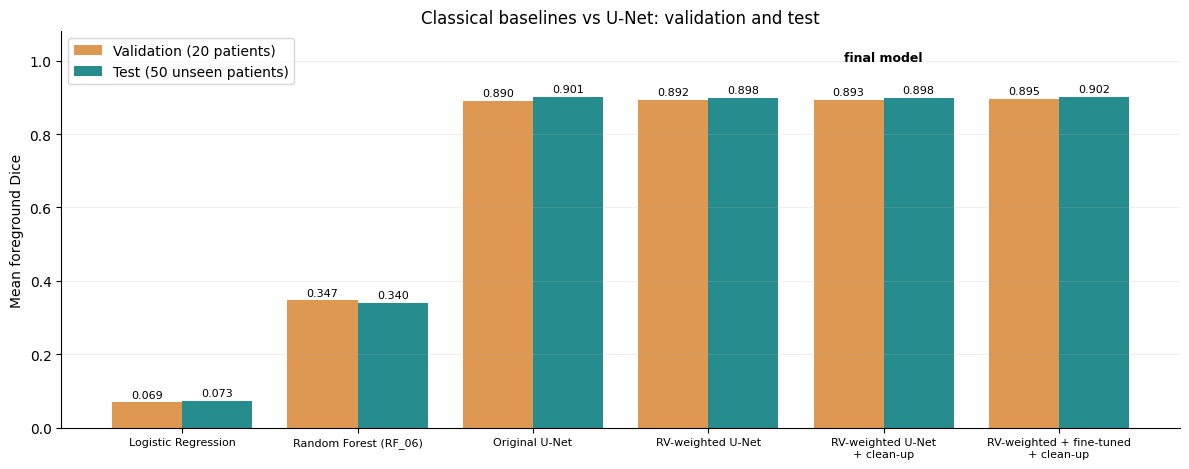

In [8]:
# ===== FINAL STEP 6 (figure): validation vs test mean Dice for every model =====
import matplotlib.pyplot as plt
FINAL_DIR = EXP / 'final_model'
FINAL_DIR.mkdir(exist_ok=True)
print("Final model file exists:", (FINAL_DIR / 'acdc_unet_resnet34_rv_weighted_final.pth').is_file())

val_tab = pd.read_csv(EXP / 'final_model_selection_validation.csv')
val_lookup = {(m, v): d for m, v, d in zip(val_tab['Model'], val_tab['Variant'], val_tab['Mean Dice'])}
val_lookup.update({('Logistic Regression', 'plain'): 0.0688, ('Random Forest (RF_06)', 'plain'): 0.3468})

t = pd.read_csv(TEST_RESULTS / 'all_models_test_summary.csv')
labels = [f"{m}\n{v}" if v != 'plain' else m for m, v in zip(t['Model'], t['Variant'])]
x = np.arange(len(t))
fig, ax = plt.subplots(figsize=(12, 4.8))
b1 = ax.bar(x - 0.2, [val_lookup[(m, v)] for m, v in zip(t['Model'], t['Variant'])], 0.4,
            label='Validation (20 patients)', color='#DE9851')
b2 = ax.bar(x + 0.2, t['Mean Dice'], 0.4, label='Test (50 unseen patients)', color='#278C8E')
ax.bar_label(b1, fmt='%.3f', fontsize=8, padding=2); ax.bar_label(b2, fmt='%.3f', fontsize=8, padding=2)
i_final = int(np.flatnonzero(t['Final'].astype(bool))[0])
ax.annotate('final model', (i_final, 1.0), ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x, labels, fontsize=8); ax.set_ylim(0, 1.08); ax.set_ylabel('Mean foreground Dice')
ax.set_title('Classical baselines vs U-Net: validation and test'); ax.legend(loc='upper left')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); fig.savefig(FINAL_DIR / 'final_validation_vs_test.png', dpi=200); plt.show()

### 11.3 Results figures

These figures only read results that are already saved, so they are not extra test runs. They show the test results table, Dice by structure, end-diastole against end-systole, the spread within each disease group, three example test scans (best, median and worst) with an error map, and one test slice segmented by every model.

,Final,Model,Variant,RV,Myocardium,LV,Mean Dice,Mean precision,Mean recall,ES RV Dice
0,,Logistic Regression,plain,0.044,0.050,0.123,0.073,0.040,0.554,0.029
1,,Random Forest (RF_06),plain,0.276,0.278,0.468,0.340,0.250,0.717,0.210
2,,Original U-Net,plain,0.892,0.877,0.932,0.901,0.912,0.894,0.859
3,,RV-weighted U-Net,plain,0.894,0.875,0.925,0.898,0.905,0.898,0.865
4,yes,RV-weighted U-Net,+ clean-up,0.894,0.876,0.924,0.898,0.907,0.896,0.864
5,,RV-weighted + fine-tuned,+ clean-up,0.900,0.880,0.927,0.902,0.905,0.906,0.872


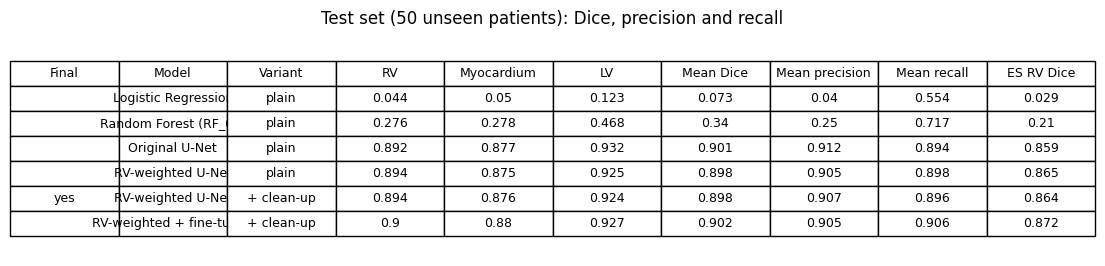

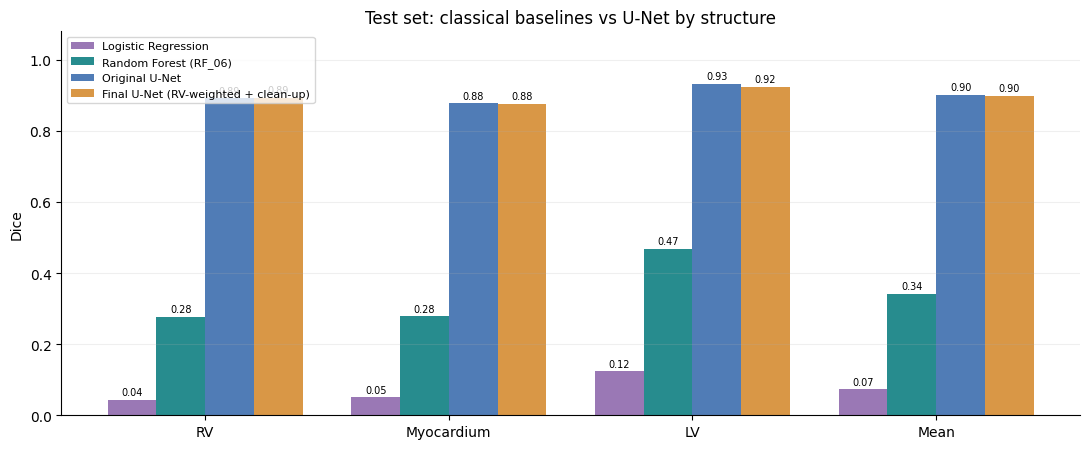

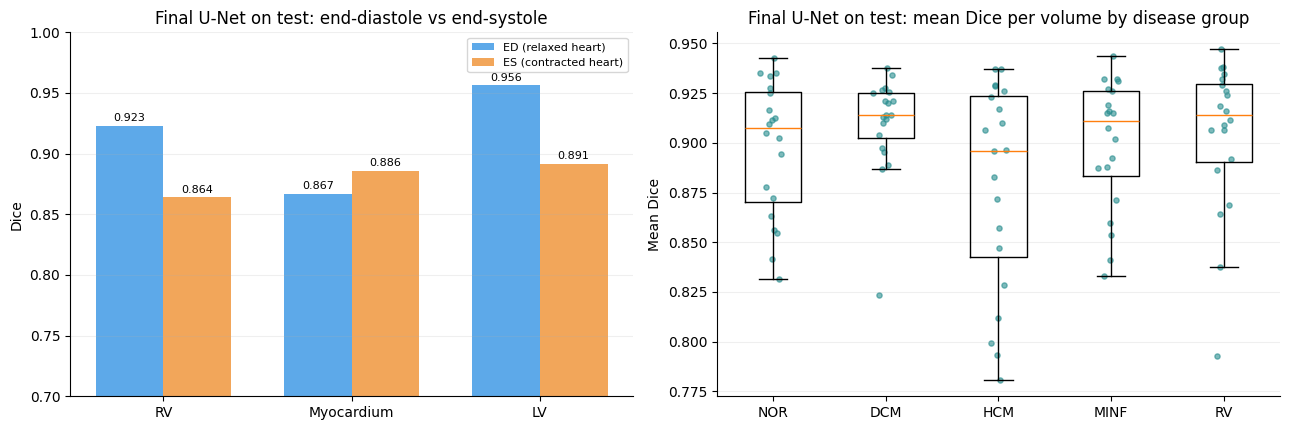

Groups: NOR normal, DCM dilated cardiomyopathy, HCM hypertrophic cardiomyopathy, MINF previous myocardial infarction, RV abnormal right ventricle


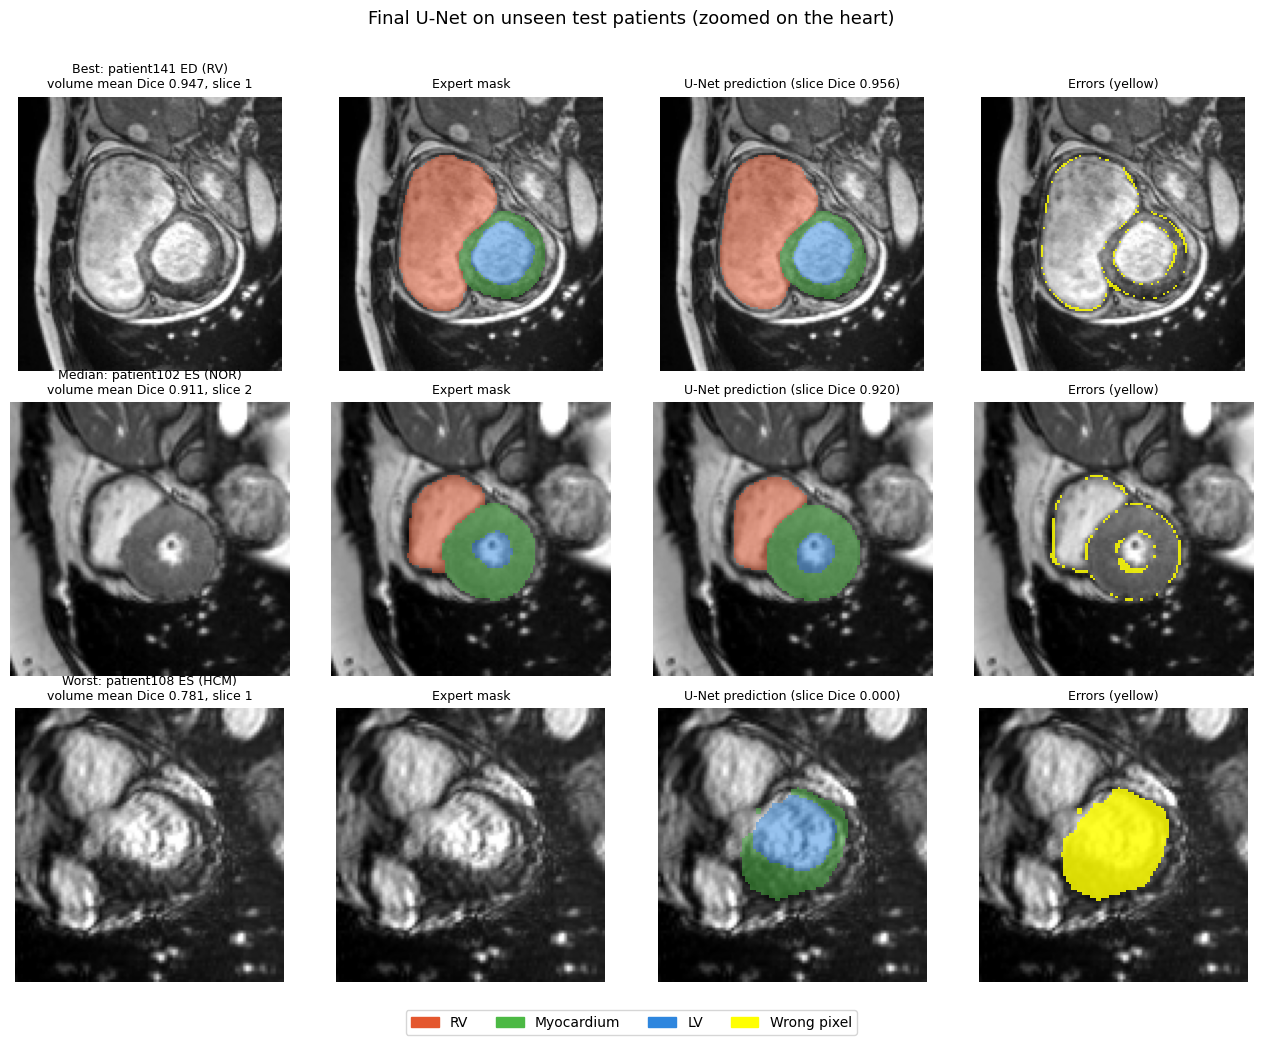

Loading classical models (the forest takes ~1 min)...


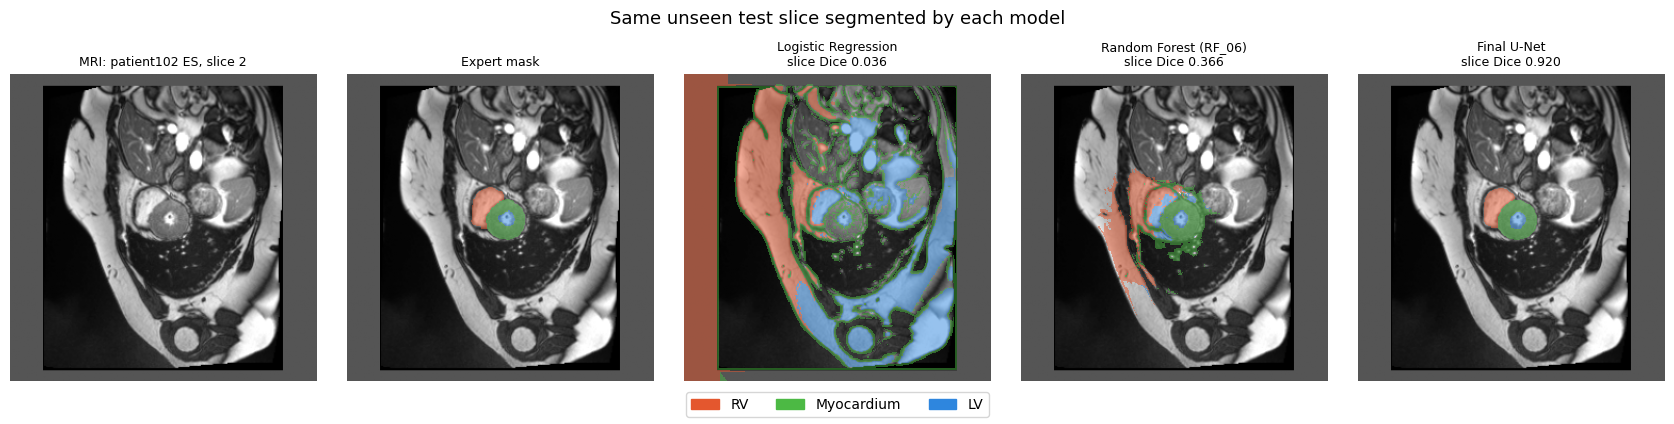


All figures saved in: /content/drive/MyDrive/ACDC dataset/ACDC_experiments/final_model/figures
   01_test_results_table.png
   02_test_dice_by_structure.png
   03_test_phase_and_group.png
   04_test_mri_examples.png
   05_test_model_ladder_same_slice.png


In [9]:
# ===== FINAL STEP 7: results showcase - figures and tables from the saved test results =====
import matplotlib.pyplot as plt, joblib
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

FIG = FINAL_DIR / 'figures'; FIG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
SEG_COLORS = ['#E4572E', '#4CB944', '#2E86DE']                       # RV, myocardium, LV
SEG_CMAP = ListedColormap(SEG_COLORS)
LEGEND = [Patch(color=c, label=l) for c, l in zip(SEG_COLORS, ['RV', 'Myocardium', 'LV'])]

t = pd.read_csv(TEST_RESULTS / 'all_models_test_summary.csv')
fd = pd.read_csv(fname(FINAL['model'], FINAL['variant']))
fd['group'] = fd['patient_id'].map(GROUPS)
fd['Mean'] = fd[['RV_dice', 'Myocardium_dice', 'LV_dice']].mean(axis=1)

def show(ax, img, seg=None, title='', box=None, err=None):
    if box is not None:
        sl = (slice(box[0], box[1]), slice(box[2], box[3]))
        img = img[sl]; seg = None if seg is None else seg[sl]; err = None if err is None else err[sl]
    lo, hi = np.percentile(img, [1, 99])
    ax.imshow(img.T, cmap='gray', origin='lower', vmin=lo, vmax=hi)
    if seg is not None:
        ax.imshow(np.ma.masked_equal(seg, 0).T, cmap=SEG_CMAP, vmin=1, vmax=3, alpha=0.5,
                  origin='lower', interpolation='nearest')
    if err is not None:
        ax.imshow(np.ma.masked_equal(err.astype(int), 0).T, cmap=ListedColormap(['yellow']),
                  alpha=0.85, origin='lower', interpolation='nearest')
    ax.set_title(title, fontsize=9); ax.axis('off')

def slice_mean_dice(pred, gt):
    s = score(pred, gt)
    return np.nanmean([s['RV_dice'], s['Myocardium_dice'], s['LV_dice']])

# ---------- 1. Results table ----------
tab = t[['Model', 'Variant', 'RV', 'Myocardium', 'LV', 'Mean Dice', 'Mean precision', 'Mean recall', 'ES RV Dice']].copy()
tab.insert(0, 'Final', np.where(t['Final'], 'yes', ''))
display(tab.round(3))
fig, ax = plt.subplots(figsize=(14, 2.8)); ax.axis('off')
tb = ax.table(cellText=tab.round(3).values, colLabels=tab.columns, loc='center', cellLoc='center')
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.5)
ax.set_title('Test set (50 unseen patients): Dice, precision and recall', pad=12)
fig.savefig(FIG / '01_test_results_table.png', dpi=200, bbox_inches='tight'); plt.show()

# ---------- 2. Model ladder by structure ----------
rows = [t[(t.Model == 'Logistic Regression')].iloc[0], t[(t.Model == 'Random Forest (RF_06)')].iloc[0],
        t[(t.Model == 'Original U-Net') & (t.Variant == 'plain')].iloc[0], t[t.Final].iloc[0]]
names = ['Logistic Regression', 'Random Forest (RF_06)', 'Original U-Net', 'Final U-Net (RV-weighted + clean-up)']
colors = ['#9A78B5', '#278C8E', '#507CB6', '#D99746']
metrics = ['RV', 'Myocardium', 'LV', 'Mean Dice']
x = np.arange(4)
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (r, n, c) in enumerate(zip(rows, names, colors)):
    bars = ax.bar(x + (i - 1.5) * 0.2, [r[m] for m in metrics], 0.2, label=n, color=c)
    ax.bar_label(bars, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x, ['RV', 'Myocardium', 'LV', 'Mean']); ax.set_ylim(0, 1.08); ax.set_ylabel('Dice')
ax.set_title('Test set: classical baselines vs U-Net by structure')
ax.legend(fontsize=8, loc='upper left'); ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); fig.savefig(FIG / '02_test_dice_by_structure.png', dpi=200); plt.show()

# ---------- 3. Failure analysis: phase and disease group (final model) ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ph = fd.groupby('phase')[['RV_dice', 'Myocardium_dice', 'LV_dice']].mean()
for i, (phase, c) in enumerate([('ED', '#5DA9E9'), ('ES', '#F2A65A')]):
    bars = axes[0].bar(np.arange(3) + (i - 0.5) * 0.36, ph.loc[phase], 0.36, color=c,
                       label={'ED': 'ED (relaxed heart)', 'ES': 'ES (contracted heart)'}[phase])
    axes[0].bar_label(bars, fmt='%.3f', fontsize=8, padding=2)
axes[0].set_xticks(np.arange(3), ['RV', 'Myocardium', 'LV']); axes[0].set_ylim(0.7, 1.0)
axes[0].set_title('Final U-Net on test: end-diastole vs end-systole'); axes[0].set_ylabel('Dice'); axes[0].legend(fontsize=8)
groups = ['NOR', 'DCM', 'HCM', 'MINF', 'RV']
data = [fd.loc[fd.group == g, 'Mean'] for g in groups]
axes[1].boxplot(data, tick_labels=groups, showfliers=False)
for i, d in enumerate(data):
    axes[1].scatter(np.random.default_rng(0).normal(i + 1, 0.05, len(d)), d, s=14, alpha=0.6, color='#278C8E')
axes[1].set_title('Final U-Net on test: mean Dice per volume by disease group'); axes[1].set_ylabel('Mean Dice')
for ax in axes: ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); fig.savefig(FIG / '03_test_phase_and_group.png', dpi=200); plt.show()
print("Groups: NOR normal, DCM dilated cardiomyopathy, HCM hypertrophic cardiomyopathy, "
      "MINF previous myocardial infarction, RV abnormal right ventricle")

# ---------- 4. MRI examples: best, median, worst test volume ----------
model, _ = load_unet(FINAL['checkpoint'])
order = fd.sort_values('Mean').reset_index(drop=True)
cases = [('Best', order.iloc[-1]), ('Median', order.iloc[len(order) // 2]), ('Worst', order.iloc[0])]
preds = {}
fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
for row, (label, r) in enumerate(cases):
    img, gt = TEST_VOLS[(r.patient_id, r.phase)]
    pred = predict_volume(model, img, tta=FINAL['tta'])
    if FINAL['pp']:
        pred = keep_largest(pred)
    preds[(r.patient_id, r.phase)] = pred
    wrong = (pred != gt) & ((pred > 0) | (gt > 0))
    k = int(np.argmax(wrong.sum((0, 1)))) if label == 'Worst' else int(np.argmax((gt > 0).sum((0, 1))))
    fg = np.argwhere((gt[:, :, k] > 0) | (pred[:, :, k] > 0))
    (r0, c0), (r1, c1) = fg.min(0), fg.max(0)
    box = (max(r0 - 30, 0), min(r1 + 30, 288), max(c0 - 30, 0), min(c1 + 30, 288))
    head = f"{label}: {r.patient_id} {r.phase} ({r.group})\nvolume mean Dice {r.Mean:.3f}, slice {k}"
    show(axes[row, 0], img[:, :, k], title=head, box=box)
    show(axes[row, 1], img[:, :, k], gt[:, :, k], 'Expert mask', box)
    show(axes[row, 2], img[:, :, k], pred[:, :, k], f'U-Net prediction (slice Dice {slice_mean_dice(pred[:, :, k], gt[:, :, k]):.3f})', box)
    show(axes[row, 3], img[:, :, k], title='Errors (yellow)', box=box, err=wrong[:, :, k])
fig.legend(handles=LEGEND + [Patch(color='yellow', label='Wrong pixel')], loc='lower center', ncol=4)
fig.suptitle('Final U-Net on unseen test patients (zoomed on the heart)', fontsize=13)
fig.tight_layout(rect=(0, 0.04, 1, 0.97)); fig.savefig(FIG / '04_test_mri_examples.png', dpi=200); plt.show()

# ---------- 5. Same slice, every model ----------
print("Loading classical models (the forest takes ~1 min)...")
lr = joblib.load(CLASSICAL_DIR / 'logistic_regression.joblib')
rf = joblib.load(CLASSICAL_DIR / 'RF_06.joblib')
r = cases[1][1]                                            # the median test volume
img, gt = TEST_VOLS[(r.patient_id, r.phase)]
k = int(np.argmax((gt > 0).sum((0, 1))))
feats = extract_pixel_features(img[:, :, k])
panels = [('Expert mask', gt[:, :, k]),
          ('Logistic Regression', lr.predict(feats).reshape(img.shape[:2])),
          ('Random Forest (RF_06)', rf.predict(feats).reshape(img.shape[:2])),
          ('Final U-Net', preds[(r.patient_id, r.phase)][:, :, k])]
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
show(axes[0], img[:, :, k], title=f'MRI: {r.patient_id} {r.phase}, slice {k}')
for ax, (name, seg) in zip(axes[1:], panels):
    sub = '' if name == 'Expert mask' else f'\nslice Dice {slice_mean_dice(seg, gt[:, :, k]):.3f}'
    show(ax, img[:, :, k], seg, name + sub)
fig.legend(handles=LEGEND, loc='lower center', ncol=3)
fig.suptitle('Same unseen test slice segmented by each model', fontsize=13)
fig.tight_layout(rect=(0, 0.06, 1, 0.94)); fig.savefig(FIG / '05_test_model_ladder_same_slice.png', dpi=200); plt.show()
del rf

print("\nAll figures saved in:", FIG)
for f in sorted(FIG.glob('*.png')):
    print("  ", f.name)

In the worst example (patient108 at end-systole), the slice shown is one where the expert drew nothing, but the model still predicted a myocardium and LV ring. A lot of the remaining errors look like this: slices at the very top or bottom of the heart, where it is genuinely hard to say whether the heart is still visible. In the last figure, Logistic Regression marks large areas outside the heart, the Random Forest finds the heart but spills over its edges, and the U-Net matches the expert closely.

## <span style="color:#247C87">12. Files for the GitHub repository</span>

Collect the figures, result tables and settings into one zip file and download it, together with the final model file. These go into the GitHub repository and its release.

In [10]:
# ===== FINAL STEP 8: bundle results for GitHub and download them =====
import shutil
from google.colab import files

BUNDLE = Path('/content/github_bundle')
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
for sub in ['figures', 'test', 'validation', 'config']:
    (BUNDLE / 'results' / sub).mkdir(parents=True)

shutil.copy2(FINAL_DIR / 'final_validation_vs_test.png', BUNDLE / 'results/figures/00_final_validation_vs_test.png')
for f in (FINAL_DIR / 'figures').glob('*.png'):
    shutil.copy2(f, BUNDLE / 'results/figures' / f.name)
for f in TEST_RESULTS.glob('*.csv'):
    shutil.copy2(f, BUNDLE / 'results/test' / f.name)
for f in [EXP / 'final_model_selection_validation.csv', EXP / 'final_model_validation_per_volume.csv',
          FINETUNE_DIR / 'finetune_history.csv']:
    shutil.copy2(f, BUNDLE / 'results/validation' / f.name)
shutil.copy2(EXP / 'final_model_choice.json', BUNDLE / 'results/config/final_model_choice.json')
shutil.copy2(FINETUNE_DIR / 'config.json', BUNDLE / 'results/config/finetune_config.json')
shutil.copy2(DATA_DIR / 'patient_split_seed42.csv', BUNDLE / 'results/config/patient_split_seed42.csv')

zip_path = shutil.make_archive('/content/acdc_results', 'zip', BUNDLE)
print("Files in bundle:")
for f in sorted(BUNDLE.rglob('*.*')):
    print("  ", f.relative_to(BUNDLE))
files.download(zip_path)
files.download(str(FINAL_DIR / 'acdc_unet_resnet34_rv_weighted_final.pth'))

Files in bundle:
   results/config/final_model_choice.json
   results/config/finetune_config.json
   results/config/patient_split_seed42.csv
   results/figures/00_final_validation_vs_test.png
   results/figures/01_test_results_table.png
   results/figures/02_test_dice_by_structure.png
   results/figures/03_test_phase_and_group.png
   results/figures/04_test_mri_examples.png
   results/figures/05_test_model_ladder_same_slice.png
   results/test/all_models_test_summary.csv
   results/test/classical_test_summary.csv
   results/test/cnn_test_summary.csv
   results/test/test_per_volume__Logistic_Regression__plain.csv
   results/test/test_per_volume__Original_U-Net__plain.csv
   results/test/test_per_volume__RV-weighted_U-Net__plain.csv
   results/test/test_per_volume__RV-weighted_U-Net__plus_clean-up.csv
   results/test/test_per_volume__RV-weighted_plus_fine-tuned__plus_clean-up.csv
   results/test/test_per_volume__Random_Forest_(RF_06)__plain.csv
   results/validation/final_model_selection

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## <span style="color:#247C87">13. Conclusion</span>

- **Main result:** the U-Net reaches a test mean Dice of 0.898, against 0.340 for the tuned Random Forest and 0.073 for Logistic Regression. The classical models, limited to five per-pixel features, cannot tell the heart apart from similar-looking tissue and end up marking far too much. The U-Net sees the whole slice and learns shape and context.
- **Cost:** the gain comes with about 21 to 23 minutes of GPU training (against about 3 minutes of CPU fitting for the forest), a 24-million-parameter model, and a GPU for practical use. For this task the improvement is large enough to justify that cost.
- **Where it fails:** end-systole is harder than end-diastole, especially for the right ventricle, and hypertrophic hearts at end-systole are the weakest cases. Many errors sit in the top and bottom slices of the heart.
- **Fixes we tried:** RV-weighted loss, fine-tuning with augmentation, and clean-up all changed the score by less than 0.005 on test. These differences are too small to call real improvements with one training run each.
- **Limitations:** a single seed per configuration, learning rates that were fixed rather than searched, a 2D model that sees one slice at a time, Dice measured on the resampled grid rather than the original image space, and no check of how well the model's confidence matches its accuracy.
- **Future work:** repeating runs with several seeds, a 3D or multi-slice model, a U-Net++ comparison, and checking confidence calibration.